# 4 — Interactive
Everything that opens a window: SeqVec explorer, interactive UMAP, 3D plots, group video mosaic,
video viewer, strategy video browser, behavioural simulator.

**One tool after the other**: with "Run All", the tools listed in `TOOLS` (cell below the session
loading) open in turn — close a window and the next one opens. Remove tools from `TOOLS` to skip them.

Starts from a session saved by `1_compute.ipynb` (`LOAD_NAME` below).

In [2]:
# ── Repository folders (RELATIVE paths: this notebook is in Code/) ──
from pathlib import Path
REPO_DIR    = Path.cwd().parent if Path.cwd().name == "Code" else Path.cwd()
DATA_DIR    = REPO_DIR / "Data"       # feature CSVs, tracking, per-individual Excel
RESULTS_DIR = REPO_DIR / "Results"    # saved sessions (e.g. reference_best) + outputs
VIDEO_ROOT  = REPO_DIR / "Videos"     # videos NOT included in the repository: put them here
_LOCAL_VIDEOS = Path("E:/01_Travail/CREC/First_Capture/VIDEO/capture")   # local copy (author's PC)
if not VIDEO_ROOT.is_dir() and _LOCAL_VIDEOS.is_dir():   # no Videos/ -> local videos
    VIDEO_ROOT = _LOCAL_VIDEOS
VIDEO_DIR_CUT  = VIDEO_ROOT / "videos_catch"       # SHORT videos (videoN_cut.mp4): cuttlefish sessions
VIDEO_DIR_FULL = VIDEO_ROOT / "01_VIDEO_Cropped"   # LONG videos (videoN.mp4): shrimp sessions / DATASET "full"
     # videos NOT included in the repository: put them here or change this path

import json
import webbrowser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.patches as mpatches
from pathlib import Path
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import kneighbors_graph
import igraph as ig
import leidenalg
import umap
import pickle

%matplotlib inline
#%matplotlib qt

# ══ SUBJECT: whose behaviour is analysed ═════════════════════
SUBJECT = "cuttle"    # "cuttle" = cuttlefish (files chosen by DATASET below)
                      # "shrimp" = shrimp (add_features_shrimp.py): 30 s before the start of the
                      #            cuttlefish activity -> strike; column "phase" = "pre" / "hunt",
                      #            the change is marked on the figures (dashed cyan line)
SMOOTH_FILES_SHRIMP = {
    1:  DATA_DIR / "shrimp_features_smooth_1.csv",
}
FEATURES_SHRIMP = [
    "shrimp_speed_log",       # speed of the shrimp (log)
    "shrimp_burst_rate",      # acceleration peaks per second (sudden starts / tail-flips)
    "shrimp_forward_log",     # swimming direction: + forwards / - backwards / 0 still
    "shrimp_turn_log",        # angular speed of the body: turns on itself (log)
    "shrimp_view_cuttle",     # cuttlefish seen by the shrimp: 0° = in front of its head, 180° = behind
    "distance_log",           # distance to the cuttlefish (log)
]
FEATURE_WEIGHTS_SHRIMP = {f: 1.0 for f in FEATURES_SHRIMP}

# ══ DATASET CHOICE ═══════════════════════════════════════════
DATASET = "cut_new"   # "cut_old" = old cut file  + old features (5)
                      # "cut_new" = new cut file  + new features (9)
                      #             (Frame_start -> strike, ~95 k frames)
                      # "full"    = full file     + new features (9)
                      #             (Start -> strike, ~1.2 M frames)

# ── CSV files
SMOOTH_FILES_CUT_OLD = {     # add_features_cut_2.py (old computation)
    1:  DATA_DIR / "cut_cuttlefish_with_features_smooth_1.csv",
   # 5:  DATA_DIR / "cut_cuttlefish_with_features_smooth_5.csv",
    #10: DATA_DIR / "cut_cuttlefish_with_features_smooth_10.csv",
    #20: DATA_DIR / "cut_cuttlefish_with_features_smooth_20.csv",
    #50: DATA_DIR / "cut_cuttlefish_with_features_smooth_50.csv",
}
SMOOTH_FILES_CUT_NEW = {     # add_features_full.py, SOURCE = "cut"
    1:  DATA_DIR / "cut_cuttlefish_with_new_features_smooth_1.csv",
   # 5:  DATA_DIR / "cut_cuttlefish_with_new_features_smooth_5.csv",
    #10: DATA_DIR / "cut_cuttlefish_with_new_features_smooth_10.csv",
    #20: DATA_DIR / "cut_cuttlefish_with_new_features_smooth_20.csv",
    #50: DATA_DIR / "cut_cuttlefish_with_new_features_smooth_50.csv",
}
SMOOTH_FILES_FULL = {        # add_features_full.py, SOURCE = "full"
    1:  DATA_DIR / "full_cuttlefish_with_features_smooth_1.csv",
}

# ── Features
FEATURES_OLD = ["distance_to_shrimp", "approach_angle", "speed_cuttle_smooth",
                "orientation_variation", "jerk_cuttle"]

# FEATURES_OLD = [
#     "distance_to_shrimp", "approach_angle", "orientation_variation",
#     "speed_cuttle_smooth", "accel_cuttle" ,"jerk_cuttle", "head_turn", "eye_convergence"
# ]

# New variables (add_features_full.py) — all except distance_change
FEATURES_NEW = [
    # 6 variables, each = one behavioural axis
    "distance_to_shrimp",        # near or far from the prey (log)
    "attack_side",               # where the cuttlefish is around the prey: 0° = in front of its head, 180° = behind
    "bearing_to_prey",           # is the cuttlefish aiming at the prey? 0° = straight ahead
    "cuttle_approach_speed",     # cuttlefish moves towards the prey (+) / backs off (-) / still (0)
    "orbit_speed",               # cuttlefish turns around the prey (°/s) -> circling
    "who_moves",                 # who moves: + = cuttlefish, - = shrimp, 0 = both / neither
    # Available in the file but removed from the clustering:
    # "speed_cuttle_log",        # redundant: approach + orbit already decompose the movement
    # "orientation_variation",   # correlated with speed (r=0.79), rotation covered by orbit_speed
    # "approach_angle",          # relative body orientation, replaced by attack_side
    # "approach_angle_variation",# half driven by the shrimp, replaced by orbit_speed
    # "speed_shrimp_log",        # prey behaviour (context, to describe afterwards)
    # "shrimp_retreat_speed",    # same
    # "distance_change",         # mixes cuttlefish + shrimp (r=0.87 with shrimp_retreat_speed)
]

# ── Feature weights (1.0 = no weighting) ────────────────────
#   Applied AFTER the StandardScaler: a weight W gives the feature W times
#   more importance in the distance between frames.
#   A feature missing from the dictionary has a weight of 1.0.
FEATURE_WEIGHTS_OLD = {      # for "cut_old" (current weights taken from cell 1)
    "orientation_variation":          8.0,
    "distance_to_shrimp":             1.0,
    "approach_angle":                 1.0,
    "speed_cuttle_smooth":            1.0,
    "jerk_cuttle":                    1.0
}

FEATURE_WEIGHTS_NEW = {      # for "cut_new" and "full"
    "distance_to_shrimp":        1.0,
    "attack_side":               3.0,
    "bearing_to_prey":           1.0,
    "cuttle_approach_speed":     2.0,   # movement: higher weight so that Leiden
    "orbit_speed":               5.0,   #   splits states by MOVEMENT rather than
    "who_moves":                 4.0,   #   by position alone
}

# ── Excluded individuals (dubious data) ──────────────────────
EXCLUDE_ANIMALS = [
    152,    # anomalous cut file (4314 frames instead of ~251) -> creates its own state
    133,    # missing from the Excel (no reliable strike frame) -> creates 2 states on its own
]

# ── Orbit threshold ───────────────────────────────────────────
#   orbit_speed is recomputed at loading (cell 2) from orbit_speed_deg_s:
#   below ORBIT_MIN_DEG_S (°/s) = slight curve, not circling -> 0, then log.
#   Without a threshold, log1p makes 3-6 °/s almost as strong as 15-50 °/s.
#   Can be changed here without rerunning add_features_full.py (0 = no threshold).
ORBIT_MIN_DEG_S = 0.0   # tested: 8 degraded the groups (single orbit state); 0 or 3 advised

# ── Leiden parameters
LEIDEN_K    = 300
LEIDEN_RES  = 1.0
LEIDEN_K2   = 3
LEIDEN_RES2 = 5.0

# ── Settings depending on DATASET ───────────────────────────
#   FRAME_STEP: Leiden + UMAP on 1 frame out of FRAME_STEP (the others: by neighbours)
FRAME_STEP = 1
VIDEO_DIR  = VIDEO_DIR_CUT   # videoN_cut.mp4

if DATASET == "cut_old":
    SMOOTH_FILES = SMOOTH_FILES_CUT_OLD
    FEATURES     = list(FEATURES_OLD)
    OUT_DIR      = RESULTS_DIR / "analysis_results"
elif DATASET == "cut_new":
    SMOOTH_FILES = SMOOTH_FILES_CUT_NEW
    FEATURES     = list(FEATURES_NEW)
    OUT_DIR      = RESULTS_DIR / "analysis_results_cut_new"
    LEIDEN_K     = 300   # K=300 / res=0.5: more homogeneous clusters than with K=1000
    LEIDEN_RES   = 1.0   #   res 1.0: states that separate the orbit better (user choice)
elif DATASET == "full":
    SMOOTH_FILES = SMOOTH_FILES_FULL
    FEATURES     = list(FEATURES_NEW)
    OUT_DIR      = RESULTS_DIR / "analysis_results_full"
    VIDEO_DIR    = VIDEO_DIR_FULL   # videoN.mp4
    FRAME_STEP   = 3     # ~400 k frames for Leiden instead of 1.2 M
    LEIDEN_K     = 200   # 1000 neighbours × 400 k frames does not fit in memory
    LEIDEN_RES   = 0.3   # K=200 / res=0.3 -> ~17 clusters (comparable to the cut)
                         # if MemoryError: LEIDEN_K = 100 and LEIDEN_RES = 0.1
else:
    raise ValueError(f"DATASET = {DATASET!r} unknown — 'cut_old', 'cut_new' or 'full'")

USE_FULL = DATASET == "full"          # full file?
USE_NEW  = DATASET != "cut_old"       # new features?
FEATURE_WEIGHTS = dict(FEATURE_WEIGHTS_NEW if USE_NEW else FEATURE_WEIGHTS_OLD)
SPEED_COL = "speed_cuttle_mm_s"       # speed used by the SeqVec "speed" and "path" families
if SUBJECT == "shrimp":
    DATASET         = "shrimp"
    SMOOTH_FILES    = SMOOTH_FILES_SHRIMP
    FEATURES        = list(FEATURES_SHRIMP)
    FEATURE_WEIGHTS = dict(FEATURE_WEIGHTS_SHRIMP)
    OUT_DIR         = RESULTS_DIR / "analysis_results_shrimp"
    SPEED_COL       = "shrimp_speed_mm_s"
    LEIDEN_K, LEIDEN_RES = 300, 1.0
    FRAME_STEP      = 3       # ~365 k frames (30 s pre + hunt): Leiden + UMAP on 1 frame / 3
    USE_FULL        = True    # frames numbered as in the full videos (01_VIDEO_Cropped)
    VIDEO_DIR       = VIDEO_DIR_FULL
elif SUBJECT != "cuttle":
    raise ValueError(f"SUBJECT = {SUBJECT!r} unknown — 'cuttle' or 'shrimp'")
_unknown = [f for f in FEATURE_WEIGHTS if f not in FEATURES]
if _unknown:
    print(f"[WARN] weights defined for unused features (ignored): {_unknown}")

OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Palettes
PALETTE = [
    "#FF4FB8","#C97E48","#8C6BB1","#9C9C9C","#F5E21E",
    "#3A8891","#E45756","#4CAF50","#1F77B4","#FF9F1C",
    "#A05195","#2CB1BC","#7F7F7F","#BCBD22","#17BECF",
    "#D62728","#9467BD","#8C564B","#E377C2","#AEC7E8",
]
SUPER_PAL = [
    "#FF4444","#44AAFF","#44FF88","#FFD700","#FF44FF",
    "#FF8844","#44FFFF","#FF44AA","#88FF44","#AA44FF",
]
# ── Semantic aliases ─────────────────────────────────
CLUSTER_PALETTE  = PALETTE    # behavioural states C0, C1, ...
STRATEGY_PALETTE = SUPER_PAL  # strategies A, B, C, ... (and Ward groups)

# Fixed colormaps — single source of truth
CMAP_CLUSTER = mpl.colors.ListedColormap(PALETTE)
NORM_CLUSTER = mpl.colors.BoundaryNorm(range(len(PALETTE) + 1), ncolors=len(PALETTE))

# ── Shrimp sessions: change of phase "pre" -> "hunt" (start of the cuttlefish activity) ──
def phase_change(df, animal_id=None):
    """Position of the pre -> hunt change (column 'phase', shrimp data only; None otherwise).
    animal_id given -> index of the first 'hunt' frame in the frame-sorted sequence of this individual;
    otherwise -> {animal_id: position 0..1 in normalised time}."""
    if df is None or "phase" not in getattr(df, "columns", []):
        return None
    if animal_id is not None:
        ph = df.loc[df["animal_id"] == animal_id].sort_values("frame")["phase"].to_numpy()
        return int(np.argmax(ph == "hunt")) if (ph == "pre").any() and (ph == "hunt").any() else None
    pre = (df["phase"] == "pre").groupby(df["animal_id"]).mean()
    return {int(a): float(v) for a, v in pre.items()}

def phase_median(df, members):
    """Median normalised position of the phase change over a list of individuals (None if not available)."""
    ph = phase_change(df)
    v = [ph[int(m)] for m in members if ph and str(m).lstrip("-").isdigit() and int(m) in ph]
    return float(np.median(v)) if v else None

def mark_phase(ax, x, label=True, color="#00E5FF"):
    """Dashed vertical line at the start of the cuttlefish activity (x = None -> nothing)."""
    if x is None or not np.isfinite(x):
        return
    ax.axvline(x, color=color, lw=1.6, ls="--", zorder=6)
    if label:
        ax.text(x, 0.98, " cuttlefish active →", transform=ax.get_xaxis_transform(),
                color=color, fontsize=7, va="top", ha="left", zorder=7)

print(f"[OK] Config — SUBJECT={SUBJECT} | DATASET={DATASET} | {len(FEATURES)} features | "
      f"weights ≠ 1: { {f: w for f, w in FEATURE_WEIGHTS.items() if w != 1.0} or 'none'} | {len(SMOOTH_FILES)} file(s) | "
      f"1 frame / {FRAME_STEP} for Leiden | results → {OUT_DIR}")

[OK] Config — DATASET=cut_new | 6 features | weights ≠ 1: {'attack_side': 3.0, 'cuttle_approach_speed': 2.0, 'orbit_speed': 5.0, 'who_moves': 4.0} | 1 file(s) | 1 frame / 1 for Leiden | results → c:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\Dossier_final\Results\analysis_results_cut_new


# ── Session to use ────────────────────────────────────────────
#  Set LOAD_NAME in the next cell to the session saved by 1_compute.ipynb
#  (Results/<name>, e.g. "reference_best"). Nothing is recomputed here.

In [3]:
# ══════════════════════════════════════════════════════════════
#  RELOADING A SAVED SESSION
#  Run after cell 0 (and the cells defining the functions you need).
#  Do NOT rerun cell 2 afterwards: it would replace the reloaded clusters with the current cache.
# ══════════════════════════════════════════════════════════════
DO_LOAD        = True          # this notebook starts from a saved session (computed by 1_compute.ipynb)
LOAD_NAME      = "reference_best"            # folder name to reload; None = the most recent session
RESTORE_CONFIG = True            # True = also restores FEATURES, weights, Leiden, exclusions, orbit threshold of the session

if not DO_LOAD:
    print("[LOAD] disabled (DO_LOAD = False): memory was not changed. "
          "To reload: DO_LOAD = True, then rerun this cell.")
else:

    import json, pickle
    from pathlib import Path
    import numpy as np
    import pandas as pd

    SESSION_ROOT = RESULTS_DIR
    sessions = sorted([d for d in SESSION_ROOT.iterdir() if d.is_dir() and (d / "config.json").exists()], key=lambda d: d.stat().st_mtime)
    if not sessions:
        raise FileNotFoundError(f"No session in {SESSION_ROOT}")
    print("Available sessions :\n")
    for s in sessions:
        c = json.load(open(s / "config.json", encoding="utf-8")) if (s / "config.json").exists() else {}
        print(f"  • {s.name:<28} {c.get('date', '')}  groups explorer={c.get('n_groups_explorer', '?')}"
              f" / optimal={c.get('n_groups_optimal', '?')}  {c.get('note', '')}")
    LOAD_DIR = SESSION_ROOT / LOAD_NAME if LOAD_NAME else sessions[-1]
    if not LOAD_DIR.exists():
        raise FileNotFoundError(f"Session not found : {LOAD_DIR}")
    print(f"\n[LOAD] → {LOAD_DIR.name}\n")
    loaded, skipped = [], []


    def _load(label, fn):
        try:
            out = fn()
            if out is False:
                skipped.append(label); print(f"  [SKIP] {label}")
            else:
                loaded.append(label); print(f"  [OK]   {label}")
        except FileNotFoundError:
            skipped.append(label); print(f"  [SKIP] {label}  (file missing)")
        except Exception as e:
            skipped.append(label); print(f"  [ERR]  {label}  ({type(e).__name__}: {e})")


    # ── Configuration ──
    cfg = json.load(open(LOAD_DIR / "config.json", encoding="utf-8")) if (LOAD_DIR / "config.json").exists() else {}
    if cfg.get("DATASET") and cfg["DATASET"] != globals().get("DATASET"):
        print(f"  ⚠️  different DATASET : session={cfg['DATASET']} | current={globals().get('DATASET')}")
    def _load_cfg():
        if not RESTORE_CONFIG or not cfg:
            return False
        for k in ("SUBJECT", "SPEED_COL", "SELECTED_WINDOW", "FEATURES", "FEATURE_WEIGHTS", "EXCLUDE_ANIMALS", "ORBIT_MIN_DEG_S",
                  "LEIDEN_K", "LEIDEN_RES", "LEIDEN_K2", "LEIDEN_RES2", "FRAME_STEP"):
            if cfg.get(k) is not None:
                v = cfg[k]
                if k == "SELECTED_WINDOW":
                    v = int(v)
                globals()[k] = v
    _load("config.json (features, weights, Leiden, exclusions, orbit threshold)", _load_cfg)
    # videos matching the frame numbering of the session
    #   shrimp: full videos (01_VIDEO_Cropped) | cuttlefish cut: videos_catch (videoN_cut.mp4)
    if globals().get("SUBJECT") == "shrimp" or cfg.get("DATASET") in ("shrimp", "full"):
        VIDEO_DIR, USE_FULL = VIDEO_DIR_FULL, True
    elif cfg.get("DATASET") in ("cut_new", "cut_old"):
        VIDEO_DIR, USE_FULL = VIDEO_DIR_CUT, False
    print(f"  [OK]   videos of this session → {VIDEO_DIR}")

    # ── Frame clusters + UMAP ──
    def _load_results():
        global results, X, Z, n_cl, n_su, df
        if (LOAD_DIR / "results.pkl").exists():
            results = pickle.load(open(LOAD_DIR / "results.pkl", "rb"))
        else:                                            # old save format
            meta = json.load(open(LOAD_DIR / "results_meta.json"))
            results = {int(w): {"df": pd.read_csv(LOAD_DIR / f"df_window_{w}.csv"),
                                "X": np.load(LOAD_DIR / f"X_window_{w}.npy"),
                                "Z": np.load(LOAD_DIR / f"Z_umap_{w}.npy"),
                                "n_clusters": m["n_cl"], "n_superclusters": m["n_su"]} for w, m in meta.items()}
        w = globals().get("SELECTED_WINDOW", list(results)[0])
        w = w if w in results else list(results)[0]
        X, Z = results[w]["X"], results[w]["Z"]
        n_cl, n_su = results[w]["n_clusters"], results[w]["n_superclusters"]
        df = results[w]["df"]
    _load("results (clusters, superclusters, UMAP)", _load_results)
    def _load_df():
        global df
        if (LOAD_DIR / "df.pkl").exists():
            df = pd.read_pickle(LOAD_DIR / "df.pkl")
        elif (LOAD_DIR / "df_main.csv").exists():
            df = pd.read_csv(LOAD_DIR / "df_main.csv")
        else:
            return False
    _load("df (current df)", _load_df)

    # ── Sequences, distances and groups ──
    def _load_pickle(name, required=False):
        def _f():
            p = LOAD_DIR / f"{name}.pkl"
            if not p.exists():
                globals().pop(name, None)            # missing from the session -> removed from memory (no mixing of sessions)
                return False
            globals()[name] = pickle.load(open(p, "rb"))
        return _f
    _load("final_state (sequences, SeqVec distance, explorer groups)", _load_pickle("final_state"))
    def _load_mapping():
        p = LOAD_DIR / "mapping_optimal.json"
        if not p.exists():
            globals().pop("mapping_optimal", None)   # missing from the session -> removed from memory (no mixing of sessions)
            return False
        globals()["mapping_optimal"] = json.load(open(p))
    _load("mapping_optimal (regrouped groups)", _load_mapping)
    for _nm in ("final_state_optimal", "history", "profiles", "explication_groupes"):
        _load(_nm, _load_pickle(_nm))
    if "explication_groupes" in globals():
        explication = explication_groupes
    def _load_d():
        global D_seqvec, D_seqvec_ids
        D_seqvec = np.load(LOAD_DIR / "D_seqvec.npy")
        D_seqvec_ids = json.load(open(LOAD_DIR / "D_seqvec_ids.json")) if (LOAD_DIR / "D_seqvec_ids.json").exists() else None
    _load("D_seqvec", _load_d)
    for _nm, _fn in (("df_pairs", "df_pairs_power.csv"), ("df_merged", "df_merged_comparative.csv")):
        _load(_nm, lambda _nm=_nm, _fn=_fn: globals().__setitem__(_nm, pd.read_csv(LOAD_DIR / _fn)))
    if "final_state" in globals():
        mapping_letters = final_state.get("mapping_letters", {})

    # ── Summary ──
    print(f"\n{'=' * 60}\nSESSION RELOADED — {LOAD_DIR.name}  ({len(loaded)} loaded | {len(skipped)} missing)")
    checks = {
        "results / df":     lambda: f"{len(results)} window(s) | df {df.shape}",
        "final_state":      lambda: f"{final_state['n_cl']} states | {final_state['n_s']} groups | {final_state.get('desc', '')}",
        "mapping_optimal":  lambda: f"groups = {sorted(set(mapping_optimal.values()))}",
        "SeqVec":           lambda: f"{final_state.get('seqvec_weights')} | knn_k={final_state.get('knn_k')}",
        "FEATURE_WEIGHTS":  lambda: f"{FEATURE_WEIGHTS}",
        "LEIDEN":           lambda: f"K={LEIDEN_K} res={LEIDEN_RES} | orbit_min={globals().get('ORBIT_MIN_DEG_S')}",
    }
    for nm, fn in checks.items():
        try:
            print(f"    ✅  {nm:<18} {fn()}")
        except Exception:
            print(f"    —   {nm:<18} not defined")
    print(f"\n  Then: run the analysis / video / explain_groups() cells directly.\n  To recompute from these settings: rerun cell 2 then the explorer.\n{'=' * 60}")

Available sessions :

  • reference_best               2026-10-16 13:54:07  groups explorer=6 / optimal=6  

[LOAD] → reference_best

  [OK]   config.json (features, weights, Leiden, exclusions, orbit threshold)
  [OK]   results (clusters, superclusters, UMAP)
  [OK]   df (current df)
  [OK]   final_state (sequences, SeqVec distance, explorer groups)
  [OK]   mapping_optimal (regrouped groups)
  [OK]   final_state_optimal
  [OK]   history
  [OK]   profiles
  [OK]   explication_groupes
  [OK]   D_seqvec
  [OK]   df_pairs
  [OK]   df_merged

SESSION RELOADED — reference_best  (12 loaded | 0 missing)
    ✅  results / df       1 window(s) | df (90274, 80)
    ✅  final_state        23 states | 6 groups | SeqVec (hist, temporal, lastapp, duration, speed, path, start, align, dynamics)
    ✅  mapping_optimal    groups = ['A', 'B', 'C', 'D', 'E', 'F', 'MONO']
    ✅  SeqVec             {'w_hist': 1.0, 'w_temporal': 1.0, 'w_lastapp': 1.0, 'w_duration': 0.5, 'w_align': 1.0, 'w_dynamics': 1.0, 'w_s

In [41]:
# ── Interactive tools to open, ONE AFTER THE OTHER (close a window -> the next one opens) ──
#   "explorer"  : SeqVec strategy explorer (recomputes the groups in memory)
#   "umap"      : interactive UMAP with radar of the selection
#   "3d"        : 3D maps
#   "mosaic"    : video mosaic per group (OpenCV window: press q to quit)
#   "viewer"    : video viewer per individual
#   "browser"   : video browser per strategy
#   "sequences" : scrollable list of every individual's state sequence, sorted by group
#   "simulator" : behavioural simulator (tkinter window)
#   Remove the ones you do not want; keep a single one to open only that tool.
#   WAIT_FOR_CLOSE = True  : tools open ONE AFTER THE OTHER (close one -> next one), fine with "Run All"
#   WAIT_FOR_CLOSE = False : each launch cell opens its tool and returns at once -> several tools open
#                            at the same time (run the launch cells one by one, not "Run All")
WAIT_FOR_CLOSE = True
TOOLS = ["explorer", "umap", "3d", "mosaic", "viewer", "browser", "sequences", "simulator"]

import matplotlib.pyplot as plt


def wait_until_closed(before, name):
    """Keeps the window(s) opened by a tool alive and responsive, and returns
    only once they are all closed."""
    new = [n for n in plt.get_fignums() if n not in before]
    if not new or not WAIT_FOR_CLOSE:
        return
    print(f"[{name}] window open — close it to continue")
    while any(plt.fignum_exists(n) for n in new):
        plt.pause(0.2)
    print(f"[{name}] closed")


print(f"[TOOLS] {TOOLS}")

[TOOLS] ['explorer', 'umap', '3d', 'mosaic', 'viewer', 'browser', 'simulator']


[DATA] smooth=1 | 90274 rows | 23 clusters | 11 superclusters | Z (90274, 2)
  cluster       : 23 labels present — OK
  supercluster  : 11 labels present — OK
[COLOURS] + 200 individuals registered in the registry.


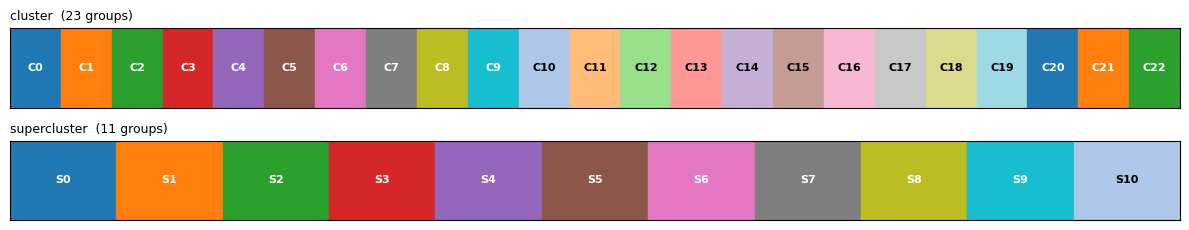

[COLOURS] 23 clusters, 11 superclusters — single registry installed.


In [42]:
# ===============================================================
#  CELL 0 — COLOUR REGISTRY (single source of truth)
#  Run BEFORE all plots.
# ===============================================================
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ===============================================================
#  CELL A — Extraction of the results for the selected window
#  ⚠ MUST run BEFORE CELL 0 (which needs n_clusters)
# ===============================================================
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

df              = results[SELECTED_WINDOW]["df"].copy()
X_scaled        = results[SELECTED_WINDOW]["X"]
Z               = results[SELECTED_WINDOW]["Z"]
n_clusters      = results[SELECTED_WINDOW]["n_clusters"]
n_superclusters = results[SELECTED_WINDOW]["n_superclusters"]

print(f"[DATA] smooth={SELECTED_WINDOW} | {len(df)} rows | "
      f"{n_clusters} clusters | {n_superclusters} superclusters | "
      f"Z {Z.shape}")

# Check: labels must cover 0..n-1 without gaps, otherwise the
# colours (indexed by label) and the counters get shifted.
for col, n in [("cluster", n_clusters), ("supercluster", n_superclusters)]:
    if col in df.columns:
        seen = sorted(pd.to_numeric(df[col], errors="coerce").dropna().unique().astype(int))
        missing_labels = sorted(set(range(n)) - set(seen))
        extra  = sorted(set(seen) - set(range(n)))
        status_str = "OK" if not (missing_labels or extra) else f"missing={missing_labels} out_of_range={extra}"
        print(f"  {col:<13} : {len(seen)} labels present — {status_str}")

def build_color_registry(n_clusters, n_superclusters):
    """
    Builds ONE colour table, then derives everything else from it
    (cmap, norm, hex list). The two cannot diverge:
    the cmap is literally built from the list.
    """
    # 20 well-separated colours: the 10 of tab10 first
    # (the most distinct), then the 10 light variants of tab20.
    tab10 = [mcolors.to_hex(plt.get_cmap("tab10")(i)) for i in range(10)]
    tab20 = plt.get_cmap("tab20")
    light_colors = [mcolors.to_hex(tab20(i)) for i in range(1, 20, 2)]
    BASE = tab10 + light_colors                      # 20 colours, optimal order

    def _color_list(n):
        return [BASE[i % len(BASE)] for i in range(max(1, int(n)))]

    def _cmap_norm(colors):
        cmap = mcolors.ListedColormap(colors)
        # bounds at -0.5, 0.5, 1.5… -> each integer falls at the CENTRE of its bin
        norm = mcolors.BoundaryNorm(np.arange(len(colors) + 1) - 0.5,
                                    ncolors=len(colors))
        return cmap, norm

    reg = {}
    for key, n, pfx in [("cluster", n_clusters, "C"),
                        ("supercluster", n_superclusters, "S")]:
        cols = _color_list(n)
        cmap, norm = _cmap_norm(cols)
        reg[key] = {"colors": cols, "cmap": cmap, "norm": norm, "prefix": pfx}
    return reg


COLOR_REG = build_color_registry(n_clusters, n_superclusters)

# ── Backward-compatible aliases: your old code keeps working ────────
CMAP_CLUSTER = COLOR_REG["cluster"]["cmap"]
NORM_CLUSTER = COLOR_REG["cluster"]["norm"]
CMAP_SUPER   = COLOR_REG["supercluster"]["cmap"]
NORM_SUPER   = COLOR_REG["supercluster"]["norm"]
PALETTE      = COLOR_REG["cluster"]["colors"]        # used by the viewer
SUPER_PAL    = COLOR_REG["supercluster"]["colors"]   # used by the viewer


# ── THE ONLY 4 FUNCTIONS TO USE IN PLOTS ────────────────────
def group_color(label, group_col="cluster"):
    """Hex colour of a label. Use EVERYWHERE, no exceptions."""
    d = COLOR_REG[group_col]
    return d["colors"][int(label) % len(d["colors"])]


def group_prefix(group_col="cluster"):
    return COLOR_REG[group_col]["prefix"]


def group_cmap_norm(group_col="cluster"):
    d = COLOR_REG[group_col]
    return d["cmap"], d["norm"]


def group_handles(labels, group_col="cluster", lw=3, style="line"):
    """Handles ready to pass to ax.legend(handles=...)."""
    uniq = sorted({int(x) for x in np.asarray(labels).ravel()})
    pfx  = group_prefix(group_col)
    if style == "patch":
        return [Patch(color=group_color(l, group_col), label=f"{pfx}{l}") for l in uniq]
    return [Line2D([0], [0], color=group_color(l, group_col), lw=lw, label=f"{pfx}{l}")
            for l in uniq]


def preview_colors():
    """Control swatch: look at it once to validate visually."""
    fig, axes = plt.subplots(2, 1, figsize=(12, 2.4))
    for ax, key in zip(axes, ["cluster", "supercluster"]):
        cols = COLOR_REG[key]["colors"]
        for i, c in enumerate(cols):
            ax.add_patch(mpl.patches.Rectangle((i, 0), 1, 1, color=c))
            ax.text(i + 0.5, 0.5, f"{COLOR_REG[key]['prefix']}{i}",
                    ha="center", va="center", fontsize=8,
                    color="white" if i % 20 < 10 else "black", fontweight="bold")
        ax.set_xlim(0, len(cols)); ax.set_ylim(0, 1)
        ax.set_yticks([]); ax.set_xticks([])
        ax.set_title(f"{key}  ({len(cols)} groups)", fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

def build_animal_colors(animal_ids, cmap_name="hsv"):
    """
    Stable colour per individual. Sorting guarantees that an animal's
    colour does NOT depend on the order in which the IDs arrive:
    same result from one run to the next.
    """
    ids = sorted({str(a).strip() for a in animal_ids}, key=natural_key)
    cm  = plt.get_cmap(cmap_name)
    COLOR_REG["animal"] = {
        "colors": {a: mcolors.to_hex(cm(i / max(1, len(ids))))
                   for i, a in enumerate(ids)},
        "prefix": "",
    }
    return COLOR_REG["animal"]["colors"]


def animal_color(aid):
    """Colour of an individual — tolerates str/int/leading zeros."""
    return COLOR_REG.get("animal", {}).get("colors", {}) \
                    .get(str(aid).strip(), "#888888")


def text_on(bg_color):
    """
    Black or white depending on the perceived luminance of the background (ITU-R BT.601).
    Avoids unreadable white text on the light tab20 shades.
    """
    r, g, b = mcolors.to_rgb(bg_color)
    return "black" if (0.299 * r + 0.587 * g + 0.114 * b) > 0.55 else "white"


def resolve_animal_id(df, raw, id_col="animal_id"):
    """
    Input -> EXACT value present in df[id_col].
    Centralised here because used by the viewer, the trajectory AND the UMAP.
    """
    vals = df[id_col].dropna().unique()
    s    = str(raw).strip()
    for v in vals:
        if str(v).strip() == s:
            return v
    try:
        num = float(s)
        for v in vals:
            try:
                if float(str(v).strip()) == num:
                    return v
            except ValueError:
                pass
    except ValueError:
        pass
    return None


def natural_key(a):
    """
    Sorts 2 before 10 (and not the reverse), tolerates text IDs.
    The tuple avoids a TypeError on mixed types: numeric values
    come first (rank 0), the others next in alphabetical order.
    """
    s = str(a).strip()
    try:
        return (0, float(s), "")
    except ValueError:
        return (1, 0.0, s)


build_animal_colors(df["animal_id"].dropna().unique())
animal_ids = sorted(df["animal_id"].dropna().unique(), key=natural_key)
n_animals  = len(animal_ids)
animal_colors_per_point = df["animal_id"].map(animal_color).to_numpy()
print(f"[COLOURS] + {n_animals} individuals registered in the registry.")

preview_colors()
print(f"[COLOURS] {n_clusters} clusters, {n_superclusters} superclusters — "
      f"single registry installed.")

In [43]:
df              = results[SELECTED_WINDOW]["df"].copy()
X_scaled        = results[SELECTED_WINDOW]["X"]
Z               = results[SELECTED_WINDOW]["Z"]
n_clusters      = results[SELECTED_WINDOW]["n_clusters"]
n_superclusters = results[SELECTED_WINDOW]["n_superclusters"]

animal_ids  = sorted(df["animal_id"].unique())
n_animals   = len(animal_ids)
id_to_idx   = {aid: i for i, aid in enumerate(animal_ids)}

def animal_color(aid):
    return plt.cm.hsv(id_to_idx[aid] / n_animals)

animal_colors_per_point = [animal_color(aid) for aid in df["animal_id"]]

norm_cl = NORM_CLUSTER
norm_su = mpl.colors.BoundaryNorm(range(n_superclusters + 1), ncolors=n_superclusters)

print(f"[OK] Smoothing={SELECTED_WINDOW} | {n_clusters} clusters | {n_superclusters} superclusters")
print(f"     {n_animals} individuals | {len(df)} frames")

[OK] Smoothing=1 | 23 clusters | 11 superclusters
     200 individuals | 90274 frames


## SeqVec strategy explorer  (`"explorer"` in `TOOLS`)
⚠️ Running the explorer **recomputes** the groups and replaces `final_state` in memory
(not the saved session).

In [44]:
import io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.widgets import Button, Slider, TextBox
from collections import Counter
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler


# ── Sequence extraction ──────────────────────────────────
def _extract_sequences(df, cluster_col, min_run_len):
    sequences, mono_ids, multi_ids = {}, [], []
    for aid, group in df.groupby("animal_id"):
        raw = group.sort_values("frame")[cluster_col].values
        blocks, lengths = [], []
        cur, start = raw[0], 0
        for i in range(1, len(raw)):
            if raw[i] != cur:
                blocks.append(int(cur)); lengths.append(i - start)
                cur, start = raw[i], i
        blocks.append(int(cur)); lengths.append(len(raw) - start)
        fb, fl = [], []
        for b, l in zip(blocks, lengths):
            if l >= min_run_len:
                if fb and fb[-1] == b: fl[-1] += l
                else: fb.append(b); fl.append(l)
        sequences[aid] = {"seq": fb, "lengths": fl,
                          "total": len(raw)}       # real duration (frames), short segments included
        (mono_ids if len(set(fb)) <= 1 else multi_ids).append(aid)
    return sequences, mono_ids, multi_ids


# ── State similarity, alignment and dynamics ───────────────
try:
    from numba import njit
except ImportError:                       # no numba: pure Python version (slower)
    def njit(*a, **k):
        return a[0] if a and callable(a[0]) else (lambda f: f)


def _state_kernel_half(state_dist):
    """Square root of the state similarity K = exp(-d²/2σ²), σ = median(d)/2.
    v @ K½ makes the Euclidean distance "soft": two close states
    (neighbouring prototypes) count as similar."""
    d = np.asarray(state_dist, float)
    sigma = np.median(d[d > 0]) / 2 if (d > 0).any() else 1.0
    K = np.exp(-d ** 2 / (2 * sigma ** 2))
    ev, evec = np.linalg.eigh(K)
    return evec @ np.diag(np.sqrt(np.clip(ev, 0, None))) @ evec.T


@njit(cache=False)
def _align_cost(a, b, sub, gap):
    """Global alignment (Needleman-Wunsch) of two state sequences.
    Substitution = distance between prototypes (0..1), insertion/deletion = gap.
    Normalised by the length of the longest sequence."""
    n, m = len(a), len(b)
    prev = np.empty(m + 1)
    for j in range(m + 1):
        prev[j] = j * gap
    for i in range(1, n + 1):
        cur = np.empty(m + 1)
        cur[0] = i * gap
        for j in range(1, m + 1):
            c = prev[j - 1] + sub[a[i - 1], b[j - 1]]
            if prev[j] + gap < c:
                c = prev[j] + gap
            if cur[j - 1] + gap < c:
                c = cur[j - 1] + gap
            cur[j] = c
        prev = cur
    return prev[m] / max(n, m, 1)


@njit(cache=False)
def _dtw_cost(x, y, radius):
    """Multivariate DTW (time × features) with a Sakoe-Chiba band:
    compares how the features evolve while tolerating a slight time shift."""
    n, m = x.shape[0], y.shape[0]
    D = np.full((n + 1, m + 1), 1e18)
    D[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(max(1, i - radius), min(m, i + radius) + 1):
            d = 0.0
            for k in range(x.shape[1]):
                d += (x[i - 1, k] - y[j - 1, k]) ** 2
            best = D[i - 1, j - 1]
            if D[i - 1, j] < best:
                best = D[i - 1, j]
            if D[i, j - 1] < best:
                best = D[i, j - 1]
            D[i, j] = np.sqrt(d) + best
    return D[n, m]


def _pairwise(items, fn, *args):
    n = len(items)
    M = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            M[i, j] = M[j, i] = fn(items[i], items[j], *args)
    return M


# ── SeqVec ────────────────────────────────────────────────────
#   Each individual is described by 9 families, each answers one question:
#     hist     : how much time in each state?
#     temporal : which states in the 1st vs 2nd half (approach -> before the strike)?
#     lastapp  : which states just before the strike? (last appearance of each state)
#     duration : total duration of the sequence (1 column, log)
#     align    : is the order of the states similar? (close states = cheap substitution)
#     dynamics : do the features evolve the same way? (DTW on the features, without the states)
#     speed    : mean speed of the cuttlefish (1 column, log); with duration = distance travelled
#     path     : total distance travelled by the cuttlefish (mm, 1 column, log): did it move a lot?
#     start    : distance to the prey at the START of the sequence (mm, 1 column, log): does it start close?
#   Distance: D² = Σ_f w_f · (D_f / scale_f)² -> each family weighs w_f / Σw,
#   whatever its number of columns.
def _seqvec(sequences, ids, n_cl,
            w_hist=1.0, w_temporal=1.0, w_lastapp=1.0, w_duration=0.5, w_align=1.0,
            w_dynamics=1.0, w_speed=0.5, w_path=0.5, w_start=0.5, state_similarity=True,
            state_dist=None, align_gap=0.5, series=None, speed=None, path=None, start=None):

    def feat_hist(s, l, n):
        # share of time in each state (log1p: compresses extreme dominances)
        c = Counter()
        for cl, ln in zip(s, l):
            c[cl] += ln
        raw = np.array([c.get(i, 0) / sum(l) for i in range(n)])
        return np.log1p(raw * 10) / np.log1p(10)

    def feat_temporal(s, l, n):
        # share of time in each state in the 1st half (t1), 2nd half (t2)
        # and their difference (t2 - t1 > 0: state more present before the strike)
        total, half = sum(l), sum(l) / 2
        h1, h2, cum = np.zeros(n), np.zeros(n), 0
        for cl, ln in zip(s, l):
            if cl < n:
                in_h1 = max(0, min(ln, half - cum))
                h1[cl] += in_h1
                h2[cl] += ln - in_h1
            cum += ln
        t1, t2 = h1 / (half + 1e-9), h2 / (half + 1e-9)
        return np.concatenate([t1, t2, t2 - t1])

    def feat_lastapp(s, n):
        # presence (0/1) + position of the LAST appearance of each state
        # (1.0 = it is the final state, just before the strike)
        present, position = np.zeros(n), np.full(n, 0.5)
        for i in range(n):
            if i in s:
                present[i]  = 1.0
                position[i] = (len(s) - 1 - s[::-1].index(i)) / max(len(s) - 1, 1)
        return np.concatenate([present, position])

    # ── Raw vectors, grouped by family ────────────────────
    fam_sizes = {"hist": n_cl, "temporal": 3 * n_cl, "lastapp": 2 * n_cl, "duration": 1, "speed": 1, "path": 1,
                 "start": 1}
    weights   = {"hist": w_hist, "temporal": w_temporal, "lastapp": w_lastapp,
                 "duration": w_duration, "speed": w_speed if speed else 0.0,
                 "path": w_path if path else 0.0, "start": w_start if start else 0.0}
    blocks    = {f: [] for f in fam_sizes}
    for aid in ids:
        s, l = sequences[aid]["seq"], sequences[aid]["lengths"]
        if not s:                                   # empty sequence -> zero vector
            for f, k in fam_sizes.items():
                blocks[f].append(np.zeros(k))
            continue
        blocks["hist"].append(feat_hist(s, l, n_cl))
        blocks["temporal"].append(feat_temporal(s, l, n_cl))
        blocks["lastapp"].append(feat_lastapp(s, n_cl))
        # real duration of the sequence (not only the segments kept by min_run_len)
        blocks["duration"].append(np.array([np.log(sequences[aid].get("total", sum(l)))]))   # log: 100 -> 200 f = 1000 -> 2000 f
        blocks["speed"].append(np.array([np.log1p(speed.get(aid, 0.0)) if speed else 0.0]))   # mm/s, log
        blocks["path"].append(np.array([np.log1p(path.get(aid, 0.0)) if path else 0.0]))     # mm, log
        blocks["start"].append(np.array([np.log1p(start.get(aid, 0.0)) if start else 0.0]))   # mm, log
    blocks = {f: np.array(v, dtype=float) for f, v in blocks.items()}

    # ── Close states = similar ("soft" hist and temporal) ──
    if state_similarity and state_dist is not None:
        Kh = _state_kernel_half(state_dist)[:n_cl, :n_cl]
        blocks["hist"] = blocks["hist"] @ Kh
        blocks["temporal"] = (blocks["temporal"].reshape(len(ids), 3, n_cl) @ Kh
                              ).reshape(len(ids), 3 * n_cl)

    # ── Combination: each family brought to the same scale ─
    parts, used = [], {}
    for f in fam_sizes:
        if weights[f] <= 0:
            continue
        Xf = StandardScaler().fit_transform(blocks[f])
        scale = np.sqrt(np.mean(pdist(Xf) ** 2)) if len(Xf) > 1 else 0.0
        if scale < 1e-9:     # tolerance: a constant family varies by ~1e-15 (rounding)                              # constant family: adds nothing
            continue
        parts.append(Xf * np.sqrt(weights[f]) / scale)
        used[f] = weights[f]
    X  = np.hstack(parts) if parts else np.zeros((len(ids), 0))
    D2 = squareform(pdist(X)) ** 2 if parts else np.zeros((len(ids), len(ids)))

    # ── align: alignment distance of the state sequences ──────
    if w_align > 0:
        if state_dist is None:
            raise ValueError("w_align > 0 requires state_dist (provided by show_strategy_explorer)")
        sub = np.asarray(state_dist, float)[:n_cl, :n_cl]
        sub = sub / (sub.max() + 1e-12)
        sq  = [np.asarray(sequences[a]["seq"], dtype=np.int64) for a in ids]
        Da  = _pairwise(sq, _align_cost, sub, float(align_gap))
        sc  = np.sqrt(np.mean(Da[np.triu_indices(len(ids), 1)] ** 2))
        if sc > 1e-9:
            D2 += w_align * (Da / sc) ** 2
            used["align"] = w_align

    # ── dynamics: DTW on the feature series (N_DYN points per individual) ──
    if w_dynamics > 0:
        if series is None:
            raise ValueError("w_dynamics > 0 requires series (provided by show_strategy_explorer)")
        ser = [np.ascontiguousarray(series[a], dtype=float) for a in ids]
        rad = max(1, int(0.1 * ser[0].shape[0]))          # tolerated shift: 10 % of the time
        Dd  = _pairwise(ser, _dtw_cost, rad)
        sc  = np.sqrt(np.mean(Dd[np.triu_indices(len(ids), 1)] ** 2))
        if sc > 1e-9:
            D2 += w_dynamics * (Dd / sc) ** 2
            used["dynamics"] = w_dynamics

    if not used:
        raise ValueError("All SeqVec weights are 0 (or constant families).")
    D   = np.sqrt(D2)
    tot = sum(used.values())
    print("[SEQVEC] mean share of each family in D² : " +
          " | ".join(f"{f} {w / tot:.0%}" for f, w in used.items()))
    desc = f"SeqVec ({', '.join(used)})"
    print(f"[SEQVEC] {len(ids)} individuals | {desc}")
    return X, D, desc
# ── Hierarchical clustering ───────────────────────────────────
def _cluster_hier(D, ids, n_strat, linkage_method="ward"):
    Z      = linkage(squareform(np.clip(D, 0, None)), method=linkage_method)
    labels = fcluster(Z, n_strat, criterion="maxclust")
    n2l    = {n: str(i) for i, n in enumerate(sorted(set(labels)))}
    return {aid: n2l[lab] for aid, lab in zip(ids, labels)}, Z


def _ward_stability(D, k, linkage_method="ward", n_boot=30, seed=0):
    """Group stability: remove 20 % of the individuals, redo the
    clustering and measure the agreement (ARI) with the full clustering."""
    from sklearn.metrics import adjusted_rand_score
    cut = lambda M: fcluster(linkage(squareform(np.clip(M, 0, None), checks=False),
                                     method=linkage_method), k, criterion="maxclust")
    rng, full, aris = np.random.default_rng(seed), cut(D), []
    for _ in range(n_boot):
        sub = np.sort(rng.choice(len(D), int(.8 * len(D)), replace=False))
        aris.append(adjusted_rand_score(full[sub], cut(D[np.ix_(sub, sub)])))
    return float(np.mean(aris))


def _silhouette_optimal_k(D, k_range=range(2, 13), linkage_method="ward"):
    """K that maximises the silhouette of the hierarchical clustering on D.
    Silhouette: is each individual closer to its own group than to the
    neighbouring group? (1 = clean groups, 0 = overlap)."""
    from sklearn.metrics import silhouette_score
    Zl  = linkage(squareform(np.clip(D, 0, None), checks=False), method=linkage_method)
    res = {}
    print("[SILHOUETTE] K tested (Ward) :")
    for k in k_range:
        if k >= len(D):
            break
        lab = fcluster(Zl, k, criterion="maxclust")
        if len(set(lab)) < 2:
            continue
        res[k] = silhouette_score(D, lab, metric="precomputed")
        print("   K={k:<3} silhouette {s:+.3f} | smallest group {m}".format(k=k, s=res[k], m=int(np.bincount(lab)[1:].min())))
    k_best = max(res, key=res.get)
    print(f"[SILHOUETTE] K selected : {k_best}")
    return k_best, res


# ── Leiden to estimate the optimal K ────────────────────────────
def _leiden_optimal_k(D, ids, resolution_range=None):
    try:
        import igraph as ig
        import leidenalg
    except ImportError:
        print("[WARN] igraph/leidenalg not available")
        return None, {}
    n = len(ids)
    if n < 3: return None, {}
    D_max = D.max()
    if D_max == 0: return 1, {}
    sim       = 1 - D / D_max
    threshold = np.percentile(sim[sim > 0], 50)
    edges, weights = [], []
    for i in range(n):
        for j in range(i+1, n):
            if sim[i, j] > threshold:
                edges.append((i, j)); weights.append(float(sim[i, j]))
    if not edges: return 1, {}
    g = ig.Graph(n=n, edges=edges)
    g.es["weight"] = weights
    if resolution_range is None:
        resolution_range = [0.5, 0.8, 0.9, 1.0, 1.1, 1.2, 1.5, 2.0]
    results = {}
    for res in resolution_range:
        part = leidenalg.find_partition(
            g, leidenalg.RBConfigurationVertexPartition,
            weights="weight", resolution_parameter=res, seed=42)
        # standard modularity (comparable across resolutions, unlike
        # part.quality() which drops mechanically as the resolution rises)
        results[res] = {"k": len(set(part.membership)),
                        "modularity": g.modularity(part.membership, weights="weight")}
    ok = {r: v for r, v in results.items() if v["k"] >= 2}   # at least 2 groups
    if not ok: return 1, results
    best_res  = max(ok, key=lambda r: ok[r]["modularity"])
    k_optimal = results[best_res]["k"]
    print(f"\n[LEIDEN] optimal K = {k_optimal} (resolution={best_res:.2f})")
    for res, r in results.items():
        print(f"  res={res:.2f} → K={r['k']} modularity={r['modularity']:.3f}")
    return k_optimal, results


def _leiden_knn_groups(D, ids, knn_k=10, min_size=3,
                       resolutions=(0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.5)):
    """Groups = Leiden communities on the graph of the knn_k nearest neighbours.
    knn_k = number of NEIGHBOURS per individual (NOT the number of groups):
    Leiden decides the number of groups itself (resolution with the best modularity).
    Groups with < min_size individuals are attached to the closest group.
    Tested (test_k_methods.py): best method on synthetic and real data."""
    import igraph as ig
    import leidenalg
    n   = len(ids)
    sim = 1 - D / (D.max() + 1e-12)
    nn  = np.argsort(D, axis=1)[:, 1:knn_k + 1]
    edges = sorted({(min(i, j), max(i, j)) for i in range(n) for j in nn[i]})
    w = [float(sim[i, j]) for i, j in edges]
    g = ig.Graph(n=n, edges=edges)
    best, best_q, best_res = None, -np.inf, None
    for res in resolutions:
        p = leidenalg.find_partition(g, leidenalg.RBConfigurationVertexPartition,
                                     weights=w, resolution_parameter=res, seed=42)
        mem = np.array(p.membership)
        if len(set(mem)) < 2:
            continue
        q = g.modularity(mem, weights=w)
        if q > best_q:
            best, best_q, best_res = mem, q, res
    if best is None:
        return {a: "0" for a in ids}, 1
    lab = best.copy()
    while True:                                  # attach the small groups
        sizes = pd.Series(lab).value_counts()
        small, big = sizes[sizes < min_size].index, sizes[sizes >= min_size].index
        if len(small) == 0 or len(big) == 0:
            break
        for i in np.where(np.isin(lab, small))[0]:
            lab[i] = min(big, key=lambda c: D[i, lab == c].mean())
    order = pd.Series(lab).value_counts().index          # 0 = largest group
    l2s   = {c: str(r) for r, c in enumerate(order)}
    print(f"[LEIDEN kNN] {knn_k} neighbours | resolution {best_res} | modularity {best_q:.3f} "
          f"| {len(order)} groups")
    return {a: l2s[c] for a, c in zip(ids, lab)}, len(order)


def _knn_stability(D, knn_k=10, n_boot=30, seed=0):
    """Stability: remove 20 % of the individuals, redo the kNN groups and
    measure the agreement (ARI) with the full groups (> 0.75 good, < 0.5 fragile)."""
    from sklearn.metrics import adjusted_rand_score
    ids = list(range(len(D)))
    with contextlib.redirect_stdout(io.StringIO()):
        full = _leiden_knn_groups(D, ids, knn_k)[0]
        rng, aris = np.random.default_rng(seed), []
        for _ in range(n_boot):
            sub = np.sort(rng.choice(len(D), int(.8 * len(D)), replace=False))
            part = _leiden_knn_groups(D[np.ix_(sub, sub)], list(sub), knn_k)[0]
            aris.append(adjusted_rand_score([full[i] for i in sub], [part[i] for i in sub]))
    return float(np.mean(aris))


# ── Main window ────────────────────────────────────────
def show_strategy_explorer(
    df,
    cluster_col    = "cluster",
    n_strategies   = 4,
    min_run_len      = 3,
    use_leiden_k   = False,
    k_method       = None,            # "knn" (recommended) | "leiden" | "silhouette" | a number
    knn_k          = 10,              # k_method='knn': number of NEIGHBOURS per individual (not the number of groups)
    k_range        = range(2, 13),    # K tested by k_method='silhouette'
    linkage_method = "ward",
    # ── SeqVec: weights of the 9 families (see _seqvec) ──
    w_hist     = 1.0,     # time spent in each state
    w_temporal = 1.0,     # states at the start vs end of the sequence
    w_lastapp  = 1.0,     # states just before the strike
    w_duration = 0.5,     # total duration (1 column)
    w_align    = 1.0,     # order of the states (alignment)
    w_dynamics = 1.0,     # evolution of the features (DTW), without the states
    w_speed    = 0.5,     # mean speed (1 column); with duration = distance travelled
    w_path     = 0.5,     # total distance travelled (1 column)
    w_start    = 0.5,     # start distance to the prey (1 column): separates close-range strikes
    state_similarity = True,   # close states = similar
    features   = None,
):
    df = df.copy()
    df["animal_id"] = df["animal_id"].astype(str)

    # ── SeqVec inputs: state prototypes + feature series ──
    feats  = list(features) if features is not None else list(FEATURES)
    fw     = globals().get("FEATURE_WEIGHTS", {}) or {}
    zs_all = pd.DataFrame(((df[feats] - df[feats].mean()) / df[feats].std()).values
                          * np.array([fw.get(f, 1.0) for f in feats]), index=df.index)
    seqvec_inputs = {}
    N_DYN = 50          # points per individual for the DTW (duration is in the duration family)

    def _seqvec_inputs(col, n_cl):
        # state prototype = centroid in the standardised + weighted space
        cent = zs_all.groupby(df[col].values).mean().reindex(range(n_cl)).fillna(0).values
        # series of each individual: N_DYN successive means (normalised time)
        ser = {}
        for aid, g in df.groupby("animal_id"):
            v = zs_all.loc[g.sort_values("frame").index].values
            e = np.linspace(0, len(v), N_DYN + 1).astype(int)
            ser[aid] = np.vstack([v[e[i]:max(e[i + 1], e[i] + 1)].mean(0) for i in range(N_DYN)])
        # mean speed of each individual (speed family)
        spd = (df.groupby("animal_id")[SPEED_COL].mean().to_dict()
               if SPEED_COL in df.columns else None)
        # total distance travelled by each individual (path family, mm)
        pth = ((df.groupby("animal_id")[SPEED_COL].sum() / 60).to_dict()
               if SPEED_COL in df.columns else None)
        # distance to the prey at the start of the sequence (start family, mm)
        st0 = (df.sort_values("frame").groupby("animal_id")["distance_mm"].first().to_dict()
               if "distance_mm" in df.columns else None)
        return {"state_dist": squareform(pdist(cent)), "state_similarity": state_similarity,
                "series": ser,
                "speed": spd,
                "path": pth,
                "start": st0}

    def compute_all(col, n_s):
        n_cl = int(df[col].nunique())
        seqs, mono, multi = _extract_sequences(df, col, min_run_len)
        print(f"[INFO] {len(multi)} multi | {len(mono)} mono | n_cl={n_cl}")
        if len(multi) < 2:
            return seqs, mono, multi, None, None, {}, n_cl, "—", n_s
        seqvec_inputs.clear()
        seqvec_inputs.update(_seqvec_inputs(col, n_cl))
        X, D, desc = _seqvec(
            seqs, multi, n_cl,
            w_hist=w_hist, w_temporal=w_temporal, w_lastapp=w_lastapp,
            w_duration=w_duration, w_align=w_align, w_dynamics=w_dynamics,
            w_speed=w_speed, w_path=w_path, w_start=w_start, **seqvec_inputs,
        )
        method = (k_method if k_method is not None
                  else ("leiden" if use_leiden_k else n_s))
        if method == "knn":
            strat, n_s = _leiden_knn_groups(D, multi, knn_k)
            Z    = linkage(squareform(np.clip(D, 0, None), checks=False), method=linkage_method)  # dendrogram
            stab = _knn_stability(D, knn_k)
            print(f"[STABILITY] K={n_s} : bootstrap ARI {stab:.2f} (> 0.75 good, < 0.5 fragile)")
            print(f"[CLUSTER] {Counter(strat.values())} | {desc}")
            return seqs, mono, multi, D, Z, strat, n_cl, desc, n_s
        if method == "leiden":
            k_opt, _ = _leiden_optimal_k(D, multi)
            if k_opt is not None:
                n_s = k_opt
                print(f"[LEIDEN] K selected : {n_s}")
        elif method == "silhouette":
            n_s, _ = _silhouette_optimal_k(D, k_range, linkage_method)
        else:
            try:
                n_s = int(method)
            except (TypeError, ValueError):
                raise ValueError(f"k_method must be 'knn', 'leiden', 'silhouette' or a number (got {k_method!r})")
            if k_method is not None:
                print(f"[K] set by hand : {n_s}")
        strat, Z = _cluster_hier(D, multi, n_s, linkage_method)
        stab = _ward_stability(D, n_s, linkage_method)
        print(f"[STABILITY] K={n_s} : bootstrap ARI {stab:.2f} (> 0.75 good, < 0.5 fragile)")
        print(f"[CLUSTER] {Counter(strat.values())} | {desc}")
        return seqs, mono, multi, D, Z, strat, n_cl, desc, n_s

    seqs, mono, multi, D, Z, strat, n_cl, desc, n_s_eff = compute_all(
        cluster_col, n_strategies)

    cur = {"col": cluster_col, "n_s": n_s_eff,
           "seqs": seqs, "mono": mono, "multi": multi,
           "D": D, "Z": Z, "strat": strat, "n_cl": n_cl, "desc": desc}

    # ── Figure ────────────────────────────────────────────────
    fig = plt.figure(figsize=(24, 12))
    fig.patch.set_facecolor("#1a1a2e")

    ax_dend = fig.add_axes([0.02, 0.22, 0.19, 0.72])
    ax_heat = fig.add_axes([0.23, 0.22, 0.19, 0.72])
    ax_seq  = fig.add_axes([0.45, 0.60, 0.53, 0.34])
    zone_r  = [0.45, 0.22, 0.53, 0.34]

    for ax in [ax_dend, ax_heat, ax_seq]:
        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        ax.tick_params(colors="#555555", labelsize=7)

    ax_s_k   = fig.add_axes([0.02, 0.11, 0.19, 0.03])
    ax_info  = fig.add_axes([0.02, 0.03, 0.60, 0.05])
    ax_tb    = fig.add_axes([0.66, 0.11, 0.14, 0.04])
    ax_bshow = fig.add_axes([0.81, 0.11, 0.08, 0.04])
    ax_bleid = fig.add_axes([0.66, 0.04, 0.23, 0.04])

    slider   = Slider(ax_s_k, "K groups", 2,
                      max(3, min(12, len(multi)-1) if len(multi) > 2 else 12),
                      valinit=n_s_eff, valstep=1, color="#4466aa")
    textbox  = TextBox(ax_tb,    "Animal ID: ", initial="",
                       color="#111122", hovercolor="#1a1a2e")
    btn_show = Button(ax_bshow, "Show",  color="#224422", hovercolor="#336633")
    btn_leid = Button(ax_bleid, "Leiden kNN groups",
                      color="#442244", hovercolor="#663366")

    for btn in [btn_show, btn_leid]:
        btn.label.set_color("#cccccc"); btn.label.set_fontsize(9)
    slider.label.set_color("white"); slider.valtext.set_color("white")
    textbox.label.set_color("#aaaaaa"); textbox.text_disp.set_color("#ffffff")

    ax_info.axis("off")
    info_txt = ax_info.text(
        0, 0.5,
        f"col={cluster_col} | seqvec | min_run_len={min_run_len} | "
        f"K={n_s_eff} | {len(multi)} multi + {len(mono)} MONO",
        color="#888888", fontsize=8, va="center",
        transform=ax_info.transAxes, fontfamily="monospace")

    radar_axes = []

    def remove_radars():
        for ax in radar_axes: ax.remove()
        radar_axes.clear()

    def update_info():
        info_txt.set_text(
            f"col={cur['col']} | seqvec | min_run_len={min_run_len} | "
            f"K={cur['n_s']} | {len(cur['multi'])} multi + {len(cur['mono'])} MONO")

    def draw():
        seqs  = cur["seqs"]; mono  = cur["mono"]; multi = cur["multi"]
        D     = cur["D"];    Z     = cur["Z"];    strat = cur["strat"]
        n_cl  = cur["n_cl"]; n_s   = cur["n_s"]

        strategy_list = sorted(set(strat.values())) if strat else []
        pal = {s: STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
               for i, s in enumerate(strategy_list)}
        pal["MONO"] = "#666666"

        # ── Dendrogram ──────────────────────────────────────
        ax_dend.cla(); ax_dend.set_facecolor("#0d0d1a")
        for sp in ax_dend.spines.values(): sp.set_edgecolor("#333333")
        ax_dend.tick_params(colors="#555555", labelsize=6)
        if Z is not None and len(multi) > 2:
            cut_h = Z[-(n_s-1), 2]*1.01 if len(Z) >= n_s else Z[-1, 2]
            dendrogram(Z, ax=ax_dend, no_labels=True,
                       color_threshold=cut_h,
                       above_threshold_color="#444455")
            ax_dend.axhline(cut_h, color="#FFD700", lw=1.2, ls="--",
                            label=f"K={n_s}")
            ax_dend.legend(fontsize=7, labelcolor="white",
                           loc="upper right").get_frame().set_facecolor("#111111")
        ax_dend.set_title(
            f"Dendrogram\n{len(multi)} multi + {len(mono)} MONO",
            color="#aaaaaa", fontsize=8, pad=6)
        ax_dend.set_xlabel("Individuals", color="#555555", fontsize=7)
        ax_dend.set_ylabel("Distance",  color="#555555", fontsize=7)

        # ── Heatmap ───────────────────────────────────────────
        ax_heat.cla(); ax_heat.set_facecolor("#0d0d1a")
        for sp in ax_heat.spines.values(): sp.set_edgecolor("#333333")
        if D is not None and len(multi) > 0:
            sorted_ids = sorted(multi, key=lambda x: strat.get(x, "?"))
            idx_map    = {aid: i for i, aid in enumerate(multi)}
            order      = [idx_map[aid] for aid in sorted_ids]
            Ds         = D[np.ix_(order, order)]
            im = ax_heat.imshow(Ds, cmap="viridis", aspect="auto")
            ax_heat.set_xticks([]); ax_heat.set_yticks([])
            prev_s, xp = None, 0
            for aid in sorted_ids:
                s = strat.get(aid, "?")
                if s != prev_s and prev_s is not None:
                    ax_heat.axhline(xp-.5, color="white", lw=0.8, alpha=0.5)
                    ax_heat.axvline(xp-.5, color="white", lw=0.8, alpha=0.5)
                prev_s = s; xp += 1
            plt.colorbar(im, ax=ax_heat, fraction=0.03, pad=0.02,
                         label="Dist.").ax.tick_params(colors="white", labelsize=5)
        patches = ([mpatches.Patch(color=pal[s],
                    label=f"{s} (n={sum(1 for v in strat.values() if v==s)})")
                    for s in strategy_list]
                   + [mpatches.Patch(color="#666666",
                      label=f"MONO (n={len(mono)})")])
        ax_heat.legend(handles=patches, fontsize=6, loc="lower right",
                       framealpha=0.5).get_frame().set_facecolor("#111111")
        ax_heat.set_title(f"Distances\n{cur['desc'][:35]}",
                          color="#aaaaaa", fontsize=8, pad=6)

        # ── Radars ────────────────────────────────────────────
        remove_radars()
        all_s = strategy_list + (["MONO"] if mono else [])
        nc = min(5, len(all_s)); nr = (len(all_s)+nc-1)//nc
        w_r = zone_r[2]/nc; h_r = zone_r[3]/nr

        for si, s in enumerate(all_s):
            members = mono if s == "MONO" else \
                      [aid for aid, lab in strat.items() if lab == s]
            profs = []
            for aid in members:
                sq = seqs[aid]["seq"]; lng = seqs[aid]["lengths"]
                total = sum(lng)
                if total == 0: continue
                h = np.zeros(n_cl)
                for cl, l in zip(sq, lng):
                    if cl < n_cl: h[cl] += l / total
                profs.append(h)
            if not profs: continue
            mp = np.mean(profs, axis=0)
            ci = si % nc; ri = si // nc
            rect = [zone_r[0]+ci*w_r, zone_r[1]+(nr-1-ri)*h_r,
                    w_r*0.90, h_r*0.88]
            ax_r = fig.add_axes(rect, polar=True)
            ax_r.set_facecolor("#0d0d1a"); radar_axes.append(ax_r)
            angs = np.linspace(0, 2*np.pi, n_cl, endpoint=False)
            af   = np.concatenate([angs, [angs[0]]])
            vf   = np.concatenate([mp, [mp[0]]])
            col  = pal.get(s, "#888888")
            ax_r.plot(af, vf, lw=2, color=col)
            ax_r.fill(af, vf, alpha=0.3, color=col)
            ax_r.set_xticks(angs)
            ax_r.set_xticklabels([f"C{c}" for c in range(n_cl)],
                                  fontsize=4, color="#aaaaaa")
            ax_r.set_ylim(0, max(mp.max()*1.2, 0.01))
            ax_r.set_yticks([])
            ax_r.grid(color="#333333", lw=0.5)
            ax_r.spines["polar"].set_color("#333333")
            ax_r.set_title(f"{s} n={len(members)}",
                           color=col, fontsize=7, pad=4)

        fig.suptitle(
            f"Strategies | col={cur['col']} | SeqVec+ | "
            f"K={n_s} | {len(multi)} multi + {len(mono)} MONO",
            color="#cccccc", fontsize=10, y=0.99)
        update_info()
        fig.canvas.draw_idle()

    draw()

    # ── Individual timeline ─────────────────────────────────────
    def show_indiv(event=None):
        raw   = textbox.text.strip()
        seqs  = cur["seqs"]; strat = cur["strat"]
        strategy_list = sorted(set(strat.values())) if strat else []
        pal = {s: STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)]
               for i, s in enumerate(strategy_list)}
        pal["MONO"] = "#666666"

        aid = str(raw) if raw in seqs else None
        if aid is None and raw.isdigit():
            aid_int = str(int(raw))
            if aid_int in seqs: aid = aid_int

        ax_seq.cla(); ax_seq.set_facecolor("#0d0d1a")
        for sp in ax_seq.spines.values(): sp.set_edgecolor("#333333")

        if aid is None:
            sample = list(seqs.keys())[:8]
            ax_seq.text(0.5, 0.5,
                f"'{raw}' not found\nExamples : {sample}",
                ha="center", va="center", color="#ff4444",
                transform=ax_seq.transAxes, fontsize=9)
            fig.canvas.draw_idle(); return

        sq  = seqs[aid]["seq"]; lng = seqs[aid]["lengths"]
        s   = strat.get(aid, "MONO"); col = pal.get(s, "#888888")
        ax_seq.set_title(
            f"Animal {aid}  —  Strategy {s}  |  "
            f"{len(sq)} blocks, {sum(lng)} frames",
            color=col, fontsize=9)
        ax_seq.set_yticks([])
        ax_seq.tick_params(colors="#555555", labelsize=7)

        x = 0
        for cluster, length in zip(sq, lng):
            c = PALETTE[cluster % len(PALETTE)]
            ax_seq.barh(0, length, left=x, height=0.6,
                        color=c, edgecolor="#111122", lw=0.4)
            if length >= max(lng) * 0.06:
                ax_seq.text(x + length/2, 0, str(cluster),
                            ha="center", va="center",
                            fontsize=7, color="white", fontweight="bold")
            x += length

        ax_seq.set_xlim(0, x); ax_seq.set_ylim(-0.5, 0.5)
        ax_seq.set_xlabel("Frames", color="#555555", fontsize=7)
        ax_seq.grid(axis="x", alpha=0.15, color="#334455")
        patches = [mpatches.Patch(color=PALETTE[c % len(PALETTE)],
                   label=f"C{c}") for c in sorted(set(sq))]
        ax_seq.legend(handles=patches, fontsize=6, loc="upper right",
                      framealpha=0.5).get_frame().set_facecolor("#111111")
        fig.canvas.draw_idle()

    # ── Events ────────────────────────────────────────────
    def on_leiden(event):
        if cur["D"] is None: return
        print("[LEIDEN kNN] Computing...")
        strat, k_opt = _leiden_knn_groups(cur["D"], cur["multi"], knn_k)
        cur["n_s"] = k_opt
        slider.eventson = False; slider.set_val(min(k_opt, slider.valmax)); slider.eventson = True
        cur.update({"strat": strat})
        remove_radars(); draw()

    def on_slider(val):
        cur["n_s"] = int(val)
        if cur["D"] is not None:
            strat, Z = _cluster_hier(cur["D"], cur["multi"],
                                      cur["n_s"], linkage_method)
            cur.update({"strat": strat, "Z": Z})
        remove_radars(); draw()

    slider.on_changed(on_slider)
    btn_show.on_clicked(show_indiv)
    btn_leid.on_clicked(on_leiden)
    textbox.on_submit(lambda t: show_indiv())

    plt.show()

    # ── Return final_state ─────────────────────────────────
    # ── Return final_state ─────────────────────────────────
    strat_final = cur["strat"] if cur["strat"] else {}
    mono_final  = cur["mono"]

    # Convert numbers → letters (A, B, C...)
    unique_groups   = sorted(set(v for v in strat_final.values()))
    num_to_letter   = {g: chr(65+i) for i, g in enumerate(unique_groups)}
    mapping_letters = {aid: num_to_letter.get(g, "MONO")
                       for aid, g in strat_final.items()}
    for m in mono_final:
        mapping_letters[str(m)] = "MONO"

    return {
        "seqs"           : cur["seqs"],
        "strat"          : strat_final,
        "mono"           : mono_final,
        "multi"          : cur["multi"],
        "n_cl"           : cur["n_cl"],
        "col"            : cur["col"],   # ← added
        "D"              : cur["D"],
        "Z"              : cur["Z"],
        "n_s"            : cur["n_s"],
        "desc"           : cur["desc"],
        "mapping_letters": mapping_letters,
        "seqvec_inputs"  : seqvec_inputs,
        "seqvec_weights" : dict(w_hist=w_hist, w_temporal=w_temporal, w_lastapp=w_lastapp,
                                w_duration=w_duration, w_align=w_align, w_dynamics=w_dynamics,
                                w_speed=w_speed, w_path=w_path, w_start=w_start),
        "knn_k"          : knn_k,
        "min_run_len"      : min_run_len,
        }

In [45]:
if "explorer" not in TOOLS:
    print("[skip] explorer (not in TOOLS)")
else:
    get_ipython().run_line_magic("matplotlib", "qt")
    _before = set(plt.get_fignums())
    try:
        # ── Call ─────────────────────────────────────────────────────
        final_state = show_strategy_explorer(
            df             = df,
            cluster_col    = "cluster",
            n_strategies   = 4,
            min_run_len      = 15,    # segments < 15 frames (0.25 s) ignored: removes state flickering
            use_leiden_k   = True,
            k_method       = "knn",          # "knn" (Leiden on kNN graph, recommended) | "leiden" | "silhouette" | a number
            knn_k          = 10,             # number of NEIGHBOURS per individual in the graph (NOT the number of groups)
            linkage_method = "ward",
            # ── SeqVec: weights of the 9 families ──
            w_hist         = 1.0,     # time spent in each state
            w_temporal     = 1.0,     # states at the start vs end of the sequence
            w_lastapp      = 1.0,     # states just before the strike
            w_duration     = 0.5,     # total duration (1 column)
            w_align        = 1.0,     # order of the states (alignment, close states = low cost)
            w_dynamics     = 1.0,     # evolution of the features (DTW), without the states
            w_speed        = 0.5,     # mean speed of the cuttlefish (with duration = distance travelled)
            w_path         = 1.0,     # total distance travelled by the cuttlefish (did it move a lot?)
            w_start        = 1.0,     # start distance to the prey (does it start close?)
            state_similarity = True,  # close states = similar (hist, temporal)
        )
    except Exception as _e:
        print(f"[explorer] could not open: {type(_e).__name__}: {_e}")
    wait_until_closed(_before, "explorer")

[INFO] 183 multi | 17 mono | n_cl=23
[SEQVEC] mean share of each family in D² : hist 12% | temporal 12% | lastapp 12% | duration 6% | speed 6% | path 12% | start 12% | align 12% | dynamics 12%
[SEQVEC] 183 individuals | SeqVec (hist, temporal, lastapp, duration, speed, path, start, align, dynamics)
[LEIDEN kNN] 10 neighbours | resolution 0.8 | modularity 0.564 | 6 groups
[STABILITY] K=6 : bootstrap ARI 0.71 (> 0.75 good, < 0.5 fragile)
[CLUSTER] Counter({'0': 44, '1': 32, '2': 31, '3': 27, '4': 26, '5': 23}) | SeqVec (hist, temporal, lastapp, duration, speed, path, start, align, dynamics)
[explorer] window open — close it to continue
[explorer] closed


## Interactive UMAP  (`"umap"` in `TOOLS`)

In [46]:
# interactive umap plot

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.widgets import LassoSelector, Button, TextBox
from matplotlib.path import Path
from matplotlib.lines import Line2D


def plot_umap_interactive_radar(df, Z, features, n_clusters, n_superclusters,
                                 color_by="cluster"):

    state = {"color_by": color_by, "lasso_active": True}

    global_min = df[features].min().values
    global_max = df[features].max().values
    angles     = np.linspace(0, 2 * np.pi, len(features), endpoint=False)
    ang_full   = np.concatenate([angles, [angles[0]]])
    Z_pts      = np.column_stack([Z[:, 0], Z[:, 1]])

    # Everything as str to avoid type mismatches
    df = df.copy()
    df["animal_id"] = df["animal_id"].astype(str)
    animal_ids = sorted(df["animal_id"].unique())
    n_animals  = len(animal_ids)
    id_to_idx  = {aid: i for i, aid in enumerate(animal_ids)}

    def get_col_data(cb):
        if cb == "supercluster":
            return (df["supercluster"].values, plt.cm.tab10,
                    mpl.colors.BoundaryNorm(range(n_superclusters+1), ncolors=n_superclusters), "S")
        elif cb == "cluster":
            return (df["cluster"].values, CMAP_CLUSTER, NORM_CLUSTER, "C")
        else:
            col = np.array([id_to_idx[a] for a in df["animal_id"]])
            return (col, plt.cm.hsv,
                    mpl.colors.Normalize(vmin=0, vmax=n_animals), "A")

    # ── Figure ──────────────────────────────────────────────────
    fig = plt.figure(figsize=(20, 10))
    fig.patch.set_facecolor("#1a1a2e")

    ax_umap  = fig.add_axes([0.02, 0.14, 0.46, 0.82])
    ax_radar = fig.add_axes([0.52, 0.52, 0.22, 0.42], polar=True)
    ax_traj  = fig.add_axes([0.52, 0.12, 0.22, 0.36])
    ax_feats = fig.add_axes([0.76, 0.12, 0.22, 0.78])

    for ax in [ax_umap, ax_radar, ax_traj, ax_feats]:
        ax.set_facecolor("#0d0d1a")
        for spine in ax.spines.values():
            spine.set_edgecolor("#333333")
        ax.tick_params(colors="#555555", labelsize=7)

    # ── Widgets ─────────────────────────────────────────────────
    ax_btn_mode   = fig.add_axes([0.02, 0.03, 0.10, 0.06])
    ax_btn_reset  = fig.add_axes([0.13, 0.03, 0.07, 0.06])
    ax_btn_lasso  = fig.add_axes([0.21, 0.03, 0.08, 0.06])
    ax_textbox    = fig.add_axes([0.31, 0.03, 0.10, 0.06])
    ax_btn_animal = fig.add_axes([0.42, 0.03, 0.10, 0.06])

    btn_mode   = Button(ax_btn_mode,  f"Mode: {color_by}", color="#222244", hovercolor="#333366")
    btn_reset  = Button(ax_btn_reset, "Reset",             color="#222222", hovercolor="#333333")
    btn_lasso  = Button(ax_btn_lasso, "Lasso: ON",         color="#442200", hovercolor="#663300")
    textbox    = TextBox(ax_textbox,  "Animal: ",          initial="",
                         color="#0d0d1a", hovercolor="#1a1a2e")
    btn_animal = Button(ax_btn_animal,"Show",              color="#224422", hovercolor="#336633")

    for btn in [btn_mode, btn_reset, btn_lasso, btn_animal]:
        btn.label.set_color("#cccccc")
        btn.label.set_fontsize(8)
    textbox.label.set_color("#aaaaaa")
    textbox.text_disp.set_color("#ffffff")

    # ── Scatter ─────────────────────────────────────────────────
    col_data, cmap, norm_g, _ = get_col_data(state["color_by"])
    sc        = ax_umap.scatter(Z_pts[:,0], Z_pts[:,1],
                                 c=cmap(norm_g(np.asarray(col_data))),   # Colours computed in one go (vectorised): 95k calls -> 1
                                 s=4, alpha=0.7, linewidths=0, zorder=2)
    hl_lasso  = ax_umap.scatter([], [], s=20, facecolors="none",
                                 edgecolors="white", linewidths=0.7, zorder=4)
    hl_animal = ax_umap.scatter([], [], s=15, zorder=5)
    hl_click  = ax_umap.scatter([], [], s=120, marker="*",
                                 facecolors="yellow", edgecolors="white",
                                 linewidths=0.7, zorder=6)

    # Path of the individual (like plot_umap) + start / middle / end markers
    from matplotlib.collections import LineCollection
    path_lc  = LineCollection([], linewidths=1.6, alpha=0.9, zorder=4)
    ax_umap.add_collection(path_lc)
    hl_start = ax_umap.scatter([], [], marker="o", s=110, facecolor="#00e676",
                               edgecolor="black", linewidth=1.4, zorder=7)
    hl_mid   = ax_umap.scatter([], [], marker="D", s=95,  facecolor="#ffd600",
                               edgecolor="black", linewidth=1.4, zorder=7)
    hl_end   = ax_umap.scatter([], [], marker="s", s=110, facecolor="#ff1744",
                               edgecolor="black", linewidth=1.4, zorder=7)

    ax_umap.set_facecolor("#0d0d1a")
    ax_umap.set_title(f"UMAP — {state['color_by']}", color="#aaaaaa", fontsize=10)
    for spine in ax_umap.spines.values():
        spine.set_edgecolor("#333333")

    info_text = ax_umap.text(
        0.02, 0.02,
        "Lasso ON → draw | Lasso OFF → click point | Dbl-click → reset",
        transform=ax_umap.transAxes, color="#777777", fontsize=8,
        bbox=dict(facecolor="#111111", alpha=0.7, edgecolor="none", pad=3)
    )

    # ── Radar ───────────────────────────────────────────────────
    def setup_radar():
        ax_radar.cla()
        ax_radar.set_facecolor("#0d0d1a")
        ax_radar.set_xticks(angles)
        ax_radar.set_xticklabels([f.replace("_", "\n") for f in features],
                                  color="#999999", fontsize=6)
        ax_radar.set_ylim(0, 1)
        ax_radar.set_yticks([0.5])
        ax_radar.set_yticklabels(["0.5"], color="#555555", fontsize=6)
        ax_radar.grid(color="#333333", linewidth=0.5)
        ax_radar.spines["polar"].set_color("#333333")
        ax_radar.set_title("Radar", color="#aaaaaa", fontsize=9, pad=10)

    def draw_radar(norm_vals, color, title):
        setup_radar()
        vf = np.concatenate([norm_vals, [norm_vals[0]]])
        ax_radar.plot(ang_full, vf, linewidth=2, color=color)
        ax_radar.fill(ang_full, vf, alpha=0.3, color=color)
        for a, vn in zip(angles, norm_vals):
            ax_radar.text(a, min(vn + 0.15, 1.1), f"{vn:.2f}",
                          ha="center", va="center", color="#dddddd", fontsize=6,
                          bbox=dict(facecolor="#111111", alpha=0.5, edgecolor="none", pad=1))
        ax_radar.set_title(title, color="#aaaaaa", fontsize=8, pad=10)
        fig.canvas.draw_idle()

    setup_radar()

    # ── Traj + feats ────────────────────────────────────────────
    def setup_traj():
        ax_traj.cla()
        ax_traj.set_facecolor("#0d0d1a")
        ax_traj.set_title("Trajectory", color="#aaaaaa", fontsize=9)
        for spine in ax_traj.spines.values():
            spine.set_edgecolor("#333333")
        ax_traj.tick_params(colors="#555555", labelsize=7)

    def setup_feats():
        ax_feats.cla()
        ax_feats.set_facecolor("#0d0d1a")
        ax_feats.set_title("Normalised variables", color="#aaaaaa", fontsize=9)
        for spine in ax_feats.spines.values():
            spine.set_edgecolor("#333333")
        ax_feats.tick_params(colors="#555555", labelsize=7)

    setup_traj()
    setup_feats()

    # ── Lasso ───────────────────────────────────────────────────
    def on_lasso(verts):
        if not state["lasso_active"]:
            return
        # Tiny lasso = simple click -> select the nearest point
        v  = np.asarray(verts)
        xr = ax_umap.get_xlim()
        if len(v) < 3 or np.ptp(v, axis=0).max() < 0.01 * (xr[1] - xr[0]):
            _select_point(*v[-1])
            return
        lasso_path   = Path(verts)
        inside       = lasso_path.contains_points(Z_pts)
        selected_idx = np.where(inside)[0]
        n_sel        = len(selected_idx)

        if n_sel == 0:
            info_text.set_text("Empty lasso")
            hl_lasso.set_offsets(np.empty((0, 2)))
            fig.canvas.draw_idle()
            return

        hl_lasso.set_offsets(Z_pts[selected_idx])
        raw_vals  = df[features].values[selected_idx].mean(axis=0)
        norm_vals = np.clip((raw_vals - global_min)/(global_max - global_min + 1e-9), 0, 1)

        cd, cm, ng, lpfx = get_col_data(state["color_by"])
        if state["color_by"] in ("cluster", "supercluster"):
            counts   = pd.Series(cd[selected_idx]).value_counts()
            dominant = counts.idxmax()
            color    = cm(ng(dominant))
            comp     = " | ".join([f"{lpfx}{g}:{n}" for g, n in counts.items()])
        else:
            color = "#44aaff"
            comp  = f"{pd.Series(df['animal_id'].values[selected_idx]).nunique()} individuals"

        info_text.set_text(f"{n_sel} pts — {comp}")
        draw_radar(norm_vals, color, f"Lasso n={n_sel}")

    lasso_selector = LassoSelector(ax_umap, on_lasso,
                                    props=dict(color="#FFD700", linewidth=1.5),
                                    useblit=True, button=1)

    # ── Click ───────────────────────────────────────────────────
    def _select_point(x, y):
        xy   = np.array([x, y])
        dist = np.linalg.norm(Z_pts - xy, axis=1)
        idx  = int(np.argmin(dist))
        xlim = ax_umap.get_xlim()
        if dist[idx] > (xlim[1] - xlim[0]) * 0.05:
            return

        hl_click.set_offsets([Z_pts[idx]])
        raw_vals  = df[features].values[idx]
        norm_vals = np.clip((raw_vals - global_min)/(global_max - global_min + 1e-9), 0, 1)
        cd, cm, ng, lpfx = get_col_data(state["color_by"])
        color = cm(ng(cd[idx]))
        label = f"{lpfx}{cd[idx]} | animal {df['animal_id'].iloc[idx]}"
        info_text.set_text(f"Point {idx} — {label}")
        draw_radar(norm_vals, color, f"Point {idx}\n{label}")

    def on_click(event):
        if event.inaxes != ax_umap:
            return
        if event.dblclick:
            reset(None); return
        if state["lasso_active"]:
            return  # the lasso handles clicks when active
        if event.button != 1 or event.xdata is None:
            return

        _select_point(event.xdata, event.ydata)

    fig.canvas.mpl_connect("button_press_event", on_click)

    # ── Lasso ON/OFF button ─────────────────────────────────────
    # Disabling the lasso frees the clicks for the TextBox and point clicking
    def toggle_lasso(event):
        state["lasso_active"] = not state["lasso_active"]
        if state["lasso_active"]:
            lasso_selector.set_active(True)
            btn_lasso.label.set_text("Lasso: ON")
            btn_lasso.ax.set_facecolor("#442200")
            info_text.set_text("Lasso ON — draw an area")
        else:
            lasso_selector.set_active(False)
            btn_lasso.label.set_text("Lasso: OFF")
            btn_lasso.ax.set_facecolor("#004422")
            info_text.set_text("Lasso OFF — click a point | type animal_id")
        fig.canvas.draw_idle()

    btn_lasso.on_clicked(toggle_lasso)

    # ── Mode button ─────────────────────────────────────────────
    modes = ["supercluster", "cluster", "animal"]

    def toggle_mode(event):
        idx = modes.index(state["color_by"])
        state["color_by"] = modes[(idx + 1) % len(modes)]
        btn_mode.label.set_text(f"Mode: {state['color_by']}")
        cd, cm, ng, _ = get_col_data(state["color_by"])
        sc.set_facecolors(cm(ng(np.asarray(cd))))
        ax_umap.set_title(f"UMAP — {state['color_by']}", color="#aaaaaa", fontsize=10)
        fig.canvas.draw_idle()

    btn_mode.on_clicked(toggle_mode)

    # ── Reset button ────────────────────────────────────────────
    def reset(event):
        hl_lasso.set_offsets(np.empty((0, 2)))
        hl_animal.set_offsets(np.empty((0, 2)))
        hl_click.set_offsets(np.empty((0, 2)))
        path_lc.set_segments([])
        for h in (hl_start, hl_mid, hl_end):
            h.set_offsets(np.empty((0, 2)))
        if ax_umap.get_legend() is not None:
            ax_umap.get_legend().remove()
        info_text.set_text("Reset")
        setup_radar()
        ax_radar.set_title("Radar", color="#aaaaaa", fontsize=9, pad=10)
        setup_traj()
        setup_feats()
        fig.canvas.draw_idle()

    btn_reset.on_clicked(reset)

    # ── Animal button ───────────────────────────────────────────
    def show_animal(event):
        raw = textbox.text.strip()
        if not raw:
            info_text.set_text(f"Example IDs : {', '.join(animal_ids[:6])}")
            fig.canvas.draw_idle()
            return

        aid = str(raw)
        if aid not in df["animal_id"].values:
            sample = ", ".join(animal_ids[:8])
            info_text.set_text(f"'{aid}' not found. Examples : {sample}")
            fig.canvas.draw_idle()
            return

        mask = df["animal_id"].values == aid
        idx  = np.where(mask)[0]
        n_a  = len(idx)

        # Rainbow UMAP highlighting
        colors_r = plt.cm.rainbow(np.linspace(0, 1, n_a))
        hl_animal.set_offsets(Z_pts[idx])
        hl_animal.set_facecolors(colors_r)
        hl_animal.set_sizes([15] * n_a)

        # Rainbow path between the points + start / middle / end
        pts_a = Z_pts[idx]
        if n_a > 1:
            segs = np.stack([pts_a[:-1], pts_a[1:]], axis=1)
            path_lc.set_segments(segs)
            path_lc.set_color(plt.cm.rainbow(np.linspace(0, 1, len(segs))))
        else:
            path_lc.set_segments([])
        hl_start.set_offsets(pts_a[[0]])
        hl_mid.set_offsets(pts_a[[n_a // 2]])
        hl_end.set_offsets(pts_a[[-1]])
        leg = ax_umap.legend(handles=[
            Line2D([0], [0], marker="o", color="none", markerfacecolor="#00e676",
                   markeredgecolor="black", markersize=9, label="start"),
            Line2D([0], [0], marker="D", color="none", markerfacecolor="#ffd600",
                   markeredgecolor="black", markersize=8, label="middle"),
            Line2D([0], [0], marker="s", color="none", markerfacecolor="#ff1744",
                   markeredgecolor="black", markersize=9, label="end"),
        ], loc="lower right", fontsize=8, facecolor="#111111",
           edgecolor="#333333", labelcolor="#cccccc", title=f"Animal {aid}")
        leg.get_title().set_color("#cccccc")

        # Mean radar
        raw_vals  = df[features].values[mask].mean(axis=0)
        norm_vals = np.clip((raw_vals - global_min)/(global_max - global_min + 1e-9), 0, 1)
        draw_radar(norm_vals, "#44aaff", f"Animal {aid} (n={n_a})")

        # Trajectory
        setup_traj()
        cf = df[mask].reset_index(drop=True)
        cl = df["cluster"].values[mask]
        _, cm_c, ng_c, _ = get_col_data("cluster")
        # A single LineCollection instead of one plot() per segment
        tx = cf["TopMantle_x"].to_numpy(float)
        ty = cf["TopMantle_y"].to_numpy(float)
        cols_t = cm_c(ng_c(np.asarray(cl)))
        if len(cf) > 1:
            pts_t = np.column_stack([tx, ty])
            ax_traj.add_collection(LineCollection(
                np.stack([pts_t[:-1], pts_t[1:]], axis=1),
                colors=cols_t[:-1], linewidths=0.8))
        ax_traj.scatter(tx, ty, c=cols_t, s=2, linewidths=0)
        ax_traj.autoscale_view()
        ax_traj.scatter(cf["TopMantle_x"].iloc[0],  cf["TopMantle_y"].iloc[0],
                        color="lime", s=40, zorder=5)
        ax_traj.scatter(cf["TopMantle_x"].iloc[-1], cf["TopMantle_y"].iloc[-1],
                        color="white", s=40, zorder=5)
        ax_traj.invert_yaxis()
        ax_traj.set_title(f"Animal {aid}", color="#aaaaaa", fontsize=9)

        # Time features
        setup_feats()
        t = np.arange(n_a)
        for feat in features:
            fmax = cf[feat].max()
            ax_feats.plot(t, cf[feat] / (fmax + 1e-9),
                          label=feat.replace("_"," "), alpha=0.8, linewidth=1)
        ax_feats.legend(fontsize=6, loc="upper right")
        ax_feats.set_xlabel("Frame", color="#555555", fontsize=7)
        ax_feats.set_title(f"Variables — animal {aid}", color="#aaaaaa", fontsize=9)

        info_text.set_text(f"Animal {aid} — {n_a} frames")
        fig.canvas.draw_idle()

    btn_animal.on_clicked(show_animal)

    # Pressing Enter in the textbox = same effect as the button
    textbox.on_submit(lambda text: show_animal(None))

    plt.suptitle("Lasso ON/OFF | Mode | Animal ID + Enter or Show | Dbl-click → reset",
                 color="#cccccc", fontsize=9)
    plt.show()
    return fig

In [47]:
if "umap" not in TOOLS:
    print("[skip] umap (not in TOOLS)")
else:
    get_ipython().run_line_magic("matplotlib", "qt")
    _before = set(plt.get_fignums())
    try:
        plot_umap_interactive_radar(df, Z, FEATURES, n_clusters, n_superclusters,
                                     color_by="cluster")
    except Exception as _e:
        print(f"[umap] could not open: {type(_e).__name__}: {_e}")
    wait_until_closed(_before, "umap")

[umap] window open — close it to continue
[umap] closed


## 3D maps  (`"3d"` in `TOOLS`)

In [48]:
# def plot 3D
from scipy.ndimage import gaussian_filter
from scipy.interpolate import griddata

def _compute_temporal_grid(df_w, resolution=100, smoothing=5,
                            normalize_by_individual=True):
    # ── Fix: reset the index to avoid IndexErrors ──
    # When df_w is a filtered sub-DataFrame, the pandas indices
    # no longer match the positions 0..n-1
    # → reset_index() guarantees that idx goes from 0 to len(df_w)-1
    df_w = df_w.reset_index(drop=True)

    xg = df_w["umap_x"].values
    yg = df_w["umap_y"].values

    if normalize_by_individual:
        zg = np.zeros(len(df_w))
        for aid, grp in df_w.groupby("animal_id"):
            idx = grp.index   # ← these indices are now really 0..n-1
            n   = len(grp)
            if n == 1:
                zg[idx] = 1.0
            else:
                zg[idx] = 1.0 - np.arange(n) / (n - 1)
    else:
        n  = len(df_w)
        zg = 1.0 - np.arange(n) / max(n - 1, 1)

    # the rest is unchanged...
    x_min, x_max = xg.min(), xg.max()
    y_min, y_max = yg.min(), yg.max()
    margin_x = (x_max - x_min) * 0.05
    margin_y = (y_max - y_min) * 0.05

    xi = np.linspace(x_min - margin_x, x_max + margin_x, resolution)
    yi = np.linspace(y_min - margin_y, y_max + margin_y, resolution)
    Xi, Yi = np.meshgrid(xi, yi)

    pts = np.column_stack([xg, yg])
    Zi  = griddata(pts, zg, (Xi, Yi), method='linear')

    mask_nan = np.isnan(Zi)
    if mask_nan.any():
        Zi_near      = griddata(pts, zg, (Xi, Yi), method='nearest')
        Zi[mask_nan] = Zi_near[mask_nan]

    if smoothing > 0:
        Zi = gaussian_filter(Zi, sigma=smoothing)

    Zi = np.clip(Zi, 0, 1)

    return Zi, Xi, Yi, xg, yg, zg

def plot_temporal_group_overlay(Z, df, mapping_letters,
                                 group_label,
                                 smoothing=5,
                                 resolution=100,
                                 normalize_by_individual=True,
                                 colormap="RdYlGn_r",
                                 stride=2):

    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)
    df_w["umap_x"]    = Z[:, 0]
    df_w["umap_y"]    = Z[:, 1]
    df_w["group_label"]    = df_w["animal_id"].map(
        lambda a: mapping_letters.get(a, "MONO")
    )

    group_list = sorted(set(v for v in mapping_letters.values() if v != "MONO"))
    pal        = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(group_list)}
    col        = pal.get(group_label, "#4CAF50")
    n_ind      = df_w[df_w["group_label"] == group_label]["animal_id"].nunique()

    if group_label not in group_list:
        print(f"❌ Group '{group_label}' not found. Available : {group_list}")
        return

    cluster_col = ("supercluster" if "supercluster" in df_w.columns
                   else "cluster"  if "cluster"      in df_w.columns
                   else None)

    print(f"[OVERLAY] Computing global grid...")
    Zi_global, Xi, Yi, xg, yg, zg = _compute_temporal_grid(
        df_w, resolution, smoothing, normalize_by_individual
    )

    print(f"[OVERLAY] Computing grid for group {group_label} (n={n_ind})...")
    df_g = df_w[df_w["group_label"] == group_label]
    Zi_g, Xi_g, Yi_g, xg_, yg_, zg_ = _compute_temporal_grid(
        df_g, resolution, smoothing, normalize_by_individual
    )

    x_min, x_max = Xi.min(), Xi.max()
    y_min, y_max = Yi.min(), Yi.max()

    # ════════════════════════════════════════════════════════
    # FIGURE 1 — 3D
    # ════════════════════════════════════════════════════════
    fig1 = plt.figure(figsize=(12, 9))
    fig1.patch.set_facecolor("#1a1a2e")
    ax3d = fig1.add_subplot(111, projection='3d')
    ax3d.set_facecolor("#0d0d1a")

    ax3d.plot_surface(
        Xi[::stride*2, ::stride*2],
        Yi[::stride*2, ::stride*2],
        Zi_global[::stride*2, ::stride*2],
        cmap='gray', alpha=0.15,
        linewidth=0, antialiased=False, vmin=0, vmax=1,
    )
    surf = ax3d.plot_surface(
        Xi_g[::stride, ::stride],
        Yi_g[::stride, ::stride],
        Zi_g[::stride, ::stride],
        cmap=colormap, alpha=0.88,
        linewidth=0, antialiased=False, vmin=0, vmax=1,
    )
    ax3d.contourf(Xi_g, Yi_g, Zi_g, zdir='z', offset=-0.05,
                  cmap=colormap, alpha=0.25, levels=10)
    ax3d.set_zlim(-0.1, 1.1)
    ax3d.set_xlabel("UMAP D1",           color="#aaaaaa", labelpad=8)
    ax3d.set_ylabel("UMAP D2",           color="#aaaaaa", labelpad=8)
    ax3d.set_zlabel("Time position", color="#aaaaaa", labelpad=8)
    ax3d.tick_params(colors="#555555", labelsize=6)
    ax3d.xaxis.pane.fill = False
    ax3d.yaxis.pane.fill = False
    ax3d.zaxis.pane.fill = False
    ax3d.xaxis.pane.set_edgecolor("#333333")
    ax3d.yaxis.pane.set_edgecolor("#333333")
    ax3d.zaxis.pane.set_edgecolor("#333333")
    ax3d.grid(True, color="#333333", alpha=0.2)
    ax3d.set_title(f"3D — Group {group_label} (n={n_ind}) on global background\n"
                   f"σ={smoothing} | res={resolution}",
                   color=col, fontsize=11, pad=10)
    fig1.colorbar(surf, ax=ax3d, fraction=0.015, pad=0.05,
                  shrink=0.5, label="1=start  0=end"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    fig1.suptitle(f"3D temporal topography — Strategy {group_label}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — 2D temporal overlay
    # ════════════════════════════════════════════════════════
    fig2, ax2d = plt.subplots(figsize=(11, 9))
    fig2.patch.set_facecolor("#1a1a2e")
    ax2d.set_facecolor("#0d0d1a"); ax2d.axis("off")

    ax2d.imshow(Zi_global, origin='lower',
                extent=[x_min, x_max, y_min, y_max],
                cmap='gray', vmin=0, vmax=1,
                aspect='auto', alpha=0.35, zorder=1)
    ax2d.imshow(Zi_g, origin='lower',
                extent=[Xi_g.min(), Xi_g.max(),
                        Yi_g.min(), Yi_g.max()],
                cmap=colormap, vmin=0, vmax=1,
                aspect='auto', alpha=0.80, zorder=2)
    ax2d.contour(Xi_g, Yi_g,
                 gaussian_filter(np.nan_to_num(Zi_g), sigma=2),
                 levels=8, colors=col, alpha=0.4,
                 linewidths=0.8, zorder=3)
    ax2d.scatter(xg_, yg_, c=zg_, cmap=colormap,
                 vmin=0, vmax=1, s=2, alpha=0.2, zorder=4)
    ax2d.contour(Xi, Yi,
                 gaussian_filter(np.nan_to_num(Zi_global), sigma=2),
                 levels=6, colors='white', alpha=0.10,
                 linewidths=0.5, zorder=3)

    im_p = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    im_p.set_array([])
    fig2.colorbar(im_p, ax=ax2d, fraction=0.025, pad=0.01,
                  label="1=start  0=end"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    ax2d.set_title(f"2D temporal topography — Group {group_label} / global background\n"
                   f"{'normalised/individual' if normalize_by_individual else 'raw'} "
                   f"| σ={smoothing}",
                   color=col, fontsize=11)
    fig2.suptitle(f"Temporal map — Strategy {group_label}", color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Behavioural clusters
    # ════════════════════════════════════════════════════════
    fig3, ax3 = plt.subplots(figsize=(11, 9))
    fig3.patch.set_facecolor("#1a1a2e")
    ax3.set_facecolor("#0d0d1a"); ax3.axis("off")

    if cluster_col:
        n_cl   = int(df_w[cluster_col].nunique())
        norm_c = plt.Normalize(vmin=0, vmax=n_cl-1)
        cmap_c = plt.cm.tab20

        # Background: all points greyed out
        ax3.scatter(df_w["umap_x"], df_w["umap_y"],
                    color="#222233", s=1.5, alpha=0.2, zorder=1)

        # Group points coloured by cluster
        ax3.scatter(df_g["umap_x"], df_g["umap_y"],
                    c=df_g[cluster_col].values,
                    cmap=cmap_c, norm=norm_c,
                    s=5, alpha=0.65, zorder=2)

        # Cluster labels at the global centroid
        for c in range(n_cl):
            mask_c = df_w[cluster_col] == c
            if not mask_c.any(): continue
            cx = df_w.loc[mask_c, "umap_x"].mean()
            cy = df_w.loc[mask_c, "umap_y"].mean()
            ax3.text(cx, cy, f"C{c}",
                     fontsize=7, fontweight="bold",
                     ha="center", va="center", color="white", zorder=3,
                     bbox=dict(facecolor=cmap_c(norm_c(c)),
                               alpha=0.75, edgecolor="none", pad=1))

        # Cluster colorbar
        sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
        sm_c.set_array([])
        fig3.colorbar(sm_c, ax=ax3, fraction=0.025, pad=0.01,
                      label=cluster_col
                      ).ax.tick_params(colors="#aaaaaa", labelsize=7)

        # Group legend
        patches = [mpatches.Patch(color=col, label=f"Group {group_label} (n={n_ind})"),
                   mpatches.Patch(color="#222233", label="Others (background)")]
        leg = ax3.legend(handles=patches, facecolor="#0d0d1a",
                         labelcolor="#cccccc", fontsize=9, loc="upper right")
        leg.get_frame().set_edgecolor("#444444")

    else:
        ax3.text(0.5, 0.5, "Column 'cluster' or 'supercluster'\nnot found",
                 ha="center", va="center", color="#ff4444",
                 transform=ax3.transAxes, fontsize=12)

    ax3.set_title(f"Behavioural clusters — Group {group_label}\n"
                  f"(group points coloured by {cluster_col or 'N/A'} "
                  f"on greyed global background)",
                  color=col, fontsize=11)
    fig3.suptitle(f"Distribution in the clusters — Strategy {group_label}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()


# ══════════════════════════════════════════════════════════════

def plot_temporal_individual(Z, df, mapping_letters,
                              animal_id,
                              smoothing_global=5,
                              resolution=100,
                              normalize_by_individual=True,
                              colormap="RdYlGn_r",
                              stride=2):

    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)
    df_w["umap_x"]    = Z[:, 0]
    df_w["umap_y"]    = Z[:, 1]

    aid    = str(animal_id)
    df_ind = df_w[df_w["animal_id"] == aid]

    if len(df_ind) == 0:
        print(f"❌ Individual '{aid}' not found.")
        return

    group_label = mapping_letters.get(aid, "MONO") if mapping_letters else "?"
    group_list = sorted(set(v for v in mapping_letters.values()
                            if v != "MONO")) if mapping_letters else []
    pal    = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(group_list)}
    col    = pal.get(group_label, "#4CAF50")
    n_frames = len(df_ind)

    cluster_col = ("supercluster" if "supercluster" in df_w.columns
                   else "cluster"  if "cluster"      in df_w.columns
                   else None)

    if "frame" in df_ind.columns:
        df_ind = df_ind.sort_values("frame")

    x_ind  = df_ind["umap_x"].values
    y_ind  = df_ind["umap_y"].values
    t_inv  = 1.0 - np.arange(n_frames) / max(n_frames-1, 1)
    cmap_obj = plt.cm.get_cmap(colormap)

    print(f"[INDIV] ID={aid} | Group={group_label} | {n_frames} frames")
    print(f"[INDIV] Computing global grid...")
    Zi_global, Xi, Yi, xg, yg, zg = _compute_temporal_grid(
        df_w, resolution, smoothing_global, normalize_by_individual
    )

    x_min, x_max = Xi.min(), Xi.max()
    y_min, y_max = Yi.min(), Yi.max()

    # ════════════════════════════════════════════════════════
    # FIGURE 1 — 3D
    # ════════════════════════════════════════════════════════
    fig1 = plt.figure(figsize=(12, 9))
    fig1.patch.set_facecolor("#1a1a2e")
    ax3d = fig1.add_subplot(111, projection='3d')
    ax3d.set_facecolor("#0d0d1a")

    ax3d.plot_surface(
        Xi[::stride*2, ::stride*2],
        Yi[::stride*2, ::stride*2],
        Zi_global[::stride*2, ::stride*2],
        cmap='gray', alpha=0.15,
        linewidth=0, antialiased=False, vmin=0, vmax=1,
    )
    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax3d.plot(x_ind[i:i+2], y_ind[i:i+2], t_inv[i:i+2],
                  color=rgba, lw=2.0, alpha=0.85, zorder=6)
        ax3d.plot(x_ind[i:i+2], y_ind[i:i+2], [-0.05, -0.05],
                  color=rgba, lw=0.8, alpha=0.2, zorder=3)

    ax3d.scatter(x_ind[0],  y_ind[0],  t_inv[0],
                 color='lime',    s=100, zorder=8,
                 marker='o', edgecolors='white', linewidths=1.5,
                 depthshade=False)
    ax3d.scatter(x_ind[-1], y_ind[-1], t_inv[-1],
                 color='#ff4444', s=100, zorder=8,
                 marker='s', edgecolors='white', linewidths=1.5,
                 depthshade=False)

    ax3d.set_zlim(-0.1, 1.1)
    ax3d.set_xlabel("UMAP D1",           color="#aaaaaa", labelpad=8)
    ax3d.set_ylabel("UMAP D2",           color="#aaaaaa", labelpad=8)
    ax3d.set_zlabel("Time position", color="#aaaaaa", labelpad=8)
    ax3d.tick_params(colors="#555555", labelsize=6)
    ax3d.xaxis.pane.fill = False
    ax3d.yaxis.pane.fill = False
    ax3d.zaxis.pane.fill = False
    ax3d.xaxis.pane.set_edgecolor("#333333")
    ax3d.yaxis.pane.set_edgecolor("#333333")
    ax3d.zaxis.pane.set_edgecolor("#333333")
    ax3d.grid(True, color="#333333", alpha=0.2)
    ax3d.set_title(f"3D — Individual {aid} (Strategy {group_label})\n"
                   f"{n_frames} frames | on global background",
                   color=col, fontsize=11, pad=10)
    sm = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    sm.set_array([])
    fig1.colorbar(sm, ax=ax3d, fraction=0.015, pad=0.05,
                  shrink=0.5, label="1=start  0=end"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    fig1.suptitle(f"3D trajectory — Individual {aid} | Strategy {group_label}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — 2D temporal
    # ════════════════════════════════════════════════════════
    fig2, ax2d = plt.subplots(figsize=(11, 9))
    fig2.patch.set_facecolor("#1a1a2e")
    ax2d.set_facecolor("#0d0d1a"); ax2d.axis("off")

    ax2d.imshow(Zi_global, origin='lower',
                extent=[x_min, x_max, y_min, y_max],
                cmap='gray', vmin=0, vmax=1,
                aspect='auto', alpha=0.4, zorder=1)
    ax2d.contour(Xi, Yi,
                 gaussian_filter(np.nan_to_num(Zi_global), sigma=2),
                 levels=8, colors='white', alpha=0.12,
                 linewidths=0.5, zorder=2)

    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax2d.plot(x_ind[i:i+2], y_ind[i:i+2],
                  color=rgba, lw=2.0, alpha=0.85, zorder=4)

    ax2d.scatter(x_ind[1:-1], y_ind[1:-1],
                 c=t_inv[1:-1], cmap=colormap,
                 vmin=0, vmax=1, s=8, alpha=0.5, zorder=5)
    ax2d.scatter(x_ind[0],  y_ind[0],
                 color='lime',    s=120, zorder=7,
                 marker='o', edgecolors='white', linewidths=1.5)
    ax2d.scatter(x_ind[-1], y_ind[-1],
                 color='#ff4444', s=120, zorder=7,
                 marker='s', edgecolors='white', linewidths=1.5)

    mid = n_frames // 2
    if mid + 1 < n_frames:
        ax2d.annotate("",
            xy=(x_ind[mid+1], y_ind[mid+1]),
            xytext=(x_ind[mid], y_ind[mid]),
            arrowprops=dict(arrowstyle="-|>", color=col,
                            lw=2.0, mutation_scale=18), zorder=6)

    im_p = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    im_p.set_array([])
    fig2.colorbar(im_p, ax=ax2d, fraction=0.025, pad=0.01,
                  label="1=start  0=end"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    ax2d.set_title(f"2D temporal trajectory — Individual {aid}\n"
                   f"{n_frames} frames | green=start | red=end",
                   color=col, fontsize=11)
    fig2.suptitle(f"Temporal map — Individual {aid} | Strategy {group_label}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Behavioural clusters
    # ════════════════════════════════════════════════════════
    fig3, ax3 = plt.subplots(figsize=(11, 9))
    fig3.patch.set_facecolor("#1a1a2e")
    ax3.set_facecolor("#0d0d1a"); ax3.axis("off")

    if cluster_col:
        n_cl   = int(df_w[cluster_col].nunique())
        norm_c = plt.Normalize(vmin=0, vmax=n_cl-1)
        cmap_c = plt.cm.tab20

        # Background: all points greyed out
        ax3.scatter(df_w["umap_x"], df_w["umap_y"],
                    color="#222233", s=1.5, alpha=0.2, zorder=1)

        # Trajectory coloured by cluster
        if cluster_col in df_ind.columns:
            ax3.scatter(df_ind["umap_x"], df_ind["umap_y"],
                        c=df_ind[cluster_col].values,
                        cmap=cmap_c, norm=norm_c,
                        s=8, alpha=0.7, zorder=2)

        # Trajectory line in white to show the path
        ax3.plot(x_ind, y_ind,
                 color='white', lw=0.8, alpha=0.3, zorder=3)

        # Cluster labels at the global centroid
        for c in range(n_cl):
            mask_c = df_w[cluster_col] == c
            if not mask_c.any(): continue
            cx = df_w.loc[mask_c, "umap_x"].mean()
            cy = df_w.loc[mask_c, "umap_y"].mean()
            ax3.text(cx, cy, f"C{c}",
                     fontsize=7, fontweight="bold",
                     ha="center", va="center", color="white", zorder=4,
                     bbox=dict(facecolor=cmap_c(norm_c(c)),
                               alpha=0.75, edgecolor="none", pad=1))

        # Start and end
        ax3.scatter(x_ind[0],  y_ind[0],
                    color='lime',    s=120, zorder=6,
                    marker='o', edgecolors='white', linewidths=1.5,
                    label="Start")
        ax3.scatter(x_ind[-1], y_ind[-1],
                    color='#ff4444', s=120, zorder=6,
                    marker='s', edgecolors='white', linewidths=1.5,
                    label="End")

        # Direction arrow
        if mid + 1 < n_frames:
            ax3.annotate("",
                xy=(x_ind[mid+1], y_ind[mid+1]),
                xytext=(x_ind[mid], y_ind[mid]),
                arrowprops=dict(arrowstyle="-|>", color='white',
                                lw=1.5, mutation_scale=15), zorder=5)

        sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
        sm_c.set_array([])
        fig3.colorbar(sm_c, ax=ax3, fraction=0.025, pad=0.01,
                      label=cluster_col
                      ).ax.tick_params(colors="#aaaaaa", labelsize=7)

        leg = ax3.legend(facecolor="#0d0d1a", labelcolor="#cccccc",
                         fontsize=8, loc="upper right")
        leg.get_frame().set_edgecolor("#444444")

    else:
        ax3.text(0.5, 0.5, "Column 'cluster' or 'supercluster'\nnot found",
                 ha="center", va="center", color="#ff4444",
                 transform=ax3.transAxes, fontsize=12)

    ax3.set_title(f"Behavioural clusters — Individual {aid}\n"
                  f"(points coloured by {cluster_col or 'N/A'} "
                  f"on greyed global background)",
                  color=col, fontsize=11)
    fig3.suptitle(f"Distribution in the clusters — Individual {aid} "
                  f"| Strategy {group_label}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()
def plot_3d_clusters(Z, df, mapping_letters=None,
                     resolution=100,
                     smoothing=5,
                     normalize_by_individual=True,
                     stride=2):
    """
    3D map coloured by behavioural cluster.
    Colours identical to plot_umap (tab20 + norm 0 to n-1).
    Height = time position (peak=start, trough=end).
    """
    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)
    df_w["umap_x"]    = Z[:, 0]
    df_w["umap_y"]    = Z[:, 1]

    cluster_col = ("supercluster" if "supercluster" in df_w.columns
                   else "cluster"  if "cluster"      in df_w.columns
                   else None)
    if cluster_col is None:
        print("❌ Column 'cluster' or 'supercluster' not found.")
        return

    # ── Same colours as plot_umap ──────────────────────────
    n_cl   = int(df_w[cluster_col].nunique())
    norm_c = plt.Normalize(vmin=0, vmax=n_cl - 1)
    cmap_c = plt.cm.tab20

    x_pts  = df_w["umap_x"].values
    y_pts  = df_w["umap_y"].values
    c_pts  = df_w[cluster_col].values.astype(float)

    # ── Time grid for the HEIGHT ─────────────────────
    print(f"[3D CLUSTERS] Computing time height grid...")
    Zi_height, Xi, Yi, _, _, _ = _compute_temporal_grid(
        df_w, resolution, smoothing, normalize_by_individual
    )

    x_min, x_max = Xi.min(), Xi.max()
    y_min, y_max = Yi.min(), Yi.max()

    # ── Cluster grid for the COLOUR ────────────────────────
    # nearest → each cell takes the colour of the nearest
    # cluster → sharp borders between clusters
    print(f"[3D CLUSTERS] Computing cluster colour grid...")
    pts = np.column_stack([x_pts, y_pts])
    Ci  = griddata(pts, c_pts, (Xi, Yi), method='nearest')

    # Mask of areas without data
    density = griddata(pts, np.ones(len(x_pts)),
                       (Xi, Yi), method='linear')
    mask_empty = np.isnan(density)

    # ── Cluster → RGBA conversion ──────────────────────────────
    # plot_surface with facecolors expects an (n, m, 4) array
    Ci_norm    = norm_c(Ci)
    colors_rgb = cmap_c(Ci_norm)         # (res, res, 4)
    colors_rgb[mask_empty, 3] = 0.0       # transparent where there is no data

    # ── Figure ────────────────────────────────────────────────
    fig = plt.figure(figsize=(13, 10))
    fig.patch.set_facecolor("#1a1a2e")
    ax  = fig.add_subplot(111, projection='3d')
    ax.set_facecolor("#0d0d1a")

    # Surface: time height + cluster colour
    ax.plot_surface(
        Xi[::stride, ::stride],
        Yi[::stride, ::stride],
        Zi_height[::stride, ::stride],
        facecolors  = colors_rgb[::stride, ::stride],
        shade       = True,
        linewidth   = 0,
        antialiased = False,
    )

    # Ground-projected contour coloured by cluster
    ax.contourf(
        Xi, Yi, Ci,
        zdir   = 'z',
        offset = -0.05,
        cmap   = cmap_c,
        norm   = norm_c,
        alpha  = 0.30,
        levels = n_cl,
    )

    # Cluster labels at the centroid
    # X, Y position = centroid of the cluster in UMAP space
    # Z position    = mean height of this cluster on the surface
    for c in range(n_cl):
        mask_c = df_w[cluster_col] == c
        if not mask_c.any(): continue
        cx = df_w.loc[mask_c, "umap_x"].mean()
        cy = df_w.loc[mask_c, "umap_y"].mean()

        # Corresponding height on the smoothed grid
        dist   = (Xi - cx)**2 + (Yi - cy)**2
        i_near = np.unravel_index(np.nanargmin(dist), dist.shape)
        cz     = float(Zi_height[i_near]) if not np.isnan(Zi_height[i_near]) \
                 else 0.5

        ax.text(cx, cy, cz + 0.08,
                f"C{c}",
                color='white', fontsize=7, fontweight='bold',
                ha='center', va='bottom', zorder=10,
                bbox=dict(facecolor=cmap_c(norm_c(c)),
                          alpha=0.85, edgecolor='none', pad=1.5))

    # ── Style ─────────────────────────────────────────────────
    ax.set_zlim(-0.1, 1.1)
    ax.set_xlabel("UMAP D1",             color="#aaaaaa", labelpad=8)
    ax.set_ylabel("UMAP D2",             color="#aaaaaa", labelpad=8)
    ax.set_zlabel("Time position", color="#aaaaaa", labelpad=8)
    ax.tick_params(colors="#555555", labelsize=6)
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor("#333333")
    ax.yaxis.pane.set_edgecolor("#333333")
    ax.zaxis.pane.set_edgecolor("#333333")
    ax.grid(True, color="#333333", alpha=0.2)

    # Cluster colorbar — same ticks as plot_umap
    sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
    sm_c.set_array([])
    cbar = fig.colorbar(sm_c, ax=ax, fraction=0.015, pad=0.05,
                        shrink=0.6, label=cluster_col)
    cbar.set_ticks(np.arange(n_cl))
    cbar.set_ticklabels([f"C{c}" for c in range(n_cl)])
    cbar.ax.tick_params(colors="#aaaaaa", labelsize=7)

    ax.set_title(
        f"3D UMAP surface — colour = {cluster_col} "
        f"(tab20, identical to plot_umap)\n"
        f"height = time position | "
        f"σ={smoothing} | res={resolution}",
        color="#cccccc", fontsize=11, pad=15
    )
    fig.suptitle(
        "Temporal topography coloured by behavioural cluster",
        color="#cccccc", fontsize=13
    )
    plt.tight_layout()
    plt.show()


def plot_individual_on_3d(Z, df, mapping_letters,
                           animal_id,
                           resolution=100,
                           smoothing=5,
                           normalize_by_individual=True,
                           colormap="RdYlGn_r",
                           stride=2):
    """
    Trajectory of ONE individual in 3D on the global surface.
    Global surface coloured by cluster (tab20, identical to plot_umap).
    Trajectory coloured by time position.
    """
    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)
    df_w["umap_x"]    = Z[:, 0]
    df_w["umap_y"]    = Z[:, 1]

    aid    = str(animal_id)
    df_ind = df_w[df_w["animal_id"] == aid]

    if len(df_ind) == 0:
        print(f"❌ Individual '{aid}' not found.")
        print(f"   Examples : {df_w['animal_id'].unique()[:8].tolist()}")
        return

    if "frame" in df_ind.columns:
        df_ind = df_ind.sort_values("frame")

    group_label     = mapping_letters.get(aid, "MONO") if mapping_letters else "?"
    group_list = sorted(set(v for v in mapping_letters.values()
                            if v != "MONO")) if mapping_letters else []
    pal        = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(group_list)}
    col        = pal.get(group_label, "#4CAF50")
    n_frames   = len(df_ind)
    cmap_obj   = plt.cm.get_cmap(colormap)

    cluster_col = ("supercluster" if "supercluster" in df_w.columns
                   else "cluster"  if "cluster"      in df_w.columns
                   else None)

    # ── Same colours as plot_umap ──────────────────────────
    if cluster_col:
        n_cl   = int(df_w[cluster_col].nunique())
        norm_c = plt.Normalize(vmin=0, vmax=n_cl - 1)
        cmap_c = plt.cm.tab20

    x_ind  = df_ind["umap_x"].values
    y_ind  = df_ind["umap_y"].values
    t_inv  = 1.0 - np.arange(n_frames) / max(n_frames-1, 1)
    mid    = n_frames // 2

    # ── Global height grid ────────────────────────────────
    print(f"[INDIV 3D] Computing global grid...")
    Zi_global, Xi, Yi, xg, yg, zg = _compute_temporal_grid(
        df_w, resolution, smoothing, normalize_by_individual
    )

    # ── Cluster colour grid ────────────────────────────────
    if cluster_col:
        pts   = np.column_stack([xg, yg])
        c_pts = df_w[cluster_col].values.astype(float)
        Ci    = griddata(np.column_stack([df_w["umap_x"].values,
                                          df_w["umap_y"].values]),
                         c_pts, (Xi, Yi), method='nearest')
        density    = griddata(np.column_stack([df_w["umap_x"].values,
                                               df_w["umap_y"].values]),
                              np.ones(len(df_w)),
                              (Xi, Yi), method='linear')
        mask_empty  = np.isnan(density)
        Ci_norm    = norm_c(Ci)
        colors_rgb = cmap_c(Ci_norm)
        colors_rgb[mask_empty, 3] = 0.0

    # ── Figure ────────────────────────────────────────────────
    fig = plt.figure(figsize=(13, 10))
    fig.patch.set_facecolor("#1a1a2e")
    ax  = fig.add_subplot(111, projection='3d')
    ax.set_facecolor("#0d0d1a")

    # Global surface coloured by cluster (background)
    if cluster_col:
        ax.plot_surface(
            Xi[::stride*2, ::stride*2],
            Yi[::stride*2, ::stride*2],
            Zi_global[::stride*2, ::stride*2],
            facecolors  = colors_rgb[::stride*2, ::stride*2],
            shade       = True,
            alpha       = 0.30,
            linewidth   = 0,
            antialiased = False,
        )
    else:
        ax.plot_surface(
            Xi[::stride*2, ::stride*2],
            Yi[::stride*2, ::stride*2],
            Zi_global[::stride*2, ::stride*2],
            cmap='gray', alpha=0.20,
            linewidth=0, antialiased=False,
            vmin=0, vmax=1,
        )

    # Cluster labels on the surface
    if cluster_col:
        for c in range(n_cl):
            mask_c = df_w[cluster_col] == c
            if not mask_c.any(): continue
            cx = df_w.loc[mask_c, "umap_x"].mean()
            cy = df_w.loc[mask_c, "umap_y"].mean()
            dist   = (Xi - cx)**2 + (Yi - cy)**2
            i_near = np.unravel_index(np.nanargmin(dist), dist.shape)
            cz     = float(Zi_global[i_near]) \
                     if not np.isnan(Zi_global[i_near]) else 0.5
            ax.text(cx, cy, cz + 0.06,
                    f"C{c}",
                    color='white', fontsize=6, fontweight='bold',
                    ha='center', va='bottom', zorder=5,
                    bbox=dict(facecolor=cmap_c(norm_c(c)),
                              alpha=0.75, edgecolor='none', pad=1))

    # Trajectory of the individual coloured by time
    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax.plot(x_ind[i:i+2], y_ind[i:i+2],
                t_inv[i:i+2],
                color=rgba, lw=2.5, alpha=0.95, zorder=8,
                solid_capstyle='round')

    # Ground projection
    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax.plot(x_ind[i:i+2], y_ind[i:i+2],
                [-0.05, -0.05],
                color=rgba, lw=0.8, alpha=0.2, zorder=4)

    # Start / end plumb lines
    ax.plot([x_ind[0],  x_ind[0]],
            [y_ind[0],  y_ind[0]],
            [-0.05, t_inv[0]],
            color='lime', lw=0.8, alpha=0.4, ls=':', zorder=4)
    ax.plot([x_ind[-1], x_ind[-1]],
            [y_ind[-1], y_ind[-1]],
            [-0.05, t_inv[-1]],
            color='#ff4444', lw=0.8, alpha=0.4, ls=':', zorder=4)

    # Start and end
    ax.scatter(x_ind[0],  y_ind[0],  t_inv[0],
               color='lime',    s=120, zorder=10,
               marker='o', edgecolors='white', linewidths=1.5,
               depthshade=False)
    ax.scatter(x_ind[-1], y_ind[-1], t_inv[-1],
               color='#ff4444', s=120, zorder=10,
               marker='s', edgecolors='white', linewidths=1.5,
               depthshade=False)

    # Direction arrow
    if mid + 1 < n_frames:
        ax.quiver(x_ind[mid], y_ind[mid], t_inv[mid],
                  x_ind[mid+1]-x_ind[mid],
                  y_ind[mid+1]-y_ind[mid],
                  t_inv[mid+1]-t_inv[mid],
                  color=col, lw=2, arrow_length_ratio=0.4,
                  zorder=9)

    # ── Style ─────────────────────────────────────────────────
    ax.set_zlim(-0.1, 1.1)
    ax.set_xlabel("UMAP D1",             color="#aaaaaa", labelpad=8)
    ax.set_ylabel("UMAP D2",             color="#aaaaaa", labelpad=8)
    ax.set_zlabel("Time position", color="#aaaaaa", labelpad=8)
    ax.tick_params(colors="#555555", labelsize=6)
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor("#333333")
    ax.yaxis.pane.set_edgecolor("#333333")
    ax.zaxis.pane.set_edgecolor("#333333")
    ax.grid(True, color="#333333", alpha=0.2)

    # Strategy legend + start/end
    leg_els = [
        mpatches.Patch(color='lime',    label='○ Start'),
        mpatches.Patch(color='#ff4444', label='□ End'),
        mpatches.Patch(color=col,       label=f'Strategy {group_label}'),
    ]
    leg = ax.legend(handles=leg_els, facecolor="#0d0d1a",
                    labelcolor="#cccccc", fontsize=8, loc="upper left")
    leg.get_frame().set_edgecolor("#444444")

    # Time trajectory colorbar
    sm = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    sm.set_array([])
    fig.colorbar(sm, ax=ax, fraction=0.015, pad=0.05,
                 shrink=0.5, label="Trajectory : 1=start  0=end"
                 ).ax.tick_params(colors="#aaaaaa", labelsize=7)

    # Cluster colorbar
    if cluster_col:
        sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
        sm_c.set_array([])
        cb2 = fig.colorbar(sm_c, ax=ax, fraction=0.012, pad=0.10,
                           shrink=0.5, label=cluster_col)
        cb2.set_ticks(np.arange(n_cl))
        cb2.set_ticklabels([f"C{c}" for c in range(n_cl)])
        cb2.ax.tick_params(colors="#aaaaaa", labelsize=6)

    ax.set_title(
        f"Individual {aid} — Strategy {group_label} | {n_frames} frames\n"
        f"surface = {cluster_col} (tab20) | "
        f"trajectory = time position",
        color=col, fontsize=11, pad=15
    )
    fig.suptitle(
        f"3D trajectory — Individual {aid} | Strategy {group_label}",
        color=col, fontsize=13
    )
    plt.tight_layout()
    plt.show()

In [49]:
if "3d" not in TOOLS:
    print("[skip] 3d (not in TOOLS)")
else:
    get_ipython().run_line_magic("matplotlib", "qt")
    _before = set(plt.get_fignums())
    try:
        # ── Calls ────────────────────────────────────────────────────

        # 3D cluster map
        plot_3d_clusters(
            Z                       = Z,
            df                      = df,
            resolution              = 100,
            smoothing               = 5,
            normalize_by_individual = True,
            stride                  = 2,
        )

        # Individual on the 3D cluster map
        plot_individual_on_3d(
            Z                       = Z,
            df                      = df,
            mapping_letters         = mapping_letters,
            animal_id               = 116,        # ← your ID
            resolution              = 100,
            smoothing               = 5,
            normalize_by_individual = True,
            colormap                = "RdYlGn_r",
            stride                  = 2,
        )

        # ── Calls ────────────────────────────────────────────────────
        plot_temporal_group_overlay(
            Z                       = Z,
            df                      = df,
            mapping_letters         = mapping_letters,
            group_label                  = "A",
            smoothing               = 5,
            resolution              = 100,
            normalize_by_individual = True,
            colormap                = "RdYlGn_r",
            stride                  = 2,
        )

        plot_temporal_individual(
            Z                       = Z,
            df                      = df,
            mapping_letters         = mapping_letters,
            animal_id               = 42,
            smoothing_global        = 5,
            resolution              = 100,
            normalize_by_individual = True,
            colormap                = "RdYlGn_r",
            stride                  = 2,
        )
    except Exception as _e:
        print(f"[3d] could not open: {type(_e).__name__}: {_e}")
    wait_until_closed(_before, "3d")

[3D CLUSTERS] Computing time height grid...
[3D CLUSTERS] Computing cluster colour grid...


C:\Users\nonoh\AppData\Local\Temp\ipykernel_16032\2185115223.py:660: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj   = plt.cm.get_cmap(colormap)


[INDIV 3D] Computing global grid...
[OVERLAY] Computing global grid...
[OVERLAY] Computing grid for group A (n=44)...


C:\Users\nonoh\AppData\Local\Temp\ipykernel_16032\2185115223.py:283: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = plt.cm.get_cmap(colormap)


[INDIV] ID=42 | Group=E | 795 frames
[INDIV] Computing global grid...
[3d] window open — close it to continue
[3d] closed


## Videos  (`"mosaic"`, `"viewer"`, `"browser"` in `TOOLS`)

In [4]:
# ===============================================================
#  CELL — Example videos per group
#  For each group: 5 randomly drawn individuals, played side by
#  side (mosaic), group after group, to compare the behaviours
#  by eye. Each tile shows the ID and the current state.
#  Keys (video window): space = pause | n = next group
#                       r = replay the group | q = quit
# ===============================================================
import re
import random
import numpy as np
import cv2
from pathlib import Path

# VIDEO_DIR: defined in cell 0 depending on USE_FULL (videos_catch or 01_VIDEO_Cropped)
# REGROUPED groups (optimal_regrouping) if they exist, otherwise the explorer ones
if "mapping_optimal" in globals():
    VIDEO_GROUPS, _src = mapping_optimal, "mapping_optimal (regrouped)"
else:
    VIDEO_GROUPS, _src = final_state["mapping_letters"], "final_state (explorer, not regrouped)"
N_PER_GROUP  = 5
VIDEO_SPEED  = 2       # 1 = real time, 2 = twice as fast, ...
TILE_W       = 440     # size of a tile in pixels
CROP_ARENA   = True    # True = crop the central square (the arena) -> larger cuttlefish
RANDOM_SEED  = None    # an integer to get the same individuals again


def _video_index(video_dir):
    """{individual number: file}, e.g. video100_cut.mp4 -> 100."""
    idx = {}
    for f in Path(video_dir).iterdir():
        m = re.search(r"\d+", f.stem)
        if m and f.suffix.lower() in (".mp4", ".avi", ".mov", ".mkv"):
            idx[int(m.group())] = f
    return idx


def _text(img, txt, org, scale=0.7, color=(255, 255, 255)):
    cv2.putText(img, txt, org, cv2.FONT_HERSHEY_SIMPLEX, scale, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(img, txt, org, cv2.FONT_HERSHEY_SIMPLEX, scale, color, 2, cv2.LINE_AA)


def _play_mosaic(win, g, n_g, pick, vids, labels, pfx, speed, tile_w, tile_h, crop, ranges):
    caps = [cv2.VideoCapture(str(vids[int(a)])) for a in pick]
    # starts at the individual's 1st frame in df and stops at its last one (the strike)
    n_fr = []
    for c, a in zip(caps, pick):
        f0, f1 = ranges[a]
        c.set(cv2.CAP_PROP_POS_FRAMES, f0)
        n_fr.append(max(1, min(f1 - f0 + 1, int(c.get(cv2.CAP_PROP_FRAME_COUNT)) - f0)))
    fps  = caps[0].get(cv2.CAP_PROP_FPS) or 30
    last = [np.zeros((tile_h, tile_w, 3), np.uint8) for _ in pick]
    pos, paused, shown = [0] * len(pick), False, 0
    try:
        while True:
            if not paused:
                for k, cap in enumerate(caps):
                    if pos[k] >= n_fr[k]:
                        continue
                    for _ in range(speed - 1):          # skip frames
                        cap.grab()
                    ok, fr = cap.read()
                    if ok:
                        if crop:                            # central square = the arena
                            h, w = fr.shape[:2]; x0 = (w - h) // 2
                            fr = fr[:, max(x0, 0):max(x0, 0) + h]
                        last[k] = cv2.resize(fr, (tile_w, tile_h))
                    pos[k] = min(pos[k] + speed, n_fr[k])
            done = all(p >= n for p, n in zip(pos, n_fr))

            tiles = []
            for k, a in enumerate(pick):
                t   = last[k].copy()
                i   = max(pos[k] - 1, 0)
                lab = labels.get(a)
                st  = f"  {pfx}{lab[min(i, len(lab) - 1)]}" if lab is not None and len(lab) else ""
                _text(t, f"ID {a}{st}", (10, 30), 0.8)
                _text(t, f"{i + 1}/{n_fr[k]} f" + ("   FIN" if pos[k] >= n_fr[k] else ""),
                      (10, tile_h - 15), 0.6, (200, 255, 200) if pos[k] >= n_fr[k] else (255, 255, 255))
                tiles.append(t)
            info = np.full((tile_h, tile_w, 3), 30, np.uint8)
            _text(info, f"Group {g}  (n={n_g})", (20, 50), 1.2, (80, 220, 255))
            _text(info, f"{len(pick)} random individuals", (20, 95), 0.7)
            _text(info, "Group finished" if done else ("PAUSE" if paused else f"playing x{speed}"),
                  (20, 145), 0.8, (120, 255, 120) if done else (255, 255, 255))
            for j, line in enumerate(["space : pause", "n : next group",
                                      "r : replay", "q : quit"]):
                _text(info, line, (20, 200 + 32 * j), 0.65, (200, 200, 200))
            tiles.append(info)
            while len(tiles) < 6:
                tiles.append(np.zeros((tile_h, tile_w, 3), np.uint8))
            cv2.imshow(win, np.vstack([np.hstack(tiles[:3]), np.hstack(tiles[3:6])]))
            shown += 1

            key = cv2.waitKey(max(1, int(1000 / fps)) if not (paused or done) else 60) & 0xFF
            # window closed with the cross? (checked only after a few frames:
            # right after creation, Windows may report it "not visible")
            closed = shown > 5 and cv2.getWindowProperty(win, cv2.WND_PROP_VISIBLE) < 1
            if key == ord("q") or closed:
                return "quit"
            if key == ord("n"):
                return "next"
            if key == ord("r"):
                return "replay"
            if key == ord(" "):
                paused = not paused
    finally:
        for c in caps:
            c.release()


def play_group_videos(groups, df, video_dir=VIDEO_DIR, n_per_group=5, speed=2,
                      tile_w=440, seed=None, state_col=None, crop=True):
    vids = _video_index(video_dir)
    rng  = random.Random(seed)
    d    = df.copy()
    d["animal_id"] = d["animal_id"].astype(str)
    state_col = state_col or final_state.get("col", "cluster")
    pfx    = "C" if state_col == "cluster" else "S"
    labels = {a: g.sort_values("frame")[state_col].to_numpy() for a, g in d.groupby("animal_id")}
    ranges = {a: (int(g["frame"].min()), int(g["frame"].max())) for a, g in d.groupby("animal_id")}

    by_group = {}
    for aid, g in groups.items():
        if g != "MONO":
            by_group.setdefault(g, []).append(str(aid))

    tile_h = tile_w if crop else int(tile_w * 9 / 16)
    # unique name at each run: avoids reusing a window being closed
    # (otherwise the 2nd run stops immediately)
    import time
    cv2.destroyAllWindows()
    for _ in range(5):
        cv2.waitKey(1)
    win    = f"Videos per group - {time.strftime('%H:%M:%S')}"
    cv2.namedWindow(win, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(win, 3 * tile_w, 2 * tile_h)
    try:
        for g in sorted(by_group):
            avail = [a for a in by_group[g] if a.isdigit() and int(a) in vids]
            if not avail:
                print(f"Group {g} : no video found in {video_dir}")
                continue
            pick = rng.sample(avail, min(n_per_group, len(avail)))
            print(f"Group {g} (n={len(by_group[g])}) -> individuals {pick}")
            action = "replay"
            while action == "replay":
                action = _play_mosaic(win, g, len(by_group[g]), pick, vids,
                                      labels, pfx, speed, tile_w, tile_h, crop, ranges)
            if action == "quit":
                break
    finally:
        cv2.destroyAllWindows()
        for _ in range(10):          # lets Windows really close the window
            cv2.waitKey(1)

In [51]:
if "mosaic" not in TOOLS:
    print("[skip] mosaic (not in TOOLS)")
else:
    _before = set(plt.get_fignums())
    try:
        print(f"[VIDEOS] groups from {_src}: {sorted({g for g in VIDEO_GROUPS.values() if g != 'MONO'})}")
        play_group_videos(VIDEO_GROUPS, df, VIDEO_DIR, N_PER_GROUP, VIDEO_SPEED, TILE_W,
                          RANDOM_SEED, crop=CROP_ARENA)
    except Exception as _e:
        print(f"[mosaic] could not open: {type(_e).__name__}: {_e}")
    wait_until_closed(_before, "mosaic")

[VIDEOS] groups from mapping_optimal (regrouped): ['A', 'B', 'C', 'D', 'E', 'F']
[mosaic] could not open: FileNotFoundError: [WinError 3] Le chemin d’accès spécifié est introuvable: 'c:\\Users\\nonoh\\Documents\\01Travail\\02_CREC\\cuttle_strike\\Dossier_final\\Videos\\videos_catch'


In [52]:
# ===============================================================
#  CELL — Interactive viewer per individual
#  Video + cuttlefish trail coloured by group + SHRIMP TRAIL
#  + cuttlefish/shrimp link + distance curve + legend
#
#  PREREQUISITE: CELL 0 (colour registry).
#
#  Fixes and additions:
#   [1]  Robust resolution of animal_id (str/int, leading zeros)
#   [2]  Wrapped callbacks: exceptions are visible
#   [3]  Status message shown INSIDE the figure
#   [4]  Radio built from the columns present
#   [5]  Widgets stored in `state` -> no garbage collection
#   [6]  Loading lock -> no re-entrance
#   [7]  Enter key + ◀ ▶ buttons
#   [8]  Colours delegated to the single registry
#   [9]  Trails via LineCollection (1 artist, not N)
#  [10]  Dynamic legend
#  [11]  SHRIMP: black outlined trail, markers, link at the frame
#  [12]  Cuttlefish–shrimp distance curve + star at the minimum
#  [13]  NaN filtering: no more ghost line when the tracking jumps
#  [14]  Check boxes to show/hide each layer
# ===============================================================

import re
import traceback
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as mpe
from matplotlib.widgets import Slider, Button, TextBox, RadioButtons, CheckButtons
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

try:
    import cv2
    _HAS_CV2 = True
except ImportError:
    _HAS_CV2 = False
    print("[VIEWER] opencv-python not installed -> pip install opencv-python "
          "(degraded mode without video)")


# ── Tracking points ─────────────────────────────────────────────────
_CUTTLE_CANDS = ["TopMantle", "MidCuttleHead", "MidMantle", "MidBody"]
_PREY_CANDS   = ["MidShrimp", "HeadShrimp", "Prey"]

_CHECK_LABELS = ["shrimp", "link", "trail"]


def _cf_pick_key(cands, cols):
    xset = {c[:-2] for c in cols if c.endswith("_x")}
    for c in cands:
        if c in xset:
            return c
    return None


def _valid_segments(x, y):
    """
    [13] Segments between consecutive points that are BOTH valid.
    A LineCollection cannot skip a NaN: without this mask, an
    untracked frame links two distant positions with a line that
    never existed.

    Returns (FULL_segments, points_mask, pairs_mask).
    The full (unfiltered) segments are kept so that the trail can be
    cut frame by frame: segs[:i][mask[:i]].
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    if len(x) < 2:
        return np.empty((0, 2, 2)), ok, np.zeros(0, bool)
    pairs = ok[:-1] & ok[1:]
    pts   = np.column_stack([x, y]).reshape(-1, 1, 2)
    segs  = np.concatenate([pts[:-1], pts[1:]], axis=1)
    return segs, ok, pairs


def _cf_find_video(video_dir, animal_id):
    """Returns (Path|None, error_message|None) — prints nothing."""
    video_dir = Path(video_dir)
    if not video_dir.exists():
        return None, f"Video folder not found : {video_dir}"

    exts  = {".mp4", ".avi", ".mov", ".mkv", ".MP4", ".AVI", ".MOV", ".MKV"}
    all_v = [f for f in video_dir.iterdir() if f.is_file() and f.suffix in exts]
    digits = "".join(filter(str.isdigit, str(animal_id)))

    def _exact(stem, num):
        return bool(re.search(r"(?<![0-9])" + re.escape(num) + r"(?![0-9])", stem))

    cands = [str(animal_id)]
    if digits:
        n = int(digits)
        cands += [str(n), f"{n:02d}", f"{n:03d}"]

    for num in dict.fromkeys(cands):
        for f in all_v:
            if _exact(f.stem, num):
                return f, None

    if digits:
        for f in all_v:
            d = "".join(filter(str.isdigit, f.stem))
            if d and int(d) == int(digits):
                return f, None

    return None, f"No video for animal_id={animal_id}"


# ═══════════════════════════════════════════════════════════════
#  [1] ID resolution
# ═══════════════════════════════════════════════════════════════
def _build_id_resolver(df, id_col="animal_id"):
    ids       = df[id_col].dropna().unique()
    by_text = {str(v).strip(): v for v in ids}

    by_number = {}
    for v in ids:
        try:
            by_number[float(str(v).strip())] = v
        except (TypeError, ValueError):
            pass

    def sort_key(a):
        s = str(a).strip()
        try:
            return (0, float(s), "")
        except ValueError:
            return (1, 0.0, s)

    def resolve(raw):
        s = str(raw).strip()
        if s in by_text:
            return by_text[s]
        try:
            return by_number.get(float(s))
        except (TypeError, ValueError):
            return None

    return resolve, sorted(by_text.keys(), key=sort_key)


# ═══════════════════════════════════════════════════════════════
#  VIEWER
# ═══════════════════════════════════════════════════════════════
def open_cuttlefish_viewer(df, animal_id, video_dir,
                           cluster_col="supercluster",
                           id_col="animal_id",
                           label_cols=("cluster", "supercluster"),
                           trail_lw=1.8,
                           prey_color="black", prey_halo="#ffffff",
                           prey_lw=1.6,
                           min_run_len=15):            # "SeqVec" mode: segments < min_run_len frames greyed out (as in _extract_sequences)
    """
    Video + cuttlefish trail (group colour) + shrimp trail
    + instantaneous link + distance curve.

    prey_color : colour of the shrimp line. "black" is readable
                 thanks to the `prey_halo` outline; use "#ffb300" for
                 the amber of plot_animal_trajectory.

    Returns `state`. KEEP IT:  vw = open_cuttlefish_viewer(...)
    otherwise the garbage collector destroys the widgets.
    """
    if "group_color" not in globals():
        raise RuntimeError("Run CELL 0 first (colour registry).")
    _col = group_color
    _pfx = group_prefix

    available = [c for c in label_cols if c in df.columns]
    if not available:
        raise KeyError(f"No column among {list(label_cols)} in df.")
    if cluster_col not in available:
        print(f"[VIEWER] '{cluster_col}' missing -> switching to '{available[0]}'")
        cluster_col = available[0]
    if id_col not in df.columns:
        raise KeyError(f"Column '{id_col}' missing from df.")
    if "frame" not in df.columns:
        raise KeyError("Column 'frame' missing from df.")

    # cleanly close an already open viewer (otherwise 2 timers -> crash)
    for _old in (globals().get("viewer_state"),):
        if isinstance(_old, dict) and _old.get("widgets"):
            try:
                _old["widgets"].get("timer") and _old["widgets"]["timer"].stop()
                plt.close(_old["widgets"]["fig"])
            except Exception:
                pass
    resolve_id, available_ids = _build_id_resolver(df, id_col)

    state = {"df_i": None, "xs": None, "ys": None, "pxs": None, "pys": None,
             "labels": None, "frame_nums": None,
             "csegs": None, "cmask": None, "ccols": None,
             "psegs": None, "pmask": None, "pok": None,
             "dist": None, "i_min": None, "d_min": None,
             "cap": None, "col": cluster_col, "aid": None,
             "playing": False, "loading": False, "legend": None,
             "show": {"shrimp": True, "link": True, "trail": True},
             "widgets": {}}

    # ── Layout ────────────────────────────────────────────────────
    fig     = plt.figure(figsize=(9.8, 11.6), facecolor="#0d0d1a")
    ax_vid  = fig.add_axes([0.06, 0.50,  0.88, 0.47])
    ax_seq  = fig.add_axes([0.06, 0.455, 0.88, 0.035])
    ax_dist = fig.add_axes([0.06, 0.38,  0.88, 0.065])
    ax_feat = fig.add_axes([0.06, 0.265, 0.88, 0.105])
    for a in (ax_vid, ax_seq, ax_dist, ax_feat):
        a.set_facecolor("#0d0d1a")
        for sp in a.spines.values():
            sp.set_edgecolor("#333333")

    ax_vid.set_axis_off()
    im_artist = ax_vid.imshow(np.zeros((10, 10, 3), dtype=np.uint8))

    # [9] Cuttlefish trail — a single artist
    traj_lc = LineCollection([], linewidths=trail_lw, capstyle="round",
                             zorder=3, alpha=0.95)
    ax_vid.add_collection(traj_lc)

    # [11] Shrimp trail — black, outlined to stay readable on
    #      a dark background as well as on a bright video.
    prey_lc = LineCollection([], linewidths=prey_lw, colors=prey_color,
                             linestyles=(0, (5, 2)), zorder=2, alpha=0.95)
    prey_lc.set_path_effects([mpe.Stroke(linewidth=prey_lw + 1.8,
                                         foreground=prey_halo, alpha=0.85),
                              mpe.Normal()])
    ax_vid.add_collection(prey_lc)

    link_line, = ax_vid.plot([], [], color="#cccccc", lw=0.9, ls=":",
                             alpha=0.8, zorder=4)

    start_dot  = ax_vid.scatter([], [], marker="o", s=70, facecolor="#00e676",
                                edgecolor="black", linewidth=1.2, zorder=6)
    prey_start = ax_vid.scatter([], [], marker="^", s=70, facecolor=prey_color,
                                edgecolor=prey_halo, linewidth=1.2, zorder=6)
    min_star   = ax_vid.scatter([], [], marker="*", s=260, facecolor="white",
                                edgecolor="black", linewidth=1.2, zorder=7)
    pos_dot    = ax_vid.scatter([], [], s=75, c="white",
                                edgecolor="black", linewidth=1.2, zorder=9)
    prey_dot   = ax_vid.scatter([], [], marker="D", s=40, c=prey_color,
                                edgecolor=prey_halo, linewidth=1.0, zorder=9)
    title_txt  = ax_vid.set_title("", color="white", fontsize=11)

    # Sequence strip
    ax_seq.set_yticks([]); ax_seq.set_xticks([])
    seq_im      = ax_seq.imshow(np.zeros((1, 10, 3)), aspect="auto",
                                interpolation="nearest")
    cursor_line = ax_seq.axvline(0, color="red", lw=1.5)

    # [12] Distance curve
    ax_dist.tick_params(colors="#666666", labelsize=6)
    ax_dist.set_xticks([])
    dist_line,   = ax_dist.plot([], [], color="#e0e0e0", lw=1.2, zorder=2)
    dist_cursor  = ax_dist.axvline(0, color="red", lw=1.2, zorder=3)
    dist_minmark, = ax_dist.plot([], [], ls="none", marker="*", ms=11,
                                 color="white", mec="black", mew=0.8, zorder=4)
    dist_txt = ax_dist.text(0.005, 0.92, "", transform=ax_dist.transAxes,
                            color="#888888", fontsize=6.5, va="top",
                            family="monospace")

    # ── Evolution of the parameters (clustering features), frame by frame ──
    #   curves normalised over all the data (p1-p99) -> comparable between animals
    #   values shown in real units when the column exists
    feat_list = [f for f in globals().get("FEATURES", []) if f in df.columns]
    feat_rng  = {f: (np.nanpercentile(df[f], 1), np.nanpercentile(df[f], 99)) for f in feat_list}
    feat_cols = [mcolors.to_hex(plt.cm.tab10(k % 10)) for k in range(len(feat_list))]
    _FSHORT = {"distance_to_shrimp": "dist", "attack_side": "side", "bearing_to_prey": "bearing",
               "cuttle_approach_speed": "approach", "orbit_speed": "orbit", "who_moves": "who",
               "speed_cuttle_log": "speed", "orientation_variation": "orient. var",
               "approach_angle": "angle", "speed_cuttle_smooth": "speed", "jerk_cuttle": "jerk",
               "shrimp_speed_log": "speed", "shrimp_burst_rate": "peaks", "shrimp_forward_log": "forward",
               "shrimp_turn_log": "turn", "shrimp_view_cuttle": "sees cuttle", "distance_log": "dist"}
    _FRAW = {"distance_to_shrimp": ("distance_mm", "mm"), "orbit_speed": ("orbit_speed_deg_s", "°/s"),
             "cuttle_approach_speed": ("cuttle_approach_speed_mm_s", "mm/s"),
             "attack_side": ("attack_side", "°"), "bearing_to_prey": ("bearing_to_prey", "°"),
             "speed_cuttle_log": ("speed_cuttle_mm_s", "mm/s"),
             "shrimp_speed_log": ("shrimp_speed_mm_s", "mm/s"), "shrimp_burst_rate": ("shrimp_burst_rate", "/s"),
             "shrimp_forward_log": ("shrimp_forward_speed", "mm/s"), "shrimp_turn_log": ("shrimp_turn_speed_deg_s", "°/s"),
             "shrimp_view_cuttle": ("shrimp_view_cuttle", "°"), "distance_log": ("distance_mm", "mm")}
    fname = lambda f: _FSHORT.get(f, f[:10])
    ax_feat.set_xticks([]); ax_feat.set_yticks([])
    feat_cursor = ax_feat.axvline(0, color="red", lw=1.2, zorder=3)
    feat_txt    = ax_feat.text(0.005, 0.96, "", transform=ax_feat.transAxes, color="#dddddd",
                               fontsize=6.5, va="top", family="monospace", zorder=5,
                               bbox=dict(facecolor="#0d0d1a", alpha=0.6, edgecolor="none", pad=1))
    ax_feat.text(0.995, 0.04, "parameters (normalised p1–p99)", transform=ax_feat.transAxes, color="#666666",
                 fontsize=6, ha="right", va="bottom")

    # ── Live radar: current frame (state colour) vs mean profile of the state (dashed) ──
    ax_radar = fig.add_axes([0.755, 0.515, 0.18, 0.18], projection="polar")
    ax_radar.set_facecolor((0.05, 0.05, 0.1, 0.75))
    _ang = np.linspace(0, 2 * np.pi, max(len(feat_list), 1), endpoint=False)
    _angc = np.r_[_ang, _ang[:1]]
    ax_radar.set_xticks(_ang)
    ax_radar.set_xticklabels([fname(f) for f in feat_list], fontsize=6.5, color="white")
    for _l in ax_radar.get_xticklabels():
        _l.set_path_effects([mpe.withStroke(linewidth=2.2, foreground="black")])
    ax_radar.set_ylim(0, 1); ax_radar.set_yticks([0.5, 1.0]); ax_radar.set_yticklabels([])
    ax_radar.tick_params(pad=1)
    ax_radar.grid(color="#555577", lw=0.5)
    ax_radar.spines["polar"].set_color("#555577")
    radar_poly  = ax_radar.fill(_angc, np.zeros(len(_angc)), alpha=0.45, lw=1.5)[0]
    radar_proto, = ax_radar.plot(_angc, np.zeros(len(_angc)), ls="--", lw=1, color="white", alpha=0.8)
    ax_radar.set_visible(len(feat_list) >= 3)
    _protos = {}                                   # mean profile of each state (cached per column)

    def _proto(col, lab):
        if col not in _protos:
            m = df.groupby(col)[feat_list].mean()
            for f in feat_list:
                lo, hi = feat_rng[f]
                m[f] = np.clip((m[f] - lo) / (hi - lo + 1e-12), 0, 1)
            _protos[col] = m
        return _protos[col].loc[lab].to_numpy(float) if lab in _protos[col].index else None

    status_txt = fig.text(0.06, 0.252, "", color="#888888", fontsize=8,
                          va="top", ha="left", family="monospace")

    def _status(msg, ok=True):
        status_txt.set_text(msg)
        status_txt.set_color("#7fbf7f" if ok else "#ff7676")
        fig.canvas.draw_idle()
        print(f"[VIEWER] {msg}")

    # ── Controls ───────────────────────────────────────────────────────
    ax_slider = fig.add_axes([0.06, 0.175, 0.62, 0.028], facecolor="#141428")
    slider    = Slider(ax_slider, "Frame", 0, 1, valinit=0, valstep=1, color="#4fc3f7")
    slider.label.set_color("white"); slider.valtext.set_color("white")

    ax_play  = fig.add_axes([0.72, 0.165, 0.08, 0.048])
    btn_play = Button(ax_play, "▶ Play", color="#224422", hovercolor="#336633")
    btn_play.label.set_color("white")

    ax_tb   = fig.add_axes([0.06, 0.090, 0.14, 0.048])
    textbox = TextBox(ax_tb, "Animal ID: ", initial=str(animal_id),
                      color="#111122", hovercolor="#1a1a2e")
    textbox.label.set_color("#aaaaaa"); textbox.text_disp.set_color("white")

    ax_go  = fig.add_axes([0.21, 0.090, 0.08, 0.048])
    btn_go = Button(ax_go, "Go", color="#224422", hovercolor="#336633")
    btn_go.label.set_color("white")

    ax_prev  = fig.add_axes([0.300, 0.090, 0.030, 0.048])
    ax_next  = fig.add_axes([0.335, 0.090, 0.030, 0.048])
    btn_prev = Button(ax_prev, "◀", color="#222244", hovercolor="#333366")
    btn_next = Button(ax_next, "▶", color="#222244", hovercolor="#333366")
    for b in (btn_prev, btn_next):
        b.label.set_color("white")

    ax_radio = fig.add_axes([0.40, 0.055, 0.17, 0.095], facecolor="#141428")
    radio    = RadioButtons(ax_radio, available, active=available.index(cluster_col),
                            activecolor="#4fc3f7")
    for lbl in radio.labels:
        lbl.set_color("white"); lbl.set_fontsize(8)

    # [14] Toggleable layers
    ax_check = fig.add_axes([0.60, 0.055, 0.20, 0.095], facecolor="#141428")
    check    = CheckButtons(ax_check, _CHECK_LABELS, [True, True, True])
    for lbl in check.labels:
        lbl.set_color("white"); lbl.set_fontsize(8)

    state["seq_mode"] = "total"
    ax_seqb  = fig.add_axes([0.82, 0.090, 0.13, 0.048])
    btn_seq  = Button(ax_seqb, "Sequence: full", color="#222244", hovercolor="#333366")
    btn_seq.label.set_color("white"); btn_seq.label.set_fontsize(7.5)

    state["widgets"] = {"slider": slider, "btn_play": btn_play, "btn_seq": btn_seq,
                        "textbox": textbox, "btn_go": btn_go,
                        "btn_prev": btn_prev, "btn_next": btn_next,
                        "radio": radio, "check": check, "fig": fig}

    # ── [2] Exception decorator ─────────────────────────────────────
    def safe(fn):
        def wrapper(*a, **kw):
            try:
                return fn(*a, **kw)
            except Exception as exc:
                _status(f"ERROR {type(exc).__name__}: {exc}", ok=False)
                traceback.print_exc()
        wrapper.__name__ = getattr(fn, "__name__", "callback")
        return wrapper

    # ── [10] Dynamic legend ──────────────────────────────────────────
    def _build_legend(labels, col, has_prey, coverage):
        if state["legend"] is not None:
            state["legend"].remove()
            state["legend"] = None

        uniq = sorted({int(l) for l in labels})
        h = [Line2D([0], [0], color=_col(l, col), lw=3.5, label=f"{_pfx(col)}{l}")
             for l in uniq]
        h += [Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
                     markeredgecolor="black", markersize=8, label="cuttlefish"),
              Line2D([0], [0], marker="o", color="none", markerfacecolor="#00e676",
                     markeredgecolor="black", markersize=8, label="start")]
        if has_prey:
            h += [Line2D([0], [0], color=prey_color, lw=2, ls="--",
                         path_effects=[mpe.Stroke(linewidth=3.5,
                                                  foreground=prey_halo, alpha=0.85),
                                       mpe.Normal()],
                         label=f"shrimp ({coverage:.0f}%)"),
                  Line2D([0], [0], marker="*", color="none", markerfacecolor="white",
                         markeredgecolor="black", markersize=12, label="min dist.")]

        leg = ax_vid.legend(handles=h, loc="upper right", fontsize=7,
                            ncol=2 if len(uniq) > 6 else 1,
                            framealpha=0.85, facecolor="#141428",
                            edgecolor="#444444", labelcolor="white",
                            title=col, title_fontsize=7.5, borderpad=0.6)
        leg.get_title().set_color("#aaaaaa")
        leg.set_zorder(12)
        state["legend"] = leg

    # Sequence strip: "full" = state of each frame; "SeqVec" = what SeqVec
    # sees (segments < min_run_len frames removed -> grey)
    def _draw_features(df_i):
        for ln in state.get("feat_lines", []):
            ln.remove()
        state["feat_lines"], state["feat_raw"] = [], None
        if state.get("feat_leg") is not None:
            state["feat_leg"].remove()
            state["feat_leg"] = None
        if not feat_list:
            feat_txt.set_text("FEATURES missing: run cell 0")
            return
        x = np.arange(len(df_i))
        raw, norm = [], []
        for k, f in enumerate(feat_list):
            lo, hi = feat_rng[f]
            y = np.clip((df_i[f].to_numpy(float) - lo) / (hi - lo + 1e-12), 0, 1)
            ln, = ax_feat.plot(x, y, color=feat_cols[k], lw=1.0, alpha=0.9, label=fname(f))
            norm.append(y)
            state["feat_lines"].append(ln)
            rc, unit = _FRAW.get(f, (f, ""))
            raw.append((df_i[rc] if rc in df_i.columns else df_i[f]).to_numpy(float))
        state["feat_raw"] = np.column_stack(raw)
        state["feat_norm"] = np.column_stack(norm)
        ax_feat.set_xlim(0, len(df_i)); ax_feat.set_ylim(-0.04, 1.04)
        # shrimp sessions: start of the cuttlefish activity (dashed cyan line)
        for _ln in state.get("phase_lines", []):
            _ln.remove()
        state["phase_lines"] = []
        _ph = df_i["phase"].to_numpy() if "phase" in df_i.columns else np.array([])
        if (_ph == "pre").any() and (_ph == "hunt").any():
            _i = int(np.argmax(_ph == "hunt"))
            state["phase_lines"] = [a_.axvline(_i, color="#00E5FF", lw=1.4, ls="--", zorder=4)
                                    for a_ in (ax_seq, ax_dist, ax_feat)]
        state["feat_leg"] = ax_feat.legend(loc="upper right", fontsize=6, ncol=len(feat_list),
                                           framealpha=0.6, facecolor="#141428", edgecolor="#444444",
                                           labelcolor="white", handlelength=1.2, columnspacing=0.8)

    def _kept_mask(labels):
        """True for the frames in a segment >= min_run_len frames."""
        lab = np.asarray(labels)
        if len(lab) == 0:
            return np.zeros(0, bool)
        cut = np.flatnonzero(lab[1:] != lab[:-1]) + 1
        lens = np.diff(np.r_[0, cut, len(lab)])
        return np.repeat(lens >= min_run_len, lens)

    def _draw_seq_band(col):
        labels = state["labels"]
        rgb = np.array([mcolors.to_rgb(_col(l, col)) for l in labels])
        if state["seq_mode"] == "seqvec" and len(rgb):
            keep = _kept_mask(labels)
            rgb[~keep] = mcolors.to_rgb("#555555")
            pct = 100 * (1 - keep.mean())
            note = "" if col == "cluster" else " | SeqVec uses 'cluster'"
            _status(f"{pct:.0f} % of the frames removed by SeqVec (segments < {min_run_len} f)" + note)
        seq_im.set_data(rgb[np.newaxis, :, :])
        seq_im.set_extent([0, len(labels), 0, 1])
        ax_seq.set_xlim(0, len(labels))
        fig.canvas.draw_idle()

    # ── Loading an individual ────────────────────────────────────────
    def _load_animal(raw_id, col):
        aid = resolve_id(raw_id)                       # [1]
        if aid is None:
            _status(f"ID '{raw_id}' not found. Available : "
                    f"{', '.join(available_ids[:12])}…", ok=False)
            return False
        if col not in df.columns:
            _status(f"Column '{col}' missing from df.", ok=False)
            return False

        df_i = df[df[id_col] == aid].sort_values("frame").reset_index(drop=True)
        if df_i.empty:
            _status(f"animal_id={aid!r} : no rows.", ok=False)
            return False

        cols = set(df_i.columns)
        ckey = _cf_pick_key(_CUTTLE_CANDS, cols)
        pkey = _cf_pick_key(_PREY_CANDS, cols)
        if ckey is None:
            _status("No cuttlefish tracking point found.", ok=False)
            return False

        labs  = pd.to_numeric(df_i[col], errors="coerce")
        n_bad = int(labs.isna().sum())
        if n_bad:
            _status(f"{n_bad} non-numeric '{col}' label(s) -> 0.", ok=False)
            labs = labs.fillna(0)

        verr, coverage = None, 0.0
        state["loading"] = True                        # [6]
        try:
            state["df_i"]   = df_i
            state["aid"]    = aid
            _grp = globals().get("mapping_optimal") or (globals().get("final_state") or {}).get("mapping_letters", {})
            state["strategy"] = {str(k): v for k, v in _grp.items()}.get(str(aid))   # strategy group of the individual
            state["col"]    = col
            state["xs"]     = df_i[f"{ckey}_x"].to_numpy(float)
            state["ys"]     = df_i[f"{ckey}_y"].to_numpy(float)
            state["labels"] = labs.to_numpy(int)
            state["frame_nums"] = pd.to_numeric(df_i["frame"], errors="coerce") \
                                    .fillna(0).to_numpy(int)

            # [13] Cuttlefish: full segments + validity mask
            csegs, cok, cmask = _valid_segments(state["xs"], state["ys"])
            state["csegs"] = csegs
            state["cmask"] = cmask
            # object array -> boolean indexing works on it
            state["ccols"] = np.array(
                [_col(l, col) for l in state["labels"][:-1]], dtype=object) \
                if len(state["labels"]) > 1 else np.empty(0, dtype=object)
            state["cok"] = cok

            # [11] Shrimp
            has_prey = pkey is not None
            if has_prey:
                state["pxs"] = df_i[f"{pkey}_x"].to_numpy(float)
                state["pys"] = df_i[f"{pkey}_y"].to_numpy(float)
                psegs, pok, pmask = _valid_segments(state["pxs"], state["pys"])
                state["psegs"], state["pok"], state["pmask"] = psegs, pok, pmask
                coverage = 100 * pok.mean()
                has_prey = bool(pok.any())
            else:
                state["pxs"] = state["pys"] = None
                state["psegs"] = state["pok"] = state["pmask"] = None

            # [12] Cuttlefish–shrimp distance
            if has_prey:
                d = np.hypot(state["xs"] - state["pxs"],
                             state["ys"] - state["pys"])
                state["dist"] = d
                if np.isfinite(d).any():
                    state["i_min"] = int(np.nanargmin(d))
                    state["d_min"] = float(d[state["i_min"]])
                    n = len(d)
                    ax_dist.set_visible(True)
                    dist_line.set_data(np.arange(n), d)
                    ax_dist.set_xlim(0, n)
                    lo, hi = np.nanmin(d), np.nanmax(d)
                    ax_dist.set_ylim(lo - 0.05 * (hi - lo + 1),
                                     hi + 0.10 * (hi - lo + 1))
                    dist_minmark.set_data([state["i_min"]], [state["d_min"]])
                    dist_txt.set_text(f"cuttlefish–shrimp distance (px) — "
                                      f"min {state['d_min']:.0f} @ f{state['i_min']}")
                    min_star.set_offsets([[state["xs"][state["i_min"]],
                                           state["ys"][state["i_min"]]]])
                    min_star.set_visible(True)
                else:
                    has_prey = False
            if not has_prey:
                state["dist"] = state["i_min"] = state["d_min"] = None
                dist_line.set_data([], [])
                dist_minmark.set_data([], [])
                dist_txt.set_text("shrimp not tracked — no distance")
                min_star.set_visible(False)

            # Sequence strip — SAME colour source
            _draw_seq_band(col)

            _build_legend(state["labels"], col, has_prey, coverage)   # [10]
            _draw_features(df_i)

            # Video
            if state["cap"] is not None:
                state["cap"].release()
                state["cap"] = None
            vpath, verr = _cf_find_video(video_dir, aid)
            state["cap"] = cv2.VideoCapture(str(vpath)) if (vpath and _HAS_CV2) else None

            n = len(df_i)
            slider.valmin = 0
            slider.valmax = max(1, n - 1)
            slider.ax.set_xlim(0, slider.valmax)
            slider.val = 0
        finally:
            state["loading"] = False

        _display_frame(0)
        n_grp = len(set(state["labels"]))
        msg = f"animal {aid} — {len(df_i)} f, {n_grp} {col}s"
        msg += f", shrimp {coverage:.0f}%" if state["pxs"] is not None else ", without shrimp"
        if state["cap"] is None:
            msg += f"  ({verr or 'without video'})"
        if state.get("strategy"):
            msg = f"strategy {state['strategy']} | " + msg
        _status(msg, ok=True)
        return True

    # ── Displaying a frame ───────────────────────────────────────────
    def _display_frame(i):
        df_i = state["df_i"]
        if df_i is None or len(df_i) == 0:
            return
        i = int(max(0, min(i, len(df_i) - 1)))
        show = state["show"]

        # Background: video or framing on both trajectories
        if state["cap"] is not None:
            fn = int(state["frame_nums"][i])
            state["cap"].set(cv2.CAP_PROP_POS_FRAMES, fn)
            ret, frame = state["cap"].read()
            if ret:
                rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                im_artist.set_data(rgb)
                im_artist.set_extent([0, rgb.shape[1], rgb.shape[0], 0])
                ax_vid.set_xlim(0, rgb.shape[1])
                ax_vid.set_ylim(rgb.shape[0], 0)
        else:
            h, w = 480, 640
            im_artist.set_data(np.full((h, w, 3), 15, dtype=np.uint8))
            im_artist.set_extent([0, w, h, 0])
            xa = [state["xs"][state["cok"]]]
            ya = [state["ys"][state["cok"]]]
            if state["pxs"] is not None and state["pok"].any():
                xa.append(state["pxs"][state["pok"]])
                ya.append(state["pys"][state["pok"]])
            xa, ya = np.concatenate(xa), np.concatenate(ya)
            if len(xa):
                m = 0.06 * max(np.ptp(xa), np.ptp(ya), 1.0)
                ax_vid.set_xlim(xa.min() - m, xa.max() + m)
                ax_vid.set_ylim(ya.max() + m, ya.min() - m)

        # [9][13] Cuttlefish trail: cut at i THEN filter the gaps
        if i > 0 and show["trail"]:
            m = state["cmask"][:i]
            traj_lc.set_segments(state["csegs"][:i][m])
            traj_lc.set_color(list(state["ccols"][:i][m]))
        else:
            traj_lc.set_segments([])
        traj_lc.set_visible(show["trail"])

        # [11] Shrimp trail, same logic
        has_p = state["pxs"] is not None
        if has_p and i > 0 and show["shrimp"]:
            mp = state["pmask"][:i]
            prey_lc.set_segments(state["psegs"][:i][mp])
        else:
            prey_lc.set_segments([])
        prey_lc.set_visible(has_p and show["shrimp"])

        # Markers
        start_dot.set_offsets([[state["xs"][0], state["ys"][0]]])
        pos_dot.set_offsets([[state["xs"][i], state["ys"][i]]])

        if has_p:
            idx_ok = np.flatnonzero(state["pok"])
            if len(idx_ok):
                prey_start.set_offsets([[state["pxs"][idx_ok[0]],
                                         state["pys"][idx_ok[0]]]])
            prey_start.set_visible(show["shrimp"] and len(idx_ok) > 0)
            vis_now = show["shrimp"] and np.isfinite(state["pxs"][i])
            if vis_now:
                prey_dot.set_offsets([[state["pxs"][i], state["pys"][i]]])
            prey_dot.set_visible(bool(vis_now))

            # Instantaneous cuttlefish <-> shrimp link
            if show["link"] and vis_now:
                link_line.set_data([state["xs"][i], state["pxs"][i]],
                                   [state["ys"][i], state["pys"][i]])
                link_line.set_visible(True)
            else:
                link_line.set_visible(False)
        else:
            prey_start.set_visible(False)
            prey_dot.set_visible(False)
            link_line.set_visible(False)

        min_star.set_visible(state["i_min"] is not None and show["shrimp"])

        # Title
        lab     = int(state["labels"][i])
        col_hex = _col(lab, state["col"])
        pos_dot.set_facecolor(col_hex)
        txt = (f"Animal {state['aid']}  |  frame {state['frame_nums'][i]} "
               f"({i+1}/{len(df_i)})  |  {state['col']} = "
               f"{_pfx(state['col'])}{lab}")
        if state["dist"] is not None and np.isfinite(state["dist"][i]):
            txt += f"  |  d = {state['dist'][i]:.0f} px"
        if state.get("strategy"):
            txt += f"  |  strategy {state['strategy']}"
        title_txt.set_text(txt)
        title_txt.set_color(col_hex)

        # Cursors
        cursor_line.set_xdata([i, i])
        dist_cursor.set_xdata([i, i])
        feat_cursor.set_xdata([i, i])
        if state.get("feat_raw") is not None:
            v = state["feat_raw"][i]
            feat_txt.set_text("  ".join(f"{fname(f)} {v[k]:.1f}{_FRAW.get(f, ('', ''))[1]}"
                                        for k, f in enumerate(feat_list)))
        if state.get("feat_norm") is not None and len(feat_list) >= 3:
            r = state["feat_norm"][i]
            radar_poly.set_xy(np.column_stack([_angc, np.r_[r, r[:1]]]))
            radar_poly.set_facecolor(col_hex); radar_poly.set_edgecolor(col_hex)
            p = _proto(state["col"], state["labels"][i])
            radar_proto.set_data(_angc, np.r_[p, p[:1]] if p is not None else np.zeros(len(_angc)))
        slider.eventson = False
        slider.set_val(i)
        slider.eventson = True
        fig.canvas.draw_idle()

    # ── Callbacks ───────────────────────────────────────────────────────
    def _stop_playback():
        state["playing"] = False
        btn_play.label.set_text("▶ Play")
        timer.stop()

    @safe
    def on_slider(val):
        if state["loading"]:
            return
        _display_frame(int(val))

    @safe
    def on_go(event=None):
        _stop_playback()
        _load_animal(textbox.text, state["col"])

    @safe
    def on_submit(text):
        on_go()

    @safe
    def on_radio(label):
        _stop_playback()
        cur = state["aid"] if state["aid"] is not None else textbox.text
        _load_animal(cur, label)

    @safe
    def on_check(label):
        state["show"] = dict(zip(_CHECK_LABELS, check.get_status()))
        _display_frame(int(slider.val))

    @safe
    def _step_animal(delta):
        cur = str(state["aid"]) if state["aid"] is not None else textbox.text.strip()
        try:
            k = available_ids.index(cur)
        except ValueError:
            k = 0
        textbox.set_val(available_ids[(k + delta) % len(available_ids)])

    @safe
    def _tick():
        if not plt.fignum_exists(fig.number):        # window closed (or destroyed by a backend switch) -> stop the timer
            timer.stop()
            return
        if not state["playing"]:
            return
        df_i = state["df_i"]
        i = int(slider.val)
        if df_i is None or i >= len(df_i) - 1:
            _stop_playback()
            return
        _display_frame(i + 1)

    timer = fig.canvas.new_timer(interval=40)
    timer.add_callback(_tick)
    state["widgets"]["timer"] = timer

    @safe
    def on_play(event):
        state["playing"] = not state["playing"]
        btn_play.label.set_text("⏸ Pause" if state["playing"] else "▶ Play")
        timer.start() if state["playing"] else timer.stop()

    @safe
    def on_close(event):
        timer.stop()
        if state["cap"] is not None:
            state["cap"].release()
            state["cap"] = None

    slider.on_changed(on_slider)
    btn_go.on_clicked(on_go)
    textbox.on_submit(on_submit)
    btn_prev.on_clicked(lambda e: _step_animal(-1))
    btn_next.on_clicked(lambda e: _step_animal(+1))
    btn_play.on_clicked(on_play)
    radio.on_clicked(on_radio)
    check.on_clicked(on_check)

    @safe
    def on_seq_mode(event):
        state["seq_mode"] = "seqvec" if state["seq_mode"] == "total" else "total"
        btn_seq.label.set_text("Sequence: SeqVec" if state["seq_mode"] == "seqvec" else "Sequence: full")
        if state["labels"] is not None:
            _draw_seq_band(state["col"])
    btn_seq.on_clicked(on_seq_mode)
    fig.canvas.mpl_connect("close_event", on_close)

    _load_animal(animal_id, cluster_col)
    plt.show()
    return state


# ═══════════════════════════════════════════════════════════════
#  DIAGNOSTIC
# ═══════════════════════════════════════════════════════════════
def diagnose_viewer(df, animal_id, video_dir, id_col="animal_id"):
    print("=" * 64)
    print("DIAGNOSTIC VIEWER")
    print("=" * 64)

    print(f"df[{id_col!r}].dtype        : {df[id_col].dtype}")
    ex = df[id_col].dropna().unique()[:8]
    print(f"example values             : {list(ex)}")
    print(f"requested animal_id        : {animal_id!r} ({type(animal_id).__name__})")

    raw_match = df[df[id_col] == animal_id]
    print(f"RAW match                  : {len(raw_match)} row(s)"
          f"{'   <-- BROKEN' if raw_match.empty else '   OK'}")
    resolve, _ = _build_id_resolver(df, id_col)
    aid = resolve(animal_id)
    print(f"RESOLVED match             : {aid!r}")

    cols = set(df.columns)
    ckey = _cf_pick_key(_CUTTLE_CANDS, cols)
    pkey = _cf_pick_key(_PREY_CANDS, cols)
    print(f"cuttlefish point           : {ckey or 'NONE among ' + str(_CUTTLE_CANDS)}")
    print(f"shrimp point               : {pkey or 'NONE among ' + str(_PREY_CANDS)}")

    if aid is not None and pkey:
        sub = df[df[id_col] == aid]
        ok = np.isfinite(sub[f"{pkey}_x"].to_numpy(float)) & \
             np.isfinite(sub[f"{pkey}_y"].to_numpy(float))
        print(f"shrimp coverage            : {100*ok.mean():.1f}% "
              f"({int(ok.sum())}/{len(ok)} frames)")

    for c in ("cluster", "supercluster", "frame"):
        print(f"column {c!r:<16} : {'present' if c in cols else 'MISSING'}")
    print(f"colour registry            : "
          f"{'OK' if 'group_color' in globals() else 'MISSING — run CELL 0'}")
    print(f"opencv (cv2)               : {'yes' if _HAS_CV2 else 'NO'}")
    v, err = _cf_find_video(video_dir, animal_id)
    print(f"video                      : {v.name if v else err}")
    print(f"backend matplotlib         : {plt.get_backend()}")
    if "inline" in plt.get_backend().lower():
        print("   ⚠ 'inline' backend -> NO widget will respond. "
              "Use %matplotlib widget")
    print("=" * 64)


print("[OK] Viewer defined — usage :")
print("     diagnose_viewer(df, 12, VIDEO_DIR)")
print("     vw = open_cuttlefish_viewer(df, 12, VIDEO_DIR, cluster_col='supercluster')")
print("     vw = open_cuttlefish_viewer(..., prey_color='#ffb300')  # ambre")

[OK] Viewer defined — usage :
     diagnose_viewer(df, 12, VIDEO_DIR)
     vw = open_cuttlefish_viewer(df, 12, VIDEO_DIR, cluster_col='supercluster')
     vw = open_cuttlefish_viewer(..., prey_color='#ffb300')  # ambre


In [53]:
if "viewer" not in TOOLS:
    print("[skip] viewer (not in TOOLS)")
else:
    get_ipython().run_line_magic("matplotlib", "qt")
    _before = set(plt.get_fignums())
    try:
        # VIDEO_DIR: defined in cell 0 depending on USE_FULL (videos_catch or 01_VIDEO_Cropped)


        viewer_state = open_cuttlefish_viewer(
            df,
            animal_id=animal_ids[0],      # starting ID — then change via the text box + "Go"
            video_dir=VIDEO_DIR,
            cluster_col="supercluster",   # or "cluster" (SeqVec uses "cluster")
            min_run_len=15,               # "Sequence: SeqVec" button: same threshold as the explorer
        )
    except Exception as _e:
        print(f"[viewer] could not open: {type(_e).__name__}: {_e}")
    wait_until_closed(_before, "viewer")

[VIEWER] animal 1 — 889 f, 5 superclusters, shrimp 100%  (Video folder not found : c:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\Dossier_final\Videos\videos_catch)
[viewer] window open — close it to continue
[viewer] closed


In [54]:
# ===============================================================
#  CELL — Video browser by strategy
#  Browses the videos of a strategy group, several at a time.
#  - group: list on the left or ◀ ▶ | number of videos: 1, 2, 4, 6, 9
#  - previous / next page within the group, pause, restart, speed
#  - order: typical first (closest to the group centre), random or ID
#  - click on a tile = detailed viewer of the individual
#  Groups: mapping_optimal (regrouped) if it exists, otherwise final_state.
# ===============================================================
import re
import random
import traceback
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.widgets import Button, RadioButtons, Slider, CheckButtons
from matplotlib.collections import LineCollection
import matplotlib.patheffects as mpe

try:
    import cv2
except ImportError:
    cv2 = None

_SB_LAYOUT = {1: (1, 1), 2: (1, 2), 4: (2, 2), 6: (2, 3), 9: (3, 3)}   # vidéos -> (lignes, colonnes)
_SB_ORDERS = ("typical", "random", "id")
_SB_COLS   = ("cluster", "supercluster")
_SB_SHORT  = {"distance_to_shrimp": "dist", "attack_side": "side", "bearing_to_prey": "bearing",
              "cuttle_approach_speed": "approach", "orbit_speed": "orbit", "who_moves": "who",
              "speed_cuttle_log": "speed", "orientation_variation": "orient. var",
              "approach_angle": "angle", "speed_cuttle_smooth": "speed", "jerk_cuttle": "jerk",
              "shrimp_speed_log": "speed", "shrimp_burst_rate": "peaks", "shrimp_forward_log": "forward",
              "shrimp_turn_log": "turn", "shrimp_view_cuttle": "sees cuttle", "distance_log": "dist"}


def _sb_video_index(video_dir):
    """{individual number: Path}, ex. video100_cut.mp4 -> 100."""
    idx = {}
    if not Path(video_dir).is_dir():
        raise FileNotFoundError(f"Video folder not found: {video_dir} — put the videos there (see README) or change VIDEO_ROOT in cell 0")
    for f in Path(video_dir).iterdir():
        m = re.search(r"\d+", f.stem)
        if m and f.suffix.lower() in (".mp4", ".avi", ".mov", ".mkv"):
            idx[int(m.group())] = f
    return idx


def _sb_order(members, how, final_state, seed=0):
    """Order of the individuals of a group: typical first (lowest mean SeqVec
    distance to the other members), random or ID number."""
    by_id = sorted(members, key=lambda a: (0, int(a)) if a.isdigit() else (1, a))
    if how == "random":
        out = list(by_id)
        random.Random(seed).shuffle(out)
        return out
    if how == "typical" and final_state is not None and final_state.get("D") is not None:
        pos = {str(a): i for i, a in enumerate(final_state["multi"])}
        inside = [a for a in by_id if a in pos]
        if len(inside) > 1:
            D = np.asarray(final_state["D"])
            ix = [pos[a] for a in inside]
            score = D[np.ix_(ix, ix)].mean(1)          # mean distance to the other members
            inside = [a for _, a in sorted(zip(score, inside))]
        return inside + [a for a in by_id if a not in pos]
    return by_id


def open_strategy_browser(groups=None, df=None, video_dir=None, final_state=None,
                          n_show=4, speed=2, order="typical", crop=True,
                          tile_w=360, cluster_col="cluster", include_mono=False,
                          min_run_len=15):
    """
    Video browser by strategy group: several videos played at the
    same time, page by page, with group switching.

    groups      : {animal_id: group letter} — default: mapping_optimal otherwise final_state
    n_show      : videos shown at the same time (1, 2, 4, 6 or 9)
    speed       : 1 = real time, 2 = twice as fast, ...
    order       : "typical" | "random" | "id"
    cluster_col : "cluster" | "supercluster" (button in the window)
    crop        : True = crop the central square (the arena)
    min_run_len : "SeqVec" strip: segments < min_run_len frames greyed out

    Returns `state`: KEEP IT (sb = open_strategy_browser(...)), otherwise the widgets die.
    """
    if cv2 is None:
        raise ImportError("opencv-python required: pip install opencv-python")
    G  = globals()
    # cleanly close an already open browser (otherwise 2 timers -> crash)
    for _old in (G.get("sb"),):
        if isinstance(_old, dict) and _old.get("widgets"):
            try:
                _old["widgets"]["timer"].stop()
                plt.close(_old["widgets"]["fig"])
            except Exception:
                pass
    df = G["df"] if df is None else df
    video_dir   = G.get("VIDEO_DIR") if video_dir is None else video_dir
    final_state = G.get("final_state") if final_state is None else final_state
    if groups is None:
        if "mapping_optimal" in G:
            groups, src = G["mapping_optimal"], "mapping_optimal (regrouped)"
        elif final_state is not None:
            groups, src = final_state["mapping_letters"], "final_state (explorer)"
        else:
            raise RuntimeError("No groups: run the explorer (final_state) or pass groups=")
    else:
        src = "groups="

    vids = _sb_video_index(video_dir)
    by_group = {}
    for a, gr in groups.items():
        a = str(a)
        if (gr == "MONO" and not include_mono) or not (a.isdigit() and int(a) in vids):
            continue
        by_group.setdefault(gr, []).append(a)
    if not by_group:
        raise RuntimeError(f"No video found for these groups in {video_dir}")
    names = sorted(by_group)

    # ── Parameters (features) normalised p1-p99 over all the data ──
    feat_list = [f for f in G.get("FEATURES", []) if f in df.columns]
    feat_rng  = {f: (np.nanpercentile(df[f], 1), np.nanpercentile(df[f], 99)) for f in feat_list}
    feat_cols = [mcolors.to_hex(plt.cm.tab10(k % 10)) for k in range(len(feat_list))]

    def fnorm(X):
        if not feat_list:
            return None
        return np.column_stack([np.clip((X[:, k] - feat_rng[f][0]) / (feat_rng[f][1] - feat_rng[f][0] + 1e-12), 0, 1)
                                for k, f in enumerate(feat_list)])

    _protos = {}

    def _proto(col, lab):
        if col not in _protos:
            m = df.groupby(col)[feat_list].mean()
            _protos[col] = pd.DataFrame(fnorm(m.to_numpy(float)), index=m.index)
        return _protos[col].loc[lab].to_numpy(float) if lab in _protos[col].index else None

    # ── Per-individual info (frames, states, positions) ──
    d = df[df["animal_id"].astype(str).isin({a for m in by_group.values() for a in m})]
    info = {}
    for a, gi in d.groupby(d["animal_id"].astype(str)):
        gi = gi.sort_values("frame")
        info[a] = {
            "f0": int(gi["frame"].iloc[0]), "n": len(gi),
            "labs": {c: gi[c].to_numpy() for c in _SB_COLS if c in gi},
            "cx": gi["TopMantle_x"].to_numpy(float) if "TopMantle_x" in gi else None,
            "cy": gi["TopMantle_y"].to_numpy(float) if "TopMantle_y" in gi else None,
            "px": gi["MidShrimp_x"].to_numpy(float) if "MidShrimp_x" in gi else None,
            "py": gi["MidShrimp_y"].to_numpy(float) if "MidShrimp_y" in gi else None,
            "dur": (-gi["time_to_strike_s"].min() if "time_to_strike_s" in gi else len(gi) / 60),
            "feat": fnorm(gi[feat_list].to_numpy(float)) if feat_list else None,
        }
        ia = info[a]
        if "distance_mm" in gi:                                      # cuttlefish–shrimp distance
            ia["dist"], ia["dunit"] = gi["distance_mm"].to_numpy(float), "mm"
        elif ia["cx"] is not None and ia["px"] is not None:
            ia["dist"], ia["dunit"] = np.hypot(ia["cx"] - ia["px"], ia["cy"] - ia["py"]), "px"
        else:
            ia["dist"], ia["dunit"] = None, ""
        ia["kepts"] = {}                                             # frames kept by SeqVec (segments >= min_run_len)
        for c_, lab in ia["labs"].items():
            cut = np.flatnonzero(lab[1:] != lab[:-1]) + 1
            lens = np.diff(np.r_[0, cut, len(lab)])
            ia["kepts"][c_] = np.repeat(lens >= min_run_len, lens)

    cols = [c for c in _SB_COLS if c in df.columns] or [cluster_col]
    if cluster_col not in cols:
        cluster_col = cols[0]

    def _use_col(col):
        """Switches the displayed states (cluster / supercluster)."""
        for ia in info.values():
            ia["lab"], ia["kept"] = ia["labs"].get(col), ia["kepts"].get(col)

    _use_col(cluster_col)

    pal  = G.get("STRATEGY_PALETTE") or [mcolors.to_hex(plt.cm.tab10(i)) for i in range(10)]
    gcol = {gr: pal[i % len(pal)] for i, gr in enumerate(names)}
    scol = (lambda l: G["group_color"](l, st["col"])) if "group_color" in G else (lambda l: "white")
    pfx  = (lambda: G["group_prefix"](st["col"])) if "group_prefix" in G else (lambda: "C" if st["col"] == "cluster" else "S")

    st = {"group": names[0], "n_show": n_show if n_show in _SB_LAYOUT else 4, "page": 0,
          "order": order if order in _SB_ORDERS else "typical", "speed": int(speed), "col": cluster_col,
          "playing": True, "show_pos": True, "trail": True, "seqvec": False, "loop": False,
          "tiles": [], "detail": None, "widgets": {}, "groups": by_group, "source": src}

    # ── Layout ──
    fig = plt.figure(figsize=(15, 9.5), facecolor="#0d0d1a")
    ZONE = (0.17, 0.155, 0.82, 0.765)                              # x0, y0, largeur, hauteur
    title  = fig.text(0.58, 0.955, "", ha="center", fontsize=14, weight="bold")
    status = fig.text(0.17, 0.025, "", color="#999999", fontsize=8.5, family="monospace")

    def _panel(rect, label):
        ax = fig.add_axes(rect, facecolor="#141428")
        ax.set_title(label, color="#aaaaaa", fontsize=9, loc="left")
        return ax

    gl = [f"{g}  (n={len(by_group[g])})" for g in names]
    h_g = min(0.40, 0.035 * len(names) + 0.02)
    ax_grp = _panel([0.01, 0.93 - h_g, 0.14, h_g], "Group")
    radio_g = RadioButtons(ax_grp, gl, active=0, activecolor="#4fc3f7")
    for k, lbl in enumerate(radio_g.labels):
        lbl.set_color(gcol[names[k]]); lbl.set_fontsize(9)
    y = 0.93 - h_g - 0.055
    b_gprev = Button(fig.add_axes([0.01, y, 0.068, 0.04]), "◀ group", color="#222244", hovercolor="#333366")
    b_gnext = Button(fig.add_axes([0.082, y, 0.068, 0.04]), "group ▶", color="#222244", hovercolor="#333366")

    y -= 0.20
    ax_n = _panel([0.01, y, 0.14, 0.16], "Videos shown")
    radio_n = RadioButtons(ax_n, [str(k) for k in _SB_LAYOUT], active=list(_SB_LAYOUT).index(st["n_show"]),
                           activecolor="#4fc3f7")
    y -= 0.13
    ax_o = _panel([0.01, y, 0.14, 0.10], "Order")
    radio_o = RadioButtons(ax_o, list(_SB_ORDERS), active=_SB_ORDERS.index(st["order"]), activecolor="#4fc3f7")
    y -= 0.14
    ax_c = _panel([0.01, y, 0.14, 0.12], "Display")
    check = CheckButtons(ax_c, ["positions", "trail", "SeqVec (grey)", "loop"], [True, True, False, False])
    for w in (radio_g, radio_n, radio_o, check):
        for lbl in w.labels:
            if w is not radio_g:
                lbl.set_color("white"); lbl.set_fontsize(9)

    b_prev  = Button(fig.add_axes([0.17, 0.065, 0.11, 0.045]), "◀ previous", color="#222244", hovercolor="#333366")
    b_next  = Button(fig.add_axes([0.29, 0.065, 0.11, 0.045]), "next ▶", color="#222244", hovercolor="#333366")
    b_play  = Button(fig.add_axes([0.43, 0.065, 0.08, 0.045]), "Pause", color="#224422", hovercolor="#336633")
    b_again = Button(fig.add_axes([0.52, 0.065, 0.11, 0.045]), "Restart", color="#224422", hovercolor="#336633")
    ax_col  = fig.add_axes([0.645, 0.045, 0.095, 0.065], facecolor="#141428")
    ax_col.set_title("States", color="#aaaaaa", fontsize=8, loc="left")
    radio_c = RadioButtons(ax_col, cols, active=cols.index(cluster_col), activecolor="#4fc3f7")
    for lbl in radio_c.labels:
        lbl.set_color("white"); lbl.set_fontsize(8.5)
    ax_sp   = fig.add_axes([0.79, 0.075, 0.17, 0.025], facecolor="#141428")
    s_speed = Slider(ax_sp, "Speed", 1, 8, valinit=st["speed"], valstep=1, color="#4fc3f7")
    for b in (b_gprev, b_gnext, b_prev, b_next, b_play, b_again):
        b.label.set_color("white"); b.label.set_fontsize(9)
    s_speed.label.set_color("white"); s_speed.valtext.set_color("white")

    x_ = 0.17                                                     # colour legend of the parameters
    for k_, f in enumerate(feat_list):
        nm = _SB_SHORT.get(f, f[:10])
        fig.text(x_, 0.131, f"— {nm}", color=feat_cols[k_], fontsize=8.5, weight="bold")
        x_ += 0.014 + 0.0062 * len(nm)
    if feat_list:
        fig.text(x_ + 0.01, 0.131, "(parameters normalised p1–p99; radar: dashed = mean profile of the state)", color="#777777", fontsize=7.5)

    def _status(msg, ok=True):
        status.set_text(msg)
        status.set_color("#7fbf7f" if ok else "#ff7676")
        fig.canvas.draw_idle()

    def safe(fn):
        def wrapper(*a, **kw):
            try:
                return fn(*a, **kw)
            except Exception as e:
                traceback.print_exc()
                _status(f"ERROR {type(e).__name__}: {e}", ok=False)
        return wrapper

    # ── Tiles ──
    def _members():
        return _sb_order(by_group[st["group"]], st["order"], final_state)

    def _clear_tiles():
        for t in st["tiles"]:
            if t.get("cap") is not None:
                t["cap"].release()
            for ax in t["axes"]:
                ax.remove()
        st["tiles"] = []

    def _band(t):
        """Sequence strip (colour of the state of each frame), as in the viewer."""
        ia = info.get(t["aid"])
        if not ia or ia["lab"] is None:
            return
        rgb = np.array([mcolors.to_rgb(scol(l)) for l in ia["lab"]])
        if st["seqvec"]:
            rgb[~ia["kept"]] = mcolors.to_rgb("#555555")
        t["band"].set_data(rgb[np.newaxis, :, :])
        t["band"].set_extent([0, len(rgb), 0, 1])
        t["ax_seq"].set_xlim(0, len(rgb))

    def _trail_segments(t):
        """Trail segments in tile coordinates (computed once)."""
        ia = info[t["aid"]]
        out = {}
        for key, xs, ys in (("c", ia["cx"], ia["cy"]), ("p", ia["px"], ia["py"])):
            if xs is None:
                out[key] = None
                continue
            X, Y = (xs - t["xo"]) * t["s"], ys * t["s"]
            pts = np.column_stack([X, Y]).reshape(-1, 1, 2)
            ok = np.isfinite(X) & np.isfinite(Y)
            out[key] = (np.concatenate([pts[:-1], pts[1:]], axis=1), ok[:-1] & ok[1:])
        t["segs"] = out
        if ia["lab"] is not None:
            t["scols"] = np.array([scol(l) for l in ia["lab"][:-1]], dtype=object)

    def _read(t, step):
        """Reads the next frame (skipping step-1 frames), crops and resizes."""
        if t["pos"] >= t["n"]:
            return
        for _ in range(step - 1):
            t["cap"].grab()
        ok, fr = t["cap"].read()
        t["pos"] = min(t["pos"] + step, t["n"]) if ok else t["n"]
        if not ok:
            return
        h, w = fr.shape[:2]
        xo = max((w - h) // 2, 0) if crop else 0
        if crop:
            fr = fr[:, xo:xo + h]
        s = tile_w / fr.shape[1]
        fr = cv2.resize(fr, (tile_w, int(round(fr.shape[0] * s))))
        t["im"].set_data(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        if t.get("s") is None:
            t["im"].set_extent([0, fr.shape[1], fr.shape[0], 0])
            t["ax"].set_xlim(0, fr.shape[1]); t["ax"].set_ylim(fr.shape[0], 0)
        t["xo"], t["s"] = xo, s

    def _draw(t):
        a, ia = t["aid"], info.get(t["aid"])
        i = max(t["pos"] - 1, 0)
        end = t["pos"] >= t["n"]
        j = min(i, ia["n"] - 1) if ia else 0
        lab = ia["lab"][j] if ia and ia["lab"] is not None else None
        txt = f"ID {a}  #{t['rank']}"
        if lab is not None:
            txt += f"  |  {pfx()}{int(lab)}"
        txt += f"  |  {i + 1}/{t['n']} f" + ("  END" if end else "")
        t["txt"].set_text(txt)
        t["txt"].set_color("#7fbf7f" if end else gcol[st["group"]])
        vis = st["show_pos"] and ia is not None and t.get("s") is not None
        if vis and ia["cx"] is not None and np.isfinite(ia["cx"][j]):
            t["dc"].set_offsets([[(ia["cx"][j] - t["xo"]) * t["s"], ia["cy"][j] * t["s"]]])
            t["dc"].set_facecolor(scol(lab) if lab is not None else "white")
            t["dc"].set_visible(True)
        else:
            t["dc"].set_visible(False)
        if vis and ia["px"] is not None and np.isfinite(ia["px"][j]):
            t["dp"].set_offsets([[(ia["px"][j] - t["xo"]) * t["s"], ia["py"][j] * t["s"]]])
            t["dp"].set_visible(True)
        else:
            t["dp"].set_visible(False)
        # trails (cuttlefish coloured by state, shrimp dashed) up to frame j
        if st["trail"] and ia is not None and t.get("s") is not None:
            if t.get("segs") is None:
                _trail_segments(t)
            sc = t["segs"]["c"]
            if sc is not None and j > 0:
                m = sc[1][:j]
                t["tc"].set_segments(sc[0][:j][m])
                if t.get("scols") is not None:
                    t["tc"].set_color(list(t["scols"][:j][m]))
            else:
                t["tc"].set_segments([])
            sp = t["segs"]["p"]
            t["tp"].set_segments(sp[0][:j][sp[1][:j]] if sp is not None and j > 0 else [])
        else:
            t["tc"].set_segments([]); t["tp"].set_segments([])
        # cursors under the video
        t["cur_seq"].set_xdata([j, j])
        if t.get("cur_d") is not None:
            t["cur_d"].set_xdata([j, j])
        if t.get("cur_f") is not None:
            t["cur_f"].set_xdata([j, j])
        if t.get("radar") is not None and ia is not None and ia.get("feat") is not None:
            angc, poly, proto = t["radar"]
            r = ia["feat"][j]
            poly.set_xy(np.column_stack([angc, np.r_[r, r[:1]]]))
            c_ = scol(lab) if lab is not None else "white"
            poly.set_facecolor(c_); poly.set_edgecolor(c_)
            p = _proto(st["col"], lab) if lab is not None else None
            proto.set_data(angc, np.r_[p, p[:1]] if p is not None else np.zeros(len(angc)))

    def _restart(t):
        t["pos"] = 0
        t["cap"].set(cv2.CAP_PROP_POS_FRAMES, t["f0"])
        _read(t, 1)
        _draw(t)

    def _build_page():
        st["bg"] = None
        _clear_tiles()
        mem, n = _members(), st["n_show"]
        n_pages = max(1, -(-len(mem) // n))
        st["page"] %= n_pages
        pick = mem[st["page"] * n:(st["page"] + 1) * n]
        r, c = _SB_LAYOUT[n]
        x0, y0, W, H = ZONE
        for k in range(r * c):
            i, j = divmod(k, c)
            cx, cy, cw, ch = (x0 + j * W / c + 0.004, y0 + (r - 1 - i) * H / r + 0.004,
                              W / c - 0.008, H / r - 0.035)
            if k >= len(pick):
                continue
            # video (top) | sequence strip | distance curve (bottom)
            ax  = fig.add_axes([cx, cy + 0.37 * ch, cw, 0.63 * ch])
            axs = fig.add_axes([cx, cy + 0.305 * ch, cw, 0.05 * ch])
            axd = fig.add_axes([cx, cy + 0.19 * ch, cw, 0.105 * ch])
            axf = fig.add_axes([cx, cy, cw, 0.18 * ch])
            axr = fig.add_axes([cx + 0.79 * cw, cy + 0.40 * ch, 0.21 * cw, 0.30 * ch], projection="polar")
            ax.set_axis_off()
            for a_ in (axs, axd, axf):
                a_.set_facecolor("#0d0d1a")
                a_.set_xticks([]); a_.set_yticks([])
                for sp in a_.spines.values():
                    sp.set_edgecolor("#333333")
            a  = pick[k]
            ia = info.get(a)
            cap = cv2.VideoCapture(str(vids[int(a)]))
            f0  = ia["f0"] if ia else 0
            n_v = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) - f0
            tc = LineCollection([], linewidths=1.6, capstyle="round", alpha=0.95, zorder=2)
            tp = LineCollection([], linewidths=1.2, colors="black", linestyles=(0, (4, 2)), zorder=2)
            ax.add_collection(tc); ax.add_collection(tp)
            t = {"axes": [ax, axs, axd, axf, axr], "ax": ax, "ax_seq": axs, "aid": a, "cap": cap, "f0": f0,
                 "pos": 0, "s": None, "xo": 0, "segs": None, "scols": None,
                 "n": max(1, min(ia["n"], n_v) if ia else n_v), "rank": mem.index(a) + 1,
                 "im": ax.imshow(np.zeros((10, 10, 3), np.uint8), interpolation="nearest"),
                 "dc": ax.scatter([], [], s=55, c="white", edgecolor="black", lw=1.2, zorder=4),
                 "dp": ax.scatter([], [], s=30, marker="D", c="black", edgecolor="white", lw=1, zorder=4),
                 "tc": tc, "tp": tp, "txt": ax.set_title("", fontsize=9, loc="left"),
                 "band": axs.imshow(np.zeros((1, 2, 3)), aspect="auto", interpolation="nearest"),
                 "cur_seq": axs.axvline(0, color="red", lw=1.3), "cur_d": None, "cur_f": None,
                 "radar": None}
            _band(t)
            if ia and ia["dist"] is not None:
                dd = ia["dist"]
                axd.plot(np.arange(len(dd)), dd, color="#e0e0e0", lw=1)
                if np.isfinite(dd).any():
                    im_ = int(np.nanargmin(dd))
                    axd.plot([im_], [dd[im_]], ls="none", marker="*", ms=8, color="white", mec="black", mew=0.6)
                    lo, hi = np.nanmin(dd), np.nanmax(dd)
                    axd.set_ylim(lo - 0.05 * (hi - lo + 1), hi + 0.1 * (hi - lo + 1))
                axd.set_xlim(0, len(dd))
                axd.text(0.005, 0.92, f"distance ({ia['dunit']})", transform=axd.transAxes,
                         color="#888888", fontsize=6.5, va="top")
                t["cur_d"] = axd.axvline(0, color="red", lw=1.1)
            if ia and ia.get("feat") is not None:                       # parameter curves + cursor
                xs_ = np.arange(len(ia["feat"]))
                for k_ in range(len(feat_list)):
                    axf.plot(xs_, ia["feat"][:, k_], color=feat_cols[k_], lw=0.8, alpha=0.9)
                axf.set_xlim(0, len(xs_)); axf.set_ylim(-0.04, 1.04)
                t["cur_f"] = axf.axvline(0, color="red", lw=1.1)
            _pf = (phase_change(df) or {}).get(int(a)) if str(a).lstrip("-").isdigit() else None
            if _pf:                                    # shrimp sessions: start of the cuttlefish activity (dashed cyan line)
                for a_ in (axs, axd, axf):
                    a_.axvline(_pf * a_.get_xlim()[1], color="#00E5FF", lw=1.2, ls="--", zorder=5)
            if len(feat_list) >= 3:                                     # live radar: frame (state colour) vs mean profile of the state (dashed)
                ang = np.linspace(0, 2 * np.pi, len(feat_list), endpoint=False)
                angc = np.r_[ang, ang[:1]]
                axr.set_facecolor((0.05, 0.05, 0.1, 0.75))
                axr.set_xticks(ang)
                axr.set_xticklabels([_SB_SHORT.get(f, f[:8]) for f in feat_list] if n <= 4 else [],
                                    fontsize=5.5, color="white")
                for l_ in axr.get_xticklabels():
                    l_.set_path_effects([mpe.withStroke(linewidth=2, foreground="black")])
                axr.set_ylim(0, 1); axr.set_yticks([0.5, 1.0]); axr.set_yticklabels([])
                axr.tick_params(pad=0)
                axr.grid(color="#555577", lw=0.4)
                axr.spines["polar"].set_color("#555577")
                t["radar"] = (angc, axr.fill(angc, np.zeros(len(angc)), alpha=0.45, lw=1.2)[0],
                              axr.plot(angc, np.zeros(len(angc)), ls="--", lw=0.8, color="white", alpha=0.8)[0])
            else:
                axr.set_visible(False)
            dyn = [t["im"], t["dc"], t["dp"], t["tc"], t["tp"], t["txt"], t["cur_seq"]]
            dyn += [x for x in (t["cur_d"], t["cur_f"]) if x is not None]
            if t["radar"] is not None:
                dyn += [t["radar"][1], t["radar"][2]]
            for x in dyn:
                x.set_animated(True)
            t["dyn"] = dyn
            st["tiles"].append(t)
            _restart(t)
        dur = [info[a]["dur"] for a in pick if a in info]
        title.set_text(f"Group {st['group']}  —  {len(mem)} individuals  —  page {st['page'] + 1}/{n_pages}"
                       f"  —  order : {st['order']}")
        title.set_color(gcol[st["group"]])
        _status(f"groups : {st['source']}  |  shown : {', '.join(pick)}"
                + (f"  |  mean duration {np.mean(dur):.1f} s" if dur else "") + "  |  click = detailed viewer")

    # ── Playback ──
    def _tick():
        if not plt.fignum_exists(fig.number):        # window closed (or destroyed by a backend switch) -> stop the timer
            timer.stop()
            return
        if not st["playing"]:
            return
        live = [t for t in st["tiles"] if t["aid"] and t["pos"] < t["n"]]
        if not live:
            if st["loop"] and any(t["aid"] for t in st["tiles"]):
                for t in st["tiles"]:
                    if t["aid"]:
                        _restart(t)
                fig.canvas.draw_idle()
            return
        for t in live:
            _read(t, st["speed"])
            _draw(t)
        _refresh()

    # ── Blitting: only the moving elements are redrawn at each step ──
    st["bg"] = None

    def _blit_dynamic():
        for t in st["tiles"]:
            for x in t.get("dyn", []):
                x.axes.draw_artist(x)

    def _on_draw(event):
        st["bg"] = fig.canvas.copy_from_bbox(fig.bbox)
        _blit_dynamic()

    def _refresh():
        if st["bg"] is None:
            fig.canvas.draw_idle()
            return
        fig.canvas.restore_region(st["bg"])
        _blit_dynamic()
        fig.canvas.blit(fig.bbox)

    fig.canvas.mpl_connect("draw_event", _on_draw)

    timer = fig.canvas.new_timer(interval=40)
    timer.add_callback(safe(_tick))

    # ── Callbacks ──
    @safe
    def on_group(label):
        st["group"], st["page"] = label.split("  (")[0], 0
        _build_page()

    @safe
    def step_group(delta):
        k = (names.index(st["group"]) + delta) % len(names)
        radio_g.set_active(k)                               # -> on_group

    @safe
    def on_n(label):
        first = st["page"] * st["n_show"]
        st["n_show"] = int(label)
        st["page"] = first // st["n_show"]
        _build_page()

    @safe
    def on_order(label):
        st["order"], st["page"] = label, 0
        _build_page()

    @safe
    def step_page(delta):
        st["page"] += delta
        _build_page()

    @safe
    def on_play(event):
        st["playing"] = not st["playing"]
        b_play.label.set_text("Pause" if st["playing"] else "▶ Play")
        fig.canvas.draw_idle()

    @safe
    def on_again(event):
        for t in st["tiles"]:
            if t["aid"]:
                _restart(t)
        st["playing"] = True
        b_play.label.set_text("Pause")
        fig.canvas.draw_idle()

    @safe
    def on_speed(val):
        st["speed"] = int(val)

    @safe
    def on_check(label):
        st["show_pos"], st["trail"], st["seqvec"], st["loop"] = check.get_status()
        for t in st["tiles"]:
            if t["aid"]:
                _band(t)
                _draw(t)
        fig.canvas.draw_idle()

    @safe
    def on_col(label):
        st["col"] = label
        _use_col(label)
        for t in st["tiles"]:
            t["scols"] = None                       # trail colours to recompute
            if t.get("segs") is not None and info[t["aid"]]["lab"] is not None:
                t["scols"] = np.array([scol(l) for l in info[t["aid"]]["lab"][:-1]], dtype=object)
            _band(t)
            _draw(t)
        fig.canvas.draw_idle()

    @safe
    def on_click(event):
        t = next((t for t in st["tiles"] if t["ax"] is event.inaxes and t["aid"]), None)
        if t is None:
            return
        if "open_cuttlefish_viewer" not in G:
            _status("Detailed viewer missing: run the viewer cell first", ok=False)
            return
        st["playing"] = False
        b_play.label.set_text("▶ Play")
        st["detail"] = G["open_cuttlefish_viewer"](df, t["aid"], video_dir, cluster_col=st["col"])

    def on_close(event):
        timer.stop()
        _clear_tiles()

    radio_g.on_clicked(on_group)
    b_gprev.on_clicked(lambda e: step_group(-1))
    b_gnext.on_clicked(lambda e: step_group(+1))
    radio_n.on_clicked(on_n)
    radio_o.on_clicked(on_order)
    b_prev.on_clicked(lambda e: step_page(-1))
    b_next.on_clicked(lambda e: step_page(+1))
    b_play.on_clicked(on_play)
    b_again.on_clicked(on_again)
    s_speed.on_changed(on_speed)
    check.on_clicked(on_check)
    radio_c.on_clicked(on_col)
    fig.canvas.mpl_connect("button_press_event", on_click)
    fig.canvas.mpl_connect("close_event", on_close)

    st["widgets"] = dict(fig=fig, timer=timer, radio_g=radio_g, radio_n=radio_n, radio_o=radio_o,
                         check=check, radio_c=radio_c, b_gprev=b_gprev, b_gnext=b_gnext, b_prev=b_prev, b_next=b_next,
                         b_play=b_play, b_again=b_again, s_speed=s_speed)
    st["api"] = dict(refresh=_refresh, tick=_tick, build=_build_page, step_page=step_page, step_group=step_group)

    print(f"[BROWSER] groups : {src} | {len(names)} groups : "
          + ", ".join(f"{g} ({len(by_group[g])})" for g in names))
    _build_page()
    timer.start()
    plt.show()
    return st


print("[OK] Browser defined — usage :  sb = open_strategy_browser(n_show=4)")

[OK] Browser defined — usage :  sb = open_strategy_browser(n_show=4)


In [55]:
if "browser" not in TOOLS:
    print("[skip] browser (not in TOOLS)")
else:
    get_ipython().run_line_magic("matplotlib", "qt")
    _before = set(plt.get_fignums())
    try:
        # Video browser by strategy (groups from mapping_optimal otherwise final_state)

        sb = open_strategy_browser(
            n_show = 4,           # videos shown at the same time: 1, 2, 4, 6 or 9
            speed  = 2,           # 1 = real time, 2 = twice as fast, ...
            order  = "typical",   # "typical" (closest to the group centre first) | "random" | "id"
            crop   = True,        # True = crop the arena (central square)
            cluster_col = "cluster",   # displayed states: "cluster" | "supercluster" (also a button in the window)
        )
    except Exception as _e:
        print(f"[browser] could not open: {type(_e).__name__}: {_e}")
    wait_until_closed(_before, "browser")

[browser] could not open: FileNotFoundError: Video folder not found: c:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\Dossier_final\Videos\videos_catch — put the videos there (see README) or change VIDEO_ROOT in cell 0


## All sequences, sorted by group  (`"sequences"` in `TOOLS`)
Scrollable window: one row per individual (its state sequence, as SeqVec sees it), grouped by strategy.
Mouse wheel / slider / ↑ ↓ PageUp PageDown to scroll, buttons to jump to a group,
click a row = its details, **double-click = open it in the video viewer**.

In [ ]:
# ===============================================================
#  CELL — Scrollable sequence browser: every individual, sorted by group
# ===============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.widgets import Slider, Button
from matplotlib.collections import LineCollection
from matplotlib.ticker import AutoLocator, ScalarFormatter


def open_sequence_browser(groups=None, df=None, final_state=None, rows=20, time_mode="normalised",
                          order="typical", show_mono=True, n_bins=300):
    """
    One row per individual = its state sequence (as SeqVec sees it), grouped by strategy.
    rows      : individuals visible at the same time
    time_mode : "normalised" (each sequence stretched to 0–1) | "frames" (real duration) — also a button
    order     : inside a group, "typical" (smallest mean SeqVec distance to the other members first) | "id" | "duration"
    Mouse wheel / slider / ↑ ↓ PageUp PageDown Home End to scroll; group buttons to jump;
    click = details of the row; double-click = open the individual in the video viewer.
    Returns `state`: KEEP IT (seqb = open_sequence_browser(...)), otherwise the widgets die.
    """
    G  = globals()
    df = G["df"] if df is None else df
    fs = G["final_state"] if final_state is None else final_state
    if groups is None:
        groups = G["mapping_optimal"] if "mapping_optimal" in G else fs["mapping_letters"]
    grp  = {str(k): v for k, v in groups.items()}
    seqs = {str(k): v for k, v in fs["seqs"].items()}
    col  = fs.get("col", "cluster")
    pfx  = group_prefix(col)
    n_cl = int(fs["n_cl"])

    # SeqVec distances (for the "typical" order and the details)
    if G.get("D_seqvec") is not None and G.get("D_seqvec_ids"):
        ids_ = [str(a) for a in G["D_seqvec_ids"]]
        D = pd.DataFrame(G["D_seqvec"], index=ids_, columns=ids_)
    elif fs.get("D") is not None:
        ids_ = [str(a) for a in fs["multi"]]
        D = pd.DataFrame(fs["D"], index=ids_, columns=ids_)
    else:
        D = None

    letters = sorted(g for g in set(grp.values()) if g != "MONO")
    if show_mono and "MONO" in grp.values():
        letters.append("MONO")
    pal = {g: (STRATEGY_PALETTE[i % len(STRATEGY_PALETTE)] if g != "MONO" else "#888888") for i, g in enumerate(letters)}
    ids, bounds = [], {}
    for g in letters:
        mem = [a for a, gg in grp.items() if gg == g and a in seqs]
        if order == "typical" and D is not None and len(mem) > 1:
            ok = [a for a in mem if a in D.index]
            mem = list(D.loc[ok, ok].mean(axis=1).sort_values().index) + [a for a in mem if a not in D.index]
        elif order == "duration":
            mem = sorted(mem, key=lambda a: sum(seqs[a]["lengths"]))
        else:
            mem = sorted(mem, key=lambda a: int(a) if a.lstrip("-").isdigit() else a)
        if mem:
            bounds[g] = (len(ids), len(ids) + len(mem))
            ids += mem
    n = len(ids)
    if n == 0:
        raise RuntimeError("No sequence to show")
    rows = min(rows, n)
    gof  = {a: grp[a] for a in ids}
    rank = {a: i - bounds[gof[a]][0] + 1 for i, a in enumerate(ids)}
    lut  = np.array([mcolors.to_rgb(group_color(c, col)) for c in range(n_cl)])
    ph   = phase_change(df) if "phase_change" in G else None          # shrimp sessions

    def _image(mode):
        width = n_bins if mode == "normalised" else max(sum(seqs[a]["lengths"]) for a in ids)
        img = np.full((n, width, 3), 0.12)
        for r, a in enumerate(ids):
            tl = np.repeat(seqs[a]["seq"], seqs[a]["lengths"]).astype(int)
            if mode == "normalised":
                tl = tl[np.minimum((np.arange(n_bins) * len(tl) / n_bins).astype(int), len(tl) - 1)]
            img[r, :len(tl)] = lut[np.clip(tl, 0, n_cl - 1)]
        return img, width

    # ── window ──
    fig = plt.figure(figsize=(16, 9.5))
    fig.patch.set_facecolor("#1a1a2e")
    try:
        fig.canvas.manager.set_window_title("Sequences per group")
    except Exception:
        pass
    ax  = fig.add_axes([0.10, 0.09, 0.66, 0.84]); ax.set_facecolor("#0d0d1a")
    axs = fig.add_axes([0.775, 0.09, 0.012, 0.84], facecolor="#141428")
    st = {"first": 0, "mode": time_mode, "widgets": {}, "ids": ids, "busy": False}
    img, width = _image(time_mode)
    st["im"] = ax.imshow(img, aspect="auto", interpolation="nearest", extent=(0, width, n, 0))
    st["width"] = width
    for g, (r0, r1) in bounds.items():
        ax.axhline(r0, color="white", lw=2.2)
    st["phase"] = LineCollection([], colors="#00E5FF", linewidths=1.3, zorder=4)
    ax.add_collection(st["phase"])
    st["sel"] = ax.axhspan(0, 0, color="white", alpha=0.0, zorder=5)
    ax.tick_params(colors="#aaaaaa")
    title = ax.set_title("", color="#dddddd", fontsize=11, loc="left")
    info  = fig.text(0.10, 0.015, "click = details | double-click = video viewer", color="#cccccc",
                     fontsize=9, family="monospace")

    def _phase_ticks():
        segs = []
        if ph:
            for r, a in enumerate(ids):
                if a.lstrip("-").isdigit() and int(a) in ph:
                    x = ph[int(a)] * (n_bins if st["mode"] == "normalised" else sum(seqs[a]["lengths"]))
                    segs.append([(x, r + 0.1), (x, r + 0.9)])
        st["phase"].set_segments(segs)

    def _xaxis():
        ax.set_xlim(0, st["width"])
        if st["mode"] == "normalised":
            ax.set_xticks(np.linspace(0, n_bins, 6))
            ax.set_xticklabels([f"{x:.1f}" for x in np.linspace(0, 1, 6)])
            ax.set_xlabel("normalised time (0 = start, 1 = strike)", color="#aaaaaa")
        else:
            ax.xaxis.set_major_locator(AutoLocator()); ax.xaxis.set_major_formatter(ScalarFormatter())
            ax.set_xlabel("frames (real duration)", color="#aaaaaa")

    def _view():
        f = st["first"]
        ax.set_ylim(f + rows, f)
        vis = range(f, min(f + rows, n))
        ax.set_yticks([r + 0.5 for r in vis])
        ax.set_yticklabels([f"{gof[ids[r]]} · {ids[r]}" for r in vis], fontsize=8)
        for lab, r in zip(ax.get_yticklabels(), vis):
            lab.set_color(pal[gof[ids[r]]]); lab.set_fontweight("bold")
        here = [g for g, (r0, r1) in bounds.items() if r0 < f + rows and r1 > f]
        title.set_text(f"Individuals {f + 1}–{min(f + rows, n)} of {n}  |  groups here: {', '.join(here)}  |  "
                       f"{col} | order: {order} | time: {st['mode']}"
                       + ("  |  cyan = cuttlefish becomes active" if ph else ""))
        fig.canvas.draw_idle()

    def _scroll_to(f):
        f = int(np.clip(f, 0, max(0, n - rows)))
        if f != st["first"]:
            st["first"] = f
            st["busy"] = True
            st["widgets"]["slider"].set_val(max(0, n - rows) - f)     # slider: top = first individuals
            st["busy"] = False
            _view()

    sl = Slider(axs, "", 0, max(1, n - rows), valinit=max(1, n - rows), valstep=1,
                orientation="vertical", color="#5577aa")
    sl.valtext.set_visible(False)
    def _on_slider(v):
        if not st["busy"]:
            st["first"] = int(max(0, n - rows) - v)
            _view()
    sl.on_changed(_on_slider)
    st["widgets"]["slider"] = sl

    # one button per group (jump) + time mode
    bh = min(0.055, 0.6 / max(len(bounds), 1))
    for k, (g, (r0, r1)) in enumerate(bounds.items()):
        b = Button(fig.add_axes([0.81, 0.87 - k * (bh + 0.008), 0.07, bh]), f"{g}  (n={r1 - r0})",
                   color="#202040", hovercolor="#303060")
        b.label.set_color(pal[g]); b.label.set_fontweight("bold")
        b.on_clicked(lambda e, r0=r0: _scroll_to(r0))
        st["widgets"][f"btn_{g}"] = b
    bt = Button(fig.add_axes([0.81, 0.87 - len(bounds) * (bh + 0.008) - 0.02, 0.07, 0.045]),
                "time: " + st["mode"], color="#202040", hovercolor="#303060")
    bt.label.set_color("white")
    def _toggle(e):
        st["mode"] = "frames" if st["mode"] == "normalised" else "normalised"
        img, st["width"] = _image(st["mode"])
        st["im"].set_data(img); st["im"].set_extent((0, st["width"], n, 0))
        bt.label.set_text("time: " + st["mode"])
        _phase_ticks(); _xaxis(); _view()
    bt.on_clicked(_toggle)
    st["widgets"]["time"] = bt

    # legend of the states
    used = sorted({c for a in ids for c in seqs[a]["seq"]})
    lax = fig.add_axes([0.895, 0.09, 0.1, 0.84]); lax.set_axis_off()
    leg = lax.legend(handles=[mpatches.Patch(color=lut[c], label=f"{pfx}{c}") for c in used], loc="upper left",
                     fontsize=7.5, title=col, ncol=1 + len(used) // 28, facecolor="#141428", edgecolor="#444444",
                     labelcolor="white")
    leg.get_title().set_color("white")

    def _on_scroll(e):
        if e.inaxes in (ax, axs):
            _scroll_to(st["first"] + (-3 if e.button == "up" else 3))

    def _on_key(e):
        steps = {"up": -1, "down": 1, "pageup": -rows, "pagedown": rows}
        if e.key in steps:
            _scroll_to(st["first"] + steps[e.key])
        elif e.key == "home":
            _scroll_to(0)
        elif e.key == "end":
            _scroll_to(n)

    def _on_click(e):
        if e.inaxes is not ax or e.ydata is None:
            return
        r = int(e.ydata)
        if not 0 <= r < n:
            return
        a = ids[r]
        st["sel"].remove()
        st["sel"] = ax.axhspan(r, r + 1, fill=False, edgecolor="white", lw=1.5, zorder=5)
        dist = (D.loc[a, [m for m in ids if gof[m] == gof[a] and m in D.index and m != a]].mean()
                if D is not None and a in D.index else np.nan)
        s = " → ".join(f"{pfx}{c}({l})" for c, l in zip(seqs[a]["seq"], seqs[a]["lengths"]))
        info.set_text(f"ID {a} | group {gof[a]} | rank {rank[a]}/{bounds[gof[a]][1] - bounds[gof[a]][0]} | "
                      f"{sum(seqs[a]['lengths'])} f | {len(seqs[a]['seq'])} segments | mean SeqVec dist. to group "
                      f"{dist:.2f}\n{s[:230]}{' …' if len(s) > 230 else ''}")
        fig.canvas.draw_idle()
        if e.dblclick:
            if "open_cuttlefish_viewer" not in G:
                info.set_text(info.get_text() + "\n[viewer] run the viewer definition cell first")
                return
            st["detail"] = G["open_cuttlefish_viewer"](df, int(a) if a.lstrip("-").isdigit() else a,
                                                       G.get("VIDEO_DIR"), cluster_col=col)

    fig.canvas.mpl_connect("scroll_event", _on_scroll)
    fig.canvas.mpl_connect("key_press_event", _on_key)
    fig.canvas.mpl_connect("button_press_event", _on_click)
    _phase_ticks(); _xaxis(); _view()
    st["widgets"]["fig"] = fig
    print(f"[SEQUENCES] {n} individuals | {len(bounds)} groups : "
          + ", ".join(f"{g} ({r1 - r0})" for g, (r0, r1) in bounds.items()))
    return st


print("[OK] Sequence browser defined — usage :  seqb = open_sequence_browser(rows=20)")

In [ ]:
if "sequences" not in TOOLS:
    print("[skip] sequences (not in TOOLS)")
else:
    get_ipython().run_line_magic("matplotlib", "qt")
    _before = set(plt.get_fignums())
    try:
        seqb = open_sequence_browser(
            rows      = 20,             # individuals visible at the same time
            time_mode = "normalised",   # "normalised" (0–1) | "frames" (real duration) — also a button
            order     = "typical",      # inside a group: "typical" | "id" | "duration"
            show_mono = True,           # MONO individuals at the bottom
        )
    except Exception as _e:
        print(f"[sequences] could not open: {type(_e).__name__}: {_e}")
    wait_until_closed(_before, "sequences")

## Behavioural simulator  (`"simulator"` in `TOOLS`)

In [1]:
# ══════════════════════════════════════════════════════════════
#  BEHAVIOURAL SIMULATOR — standalone notebook version
# ══════════════════════════════════════════════════════════════


import io, math, contextlib
import numpy as np
import pandas as pd
import tkinter as tk
from tkinter import ttk
from pathlib import Path
from collections import Counter
from itertools import groupby
from datetime import datetime

import matplotlib
# (no matplotlib.use("Agg") here: it would switch off the Qt windows of the other tools;
#  the simulator draws with Figure() objects, never with pyplot windows)
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches as mpatches

try:
    from scipy.cluster.hierarchy import dendrogram as scipy_dendrogram, fcluster, linkage as sp_linkage
    from sklearn.preprocessing import StandardScaler
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False

try:
    from PIL import Image, ImageTk, ImageDraw
    HAS_PIL = True
except ImportError:
    HAS_PIL = False

# ── Layout constants ─────────────────────────────────────────
BG         = "#0a0a1c"
BG2        = "#0d0d22"
SEQ_H      = 56
SEQ_CELL_W = 40
ARENA_W    = 480
ARENA_H    = 480
ARENA_R    = 210
DEFAULT_ARENA_REAL_RADIUS = 330
SIM_FPS    = 60       # frames / s
SIM_TICK   = 15       # 1 window of the strip = 15 frames = 0.25 s


# ════════════════════════════════════════════════════════════════
#  COLOUR HELPERS
# ════════════════════════════════════════════════════════════════

def _hex_to_rgb01(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i+2], 16)/255 for i in (0,2,4))

def _hex_to_rgb255(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i+2], 16) for i in (0,2,4))

def _col_mpl(cid, pal):
    return _hex_to_rgb01(pal[cid % len(pal)])


# ════════════════════════════════════════════════════════════════
#  LOADING DATA FROM THE NOTEBOOK
# ════════════════════════════════════════════════════════════════

def _build_model_data(df, final_state, features, palette):
    """
    Builds the 'data' dict used by the simulator
    directly from the notebook variables.

    df          : DataFrame with 'cluster' columns + features
    final_state : result of show_strategy_explorer
    features    : list of features (e.g. FEATURES)
    palette     : list of hex colours (e.g. PALETTE)
    """
    K    = final_state["n_cl"]
    seqs = final_state["seqs"]

    df_w = df.copy()
    df_w["animal_id"] = df_w["animal_id"].astype(str)

    # ── Cluster profiles: mean of the features per cluster ───────────────
    cluster_profiles = np.zeros((K, len(features)))
    for c in range(K):
        mask = df_w["cluster"] == c
        if mask.any():
            cluster_profiles[c] = df_w.loc[mask, features].mean().values

    prof_min = cluster_profiles.min(axis=0)
    prof_max = cluster_profiles.max(axis=0)

    # ── (K+2)×(K+2) transition matrix from the sequences ───────────
    SIZE  = K + 2
    START = 0
    END   = K + 1
    trans_mat = np.zeros((SIZE, SIZE), dtype=float)

    n_built = 0
    for aid, info in seqs.items():
        seq = [int(c) for c in info["seq"] if 0 <= int(c) < K]
        if not seq:
            continue
        trans_mat[START, seq[0]+1] += 1
        for t in range(len(seq)-1):
            trans_mat[seq[t]+1, seq[t+1]+1] += 1
        trans_mat[seq[-1]+1, END] += 1
        n_built += 1

    print(f"[SIMU] Matrix from {n_built} sequences")

    # Normalisation
    for i in range(SIZE-1):
        s = trans_mat[i].sum()
        if s > 0:
            trans_mat[i] /= s

    p_start = trans_mat[START, 1:K+1]
    print(f"[SIMU] P(START) = {[f'C{c}:{p_start[c]:.2f}' for c in range(K)]}")

    # ── Segment durations per state (frames): probability of STAYING ──
    #   The matrix only contains state CHANGES (compressed sequences):
    #   the duration of each segment is drawn among the real durations
    #   of that state (semi-Markov model).
    durations = {c: [] for c in range(K)}
    for info in seqs.values():
        for c, l in zip(info["seq"], info["lengths"]):
            if 0 <= int(c) < K:
                durations[int(c)].append(int(l))
    all_l = [l for v in durations.values() for l in v] or [SIM_FPS]
    durations = {c: np.array(v if v else all_l) for c, v in durations.items()}
    print(f"[SIMU] Median segment duration : " + " | ".join(
        f"C{c} {np.median(v) / SIM_FPS:.1f}s" for c, v in durations.items()))

    # ── State prototypes (standardised + weighted space, as in SeqVec) ──
    fw    = globals().get("FEATURE_WEIGHTS", {}) or {}
    zs    = ((df_w[features] - df_w[features].mean()) / df_w[features].std()
             * np.array([fw.get(f, 1.0) for f in features]))
    proto = zs.groupby(df_w["cluster"].values).mean().reindex(range(K)).fillna(0).to_numpy()

    return {
        "durations":        durations,
        "proto":            proto,
        "state_dist_mm":    (df_w.groupby("cluster")["distance_mm"].median()   # median distance to the prey in each state (start family)
                             .reindex(range(K)).fillna(0).to_numpy()
                             if "distance_mm" in df_w.columns else None),
        "state_speed":      (df_w.groupby("cluster")[SPEED_COL].mean()   # mean speed of each state (SeqVec speed family)
                             .reindex(range(K)).fillna(0).to_numpy()
                             if SPEED_COL in df_w.columns else None),
        "final_state":      final_state,
        "trans_mat":        trans_mat,
        "cluster_profiles": cluster_profiles,
        "prof_min":         prof_min,
        "prof_max":         prof_max,
        "K":                K,
        "START":            START,
        "END":              END,
        "features":         features,
        "palette":          palette[:K],
    }


def _build_dendro_data(final_state):
    """
    Builds the dendrogram data from final_state.
    Uses the already computed Z (linkage) and seqs.
    """
    if not HAS_SCIPY:
        return None
    try:
        Z    = final_state.get("Z")
        seqs = final_state.get("seqs", {})
        n_cl = final_state.get("n_cl", 1)
        n_s  = final_state.get("n_s", 4)

        if Z is None:
            print("[SIMU] Z missing from final_state")
            return None

        ids = list(seqs.keys())

        # Simple feature matrix: histogram of the clusters
        rows = []
        for aid in ids:
            sq = seqs[aid]["seq"]
            lg = seqs[aid]["lengths"]
            total = sum(lg)
            if total == 0:
                rows.append(np.zeros(n_cl)); continue
            hist = np.zeros(n_cl)
            for c, l in zip(sq, lg):
                if c < n_cl: hist[c] += l / total
            rows.append(hist)

        feature_matrix = pd.DataFrame(
            np.array(rows), index=ids,
            columns=[f"hist_C{c}" for c in range(n_cl)])

        scaler   = StandardScaler()
        X_scaled = scaler.fit_transform(feature_matrix.values.astype(float))

        h_min    = float(Z[:, 2].min()) * 0.5
        h_max    = float(Z[-1, 2])      * 1.05
        init_cut = float(Z[-1, 2])      * 0.5

        # Find the height corresponding to n_s groups
        heights_desc = sorted(Z[:, 2], reverse=True)
        for k in range(2, 15):
            idx = k - 2
            if idx < len(heights_desc):
                h_above = heights_desc[idx]
                h_below = heights_desc[idx+1] if idx+1 < len(heights_desc) else 0.0
                h = (h_above + h_below) / 2.0
                try:
                    n = len(set(fcluster(Z, h, criterion="distance")))
                    if n == n_s:
                        init_cut = h
                        break
                except:
                    pass

        print(f"[SIMU] Dendro OK : {len(ids)} individuals, init_cut={init_cut:.2f}")

        return {
            "Z_linkage":      Z,
            "feature_matrix": feature_matrix,
            "groups_map":        final_state.get("strat", {}),
            "scaler":         scaler,
            "X_scaled":       X_scaled,
            "column_names":   list(feature_matrix.columns),
            "h_min":          h_min,
            "h_max":          h_max,
            "init_cut":       init_cut,
        }
    except Exception as e:
        import traceback
        print(f"[SIMU] Dendro : {e}")
        traceback.print_exc()
        return None


# ════════════════════════════════════════════════════════════════
#  SIMULATION ENGINE
# ════════════════════════════════════════════════════════════════

def simulate_sequence(data, mode="random", start_cluster=None,
                      max_steps=100, allow_end=True, seed=None, return_segments=False):
    """SEMI-MARKOV simulation.
    - next state: transition matrix (state changes + END)
    - duration of each segment: drawn among the real durations of the state
    max_steps: max number of windows (1 window = SIM_TICK frames)
    Returns the sequence per window (+ the segments (state, frames))."""
    rng   = np.random.default_rng(seed)
    mat   = data["trans_mat"]
    K     = data["K"]
    START = data["START"]
    END   = data["END"]

    if mode == "random" or start_cluster is None:
        probs = mat[START, 1:K+1].copy()
        s     = probs.sum()
        probs = probs / s if s > 0 else np.ones(K)/K
        current = int(rng.choice(K, p=probs))
    else:
        current = int(start_cluster)

    segs, n_win = [], 0
    while True:
        L = int(rng.choice(data["durations"][current]))
        w = max(1, int(round(L / SIM_TICK)))
        if n_win + w >= max_steps:                       # max duration reached: segment truncated
            w = max_steps - n_win
            if w > 0:
                segs.append((current, w * SIM_TICK))
            break
        segs.append((current, L))
        n_win += w
        row = mat[current+1].copy()
        if not allow_end:
            row[END] = 0.0
        s = row.sum()
        if s <= 0:
            break
        nxt = int(rng.choice(len(row), p=row / s))
        if nxt == END:
            break
        current = nxt - 1

    sequence = [c for c, L in segs for _ in range(max(1, int(round(L / SIM_TICK))))]
    return (sequence, segs) if return_segments else sequence


def assign_strategy(segments_list, data, k=None, batch=20):
    """Strategy group of each simulated sequence, computed as in the
    explorer: SeqVec distance between the simulation and all real
    individuals, then vote of the k nearest neighbours (k = explorer knn_k).
    Groups: mapping_optimal if it exists, otherwise the explorer ones."""
    G  = globals()
    fs = data.get("final_state")
    if fs is None or "_seqvec" not in G or "seqvec_inputs" not in fs:
        return [None] * len(segments_list)
    groups = G.get("mapping_optimal") or fs.get("mapping_letters", {})
    groups = {str(a): g for a, g in groups.items()}
    real = [str(a) for a in fs["multi"] if groups.get(str(a), "MONO") != "MONO"]
    k    = min(k or fs.get("knn_k", 10), len(real))
    w    = fs.get("seqvec_weights") or dict(w_hist=1.0, w_temporal=1.0, w_lastapp=1.0,
                                            w_duration=0.5, w_align=1.0, w_dynamics=1.0, w_speed=0.5,
                                            w_path=0.5, w_start=0.5)
    inp  = fs["seqvec_inputs"]
    ser0 = inp.get("series") or {}
    spd0 = inp.get("speed") or {}
    pth0 = inp.get("path") or {}
    sta0 = inp.get("start") or {}
    n_dyn = next(iter(ser0.values())).shape[0] if ser0 else 50
    out = []
    for b0 in range(0, len(segments_list), batch):
        chunk  = segments_list[b0:b0 + batch]
        seqs   = {a: fs["seqs"][a] for a in real}
        series = dict(ser0)
        spd    = dict(spd0)
        pth    = dict(pth0)
        sta    = dict(sta0)
        sim_ids = []
        for j, segs in enumerate(chunk):
            sid = f"SIM{b0 + j}"
            st  = [int(c) for c, L in segs]
            ln  = [int(L) for c, L in segs]
            seqs[sid] = {"seq": st, "lengths": ln, "total": sum(ln)}
            v = np.repeat(data["proto"][st], ln, axis=0)        # feature series of the simulation: state prototypes, 1 row per frame
            e = np.linspace(0, len(v), n_dyn + 1).astype(int)
            series[sid] = np.vstack([v[e[i]:max(e[i + 1], e[i] + 1)].mean(0) for i in range(n_dyn)])
            if data.get("state_speed") is not None:              # mean speed of the simulation = mean of the states weighted by their duration
                spd[sid] = float(np.dot(ln, data["state_speed"][st]) / max(sum(ln), 1))
                pth[sid] = float(np.dot(ln, data["state_speed"][st]) / SIM_FPS)   # distance travelled by the simulation = speed of each state x its duration
            if data.get("state_dist_mm") is not None:            # start distance of the simulation = typical distance of its 1st state
                sta[sid] = float(data["state_dist_mm"][st[0]])
            sim_ids.append(sid)
        with contextlib.redirect_stdout(io.StringIO()):
            _, D, _ = G["_seqvec"](seqs, real + sim_ids, fs["n_cl"], **w,
                                   state_dist=inp["state_dist"],
                                   state_similarity=inp.get("state_similarity", True),
                                   series=series, speed=spd or None,
                                   path=pth or None, start=sta or None)
        nr = len(real)
        for j in range(len(sim_ids)):
            d  = D[nr + j, :nr]
            nn = np.argsort(d)[:k]
            votes = Counter(groups[real[i]] for i in nn)
            g, nv = votes.most_common(1)[0]
            out.append({"group": g, "conf": nv / len(nn), "votes": dict(votes),
                        "nearest": real[nn[0]], "nearest_group": groups[real[nn[0]]]})
    return out


def detect_cluster_from_position(cx, cy, cangle, px, py, data,
                                  prey_angle=0,
                                  arena_real_radius=DEFAULT_ARENA_REAL_RADIUS):
    dx = px - cx
    dy = py - cy
    dist_display  = math.sqrt(dx**2 + dy**2)
    scale         = arena_real_radius / ARENA_R
    distance_real = dist_display * scale

    dir_to_prey_rad = math.atan2(-dy, dx)
    diff_axes       = (cangle - prey_angle + 180) % 360 - 180
    approach_angle  = abs(diff_axes)

    # vector built from the feature NAMES (works whatever FEATURES is):
    # distance and angle known, the others at 0 as before
    feats    = list(data["features"])
    features = np.zeros(len(feats))
    if "distance_to_shrimp" in feats:
        features[feats.index("distance_to_shrimp")] = distance_real
    if "approach_angle" in feats:
        features[feats.index("approach_angle")] = approach_angle
    profiles   = data["cluster_profiles"]
    pmin, pmax = data["prof_min"], data["prof_max"]

    if profiles is None:
        return 0, {}

    feat_norm  = np.clip((features - pmin) / (pmax - pmin + 1e-9), 0, 1)
    prof_norm  = np.clip((profiles  - pmin) / (pmax - pmin + 1e-9), 0, 1)
    dists      = np.linalg.norm(prof_norm - feat_norm, axis=1)
    best       = int(np.argmin(dists))

    return best, {
        "distance_real":  round(distance_real, 1),
        "approach_angle": round(approach_angle, 1),
        "cluster_detected": best,
        "dists":          dists.round(3).tolist(),
    }


# ════════════════════════════════════════════════════════════════
#  PIL RENDERING
# ════════════════════════════════════════════════════════════════

def _render_seq_bar(sequence, palette, current_idx=None):
    n   = len(sequence)
    w   = max(n * SEQ_CELL_W, 100)
    img = Image.new("RGB", (w, SEQ_H), (6, 6, 20))
    drw = ImageDraw.Draw(img)
    for i, lab in enumerate(sequence):
        x0 = i * SEQ_CELL_W + 2
        x1 = (i+1) * SEQ_CELL_W - 2
        r, g, b = _hex_to_rgb255(palette[lab % len(palette)])
        outline = (255,255,255) if i == current_idx else (34,51,68)
        lw = 3 if i == current_idx else 1
        drw.rectangle([x0,4,x1,SEQ_H-4], fill=(r,g,b), outline=outline, width=lw)
        drw.text((x0+(x1-x0)//2-3, SEQ_H//2-6), str(lab), fill=(255,255,255))
    return img


def _render_radar(vals_norm, feature_names, color, title, size_in=2.8, dpi=90):
    SHORT = {"distance_to_shrimp":"dist","approach_angle":"angle",
             "orientation_variation":"orient.","speed_cuttle_smooth":"speed",
             "jerk_cuttle":"jerk","accel_cuttle":"accel",
             "speed_cuttle_log":"speed","speed_shrimp_log":"shrimp v",
             "cuttle_approach_speed":"approach","shrimp_retreat_speed":"retreat",
             "approach_angle_variation":"angle var.","bearing_to_prey":"bearing",
             "attack_side":"side","orbit_speed":"orbit","who_moves":"who moves"}
    fig = Figure(figsize=(size_in, size_in), facecolor=BG)
    ax  = fig.add_subplot(111, polar=True, facecolor="#0a0a1c")
    n   = len(feature_names)
    ang = np.linspace(0, 2*np.pi, n, endpoint=False).tolist()
    ang += ang[:1]
    vals = list(vals_norm) + [vals_norm[0]]
    ax.plot(ang, vals, lw=2, color=color, zorder=3)
    ax.fill(ang, vals, alpha=0.25, color=color, zorder=2)
    ax.set_xticks(ang[:-1])
    ax.set_xticklabels([SHORT.get(f,f) for f in feature_names],
                       fontsize=5.5, color="#cccccc")
    ax.set_yticks([0.25, 0.5, 0.75]); ax.set_yticklabels(["","",""])
    ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=7, pad=4, color="#dddddd", fontweight="bold")
    ax.spines["polar"].set_color("#334466")
    ax.grid(color="#334466", linewidth=0.5)
    fig.tight_layout(pad=0.2)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, facecolor=BG)
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


def _render_cluster_grid(data, active_cluster=None, ncols=4, dpi=80):
    K       = data["K"]
    feats   = data["features"]
    palette = data["palette"]
    profs   = data["cluster_profiles"]
    pmin    = data["prof_min"]
    pmax    = data["prof_max"]

    nrows = math.ceil(K / ncols)
    fig   = Figure(figsize=(ncols*1.1, nrows*1.1+0.2), facecolor=BG)
    fig.text(0.5, 0.98, "Clusters", ha="center", va="top",
             fontsize=6, color="#aaaacc", fontweight="bold")
    SHORT = {"distance_to_shrimp":"dist","approach_angle":"angle",
             "orientation_variation":"orient.","speed_cuttle_smooth":"speed",
             "jerk_cuttle":"jerk","accel_cuttle":"accel",
             "speed_cuttle_log":"speed","speed_shrimp_log":"shrimp v",
             "cuttle_approach_speed":"approach","shrimp_retreat_speed":"retreat",
             "approach_angle_variation":"angle var.","bearing_to_prey":"bearing",
             "attack_side":"side","orbit_speed":"orbit","who_moves":"who moves"}
    n   = len(feats)
    ang = np.linspace(0, 2*np.pi, n, endpoint=False).tolist() + [0]

    for c in range(K):
        row, col = divmod(c, ncols)
        ax = fig.add_axes([
            col/ncols+0.01, (nrows-row-1)/nrows*0.93+0.01,
            1/ncols-0.02,   1/nrows*0.93-0.04], polar=True)
        is_active = (active_cluster is not None and c == active_cluster)
        ax.set_facecolor("#1a1a3a" if is_active else "#0a0a1c")
        color = _col_mpl(c, palette)
        v = (np.clip((profs[c]-pmin)/(pmax-pmin+1e-9),0,1)
             if profs is not None else np.full(n, 0.5))
        vals = list(v)+[v[0]]
        ax.plot(ang, vals, lw=2.0 if is_active else 1.4, color=color, zorder=3)
        ax.fill(ang, vals, alpha=0.30 if is_active else 0.20, color=color, zorder=2)
        ax.set_xticks(ang[:-1])
        ax.set_xticklabels([SHORT.get(f,f) for f in feats], fontsize=3.5, color="#aaaacc")
        ax.set_yticks([]); ax.set_ylim(0,1)
        ax.spines["polar"].set_color("#ffffff" if is_active else "#334466")
        ax.spines["polar"].set_linewidth(1.6 if is_active else 0.7)
        ax.grid(color="#334466", linewidth=0.4)
        ax.set_title(f"C{c}", fontsize=5.5, pad=2,
                     color="#ffffff" if is_active else "#cccccc",
                     fontweight="bold")

    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, facecolor=BG, bbox_inches="tight")
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


def _render_transition_matrix(data, dpi=90):
    mat    = data["trans_mat"]
    K      = data["K"]
    pal    = data["palette"]
    SIZE   = K + 2
    START  = data["START"]
    END    = data["END"]
    labels = ["START"] + [f"C{c}" for c in range(K)] + ["END"]

    cmap  = LinearSegmentedColormap.from_list(
        "trans", ["#0a0a2e","#1a3a6e","#2266aa","#55aadd",
                  "#ffffff","#ffcc88","#ff8844","#cc3311"], N=256)
    fig_s = max(5, SIZE*0.75)
    fig   = Figure(figsize=(fig_s+1.2, fig_s), facecolor=BG)
    ax    = fig.add_subplot(111, facecolor=BG2)
    im    = ax.imshow(mat, cmap=cmap, vmin=0, vmax=1, aspect="auto")

    for j in range(SIZE):
        ax.add_patch(plt.Rectangle((j-.5,START-.5),1,1,fill=True,
                                    color="#00aa44",alpha=0.12,zorder=0))
    for i in range(SIZE):
        ax.add_patch(plt.Rectangle((END-.5,i-.5),1,1,fill=True,
                                    color="#cc2222",alpha=0.12,zorder=0))
    for k in range(1,K+1):
        ax.add_patch(plt.Rectangle((k-.5,k-.5),1,1,fill=False,
                                    edgecolor="white",linewidth=1.5,
                                    linestyle="--",zorder=3))
    ax.axhline(0.5, color="#44ff88",lw=1.3,alpha=0.7)
    ax.axvline(K+0.5,color="#ff6644",lw=1.3,alpha=0.7)
    for i in range(SIZE):
        for j in range(SIZE):
            v = mat[i,j]
            if v < 0.005: continue
            ax.text(j,i,f"{v:.2f}",ha="center",va="center",
                    fontsize=7,color="black" if v>0.55 else "white",
                    fontweight="bold",zorder=4)
    ax.set_xticks(range(SIZE)); ax.set_yticks(range(SIZE))
    ax.set_xticklabels(labels,fontsize=8,rotation=45,ha="right")
    ax.set_yticklabels(labels,fontsize=8)
    for k in range(K):
        ax.get_xticklabels()[k+1].set_color(pal[k%len(pal)])
        ax.get_yticklabels()[k+1].set_color(pal[k%len(pal)])
    ax.get_xticklabels()[0].set_color("#44ff88")
    ax.get_yticklabels()[0].set_color("#44ff88")
    ax.get_xticklabels()[-1].set_color("#ff6644")
    ax.get_yticklabels()[-1].set_color("#ff6644")
    ax.set_xlabel("To →",fontsize=9,color="#aaaacc",labelpad=6)
    ax.set_ylabel("From ↓",fontsize=9,color="#aaaacc",labelpad=6)
    ax.set_title("Enriched transition matrix",fontsize=8,color="#dddddd",pad=8)
    ax.tick_params(colors="#aaaacc")
    for sp in ax.spines.values(): sp.set_edgecolor("#334466")
    fig.colorbar(im,ax=ax,fraction=0.028,pad=0.02
                 ).ax.yaxis.set_tick_params(color="#aaaacc",labelcolor="#aaaacc")
    fig.tight_layout(pad=0.8)
    buf = io.BytesIO()
    fig.savefig(buf,format="png",dpi=dpi,facecolor=BG,bbox_inches="tight")
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


def _render_arena(cx, cy, cangle, px, py, sequence, current_idx, palette,
                  prey_angle=0):
    img = Image.new("RGB", (ARENA_W, ARENA_H), (15,15,35))
    drw = ImageDraw.Draw(img)
    acx, acy = ARENA_W//2, ARENA_H//2
    drw.ellipse([acx-ARENA_R,acy-ARENA_R,acx+ARENA_R,acy+ARENA_R],
                fill=(28,28,48),outline=(80,80,120),width=3)
    for r in [ARENA_R//3, 2*ARENA_R//3]:
        drw.ellipse([acx-r,acy-r,acx+r,acy+r],outline=(40,40,70),width=1)
    drw.line([(acx-ARENA_R,acy),(acx+ARENA_R,acy)],fill=(40,40,70),width=1)
    drw.line([(acx,acy-ARENA_R),(acx,acy+ARENA_R)],fill=(40,40,70),width=1)

    if px is not None:
        ipx, ipy = int(px), int(py)
        drw.ellipse([ipx-7,ipy-7,ipx+7,ipy+7],
                    fill=(255,180,50),outline=(255,255,255),width=1)
        prad = math.radians(prey_angle)
        epx  = int(ipx+18*math.cos(prad))
        epy  = int(ipy-18*math.sin(prad))
        drw.line([(ipx,ipy),(epx,epy)],fill=(255,210,80),width=2)
        drw.text((ipx+10,ipy-6),"prey",fill=(255,210,80))

    if cx is not None:
        isx, isy = int(cx), int(cy)
        lab = (sequence[current_idx]
               if sequence and current_idx is not None
               and current_idx < len(sequence) else -1)
        col = (_hex_to_rgb255(palette[lab%len(palette)]) if lab>=0
               else (100,200,255))
        drw.ellipse([isx-11,isy-11,isx+11,isy+11],
                    fill=col,outline=(255,255,255),width=2)
        crad = math.radians(cangle)
        ecx  = int(isx+28*math.cos(crad))
        ecy  = int(isy-28*math.sin(crad))
        drw.line([(isx,isy),(ecx,ecy)],fill=(255,255,255),width=3)
        drw.text((isx+13,isy-17),"cuttlefish",fill=(200,220,255))

    if cx is not None and px is not None:
        isx,isy = int(cx),int(cy)
        ipx,ipy = int(px),int(py)
        drw.line([(isx,isy),(ipx,ipy)],fill=(200,200,100),width=1)
        crad = math.radians(cangle)
        prad = math.radians(prey_angle)
        arc_len = 44
        diff_signed = (cangle - prey_angle + 180) % 360 - 180
        ap_display  = abs(diff_signed)
        ax1 = int(isx+arc_len*math.cos(crad))
        ay1 = int(isy-arc_len*math.sin(crad))
        drw.line([(isx,isy),(ax1,ay1)],fill=(120,210,120),width=1)
        ax2 = int(isx+arc_len*math.cos(prad))
        ay2 = int(isy-arc_len*math.sin(prad))
        drw.line([(isx,isy),(ax2,ay2)],fill=(255,190,60),width=1)
        mid_rad = crad + math.radians(-diff_signed/2)
        lx = int(isx+(arc_len+14)*math.cos(mid_rad))
        ly = int(isy-(arc_len+14)*math.sin(mid_rad))
        drw.text((lx-12,ly-6),f"{ap_display:.0f}°",fill=(150,230,150))
    return img


def _render_stats(sequence, data):
    if not sequence:
        return Image.new("RGB", (420, 220), (10,10,28))
    K = data["K"]; pal = data["palette"]
    counts = np.zeros(K, dtype=int)
    for c in sequence:
        if 0 <= c < K: counts[c] += 1
    total = max(counts.sum(), 1)
    props = counts / total
    p     = props[props > 0]
    ent   = float(-np.sum(p * np.log2(p)))
    comp  = [sequence[0]]
    for v in sequence[1:]:
        if v != comp[-1]: comp.append(v)
    fig = Figure(figsize=(4.4, 2.8), facecolor=BG)
    ax  = fig.add_subplot(111, facecolor="#0a0a1c")
    ax.bar(range(K), props,
           color=[_col_mpl(c,pal) for c in range(K)],
           edgecolor="white",linewidth=0.5)
    for c, pv in enumerate(props):
        if pv > 0.01:
            ax.text(c, pv+0.01, f"{pv:.0%}",
                    ha="center",fontsize=7,color="white")
    ax.set_xticks(range(K))
    ax.set_xticklabels([f"C{c}" for c in range(K)],color="#cccccc",fontsize=8)
    ax.set_ylabel("Proportion",color="#cccccc",fontsize=8)
    ax.set_ylim(0, max(props.max()*1.3, 0.1))
    ax.tick_params(colors="#cccccc")
    ax.set_title(f"{len(sequence)} win.  ·  {len(comp)} blocks  ·  H={ent:.2f}b",
                 fontsize=7,color="#dddddd",pad=4)
    for sp in ax.spines.values(): sp.set_edgecolor("#334466")
    ax.grid(axis="y",alpha=0.2,color="#334466")
    fig.tight_layout(pad=0.4)
    buf = io.BytesIO()
    fig.savefig(buf,format="png",dpi=90,facecolor=BG)
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


# ════════════════════════════════════════════════════════════════
#  TKINTER APPLICATION
# ════════════════════════════════════════════════════════════════

class SimulatorApp:

    def __init__(self, root, data, dendro_data, out_dir):
        self.root        = root
        self.data        = data
        self.dendro_data = dendro_data
        self.out_dir     = Path(out_dir)

        self.sequence      = []
        self.all_sequences = []
        self.current_idx   = 0

        self.cuttle_x     = ARENA_W//2 - 70
        self.cuttle_y     = ARENA_H//2
        self.cuttle_angle = 0
        self.prey_x       = ARENA_W//2 + 90
        self.prey_y       = ARENA_H//2
        self.prey_angle   = 180
        self.dragging     = None

        self._cluster_grid_imgs = {}
        self._trans_matrix_img  = None
        self._dendro_after_id   = None

        self._build_ui()
        self._init_data()

    # ── Init ─────────────────────────────────────────────────────────────────

    def _init_data(self):
        K = self.data["K"]
        self.start_spin.configure(to=K-1)

        self._set_status("Pre-computing cluster grid...")
        self.root.update_idletasks()
        for active in [None] + list(range(K)):
            self._cluster_grid_imgs[active] = _render_cluster_grid(
                self.data, active_cluster=active)

        self._set_status("Pre-computing matrix...")
        self.root.update_idletasks()
        self._trans_matrix_img = _render_transition_matrix(self.data)

        self._refresh_cluster_grid(None)
        self._refresh_matrix()

        # Dendrogram
        if self.dendro_data:
            Z      = self.dendro_data["Z_linkage"]
            h_min  = self.dendro_data["h_min"]
            h_max  = self.dendro_data["h_max"]
            init_h = self.dendro_data["init_cut"]
            self.dendro_slider.configure(
                from_=h_min, to=h_max,
                resolution=round((h_max-h_min)/500, 4))
            self.dendro_cut_var.set(init_h)
            n_init = len(set(fcluster(Z, init_h, criterion="distance")))
            self.dendro_cut_lbl.configure(text=f"h={init_h:.2f}")
            self.dendro_nstrat_lbl.configure(text=f"→ {n_init} strats")

        self._set_status(
            f"Ready — {K} clusters  ·  "
            f"P(START)={self.data['trans_mat'][0,1:K+1].round(2).tolist()}")
        self._redraw_arena()

    # ── UI ───────────────────────────────────────────────────────────────────

    def _build_ui(self):
        self.root.title("Behavioural simulator — Notebook")
        self.root.configure(bg=BG)
        self.root.resizable(True, True)

        tk.Label(self.root, text="Behavioural simulator",
                 font=("Helvetica",14,"bold"), fg="#f0c040", bg=BG
                 ).pack(side="top", pady=(8,2))

        main = tk.Frame(self.root, bg=BG)
        main.pack(side="top", fill="both", expand=True, padx=8, pady=4)

        left = tk.Frame(main, bg=BG)
        left.pack(side="left", fill="y")
        self._build_params(left)
        self._build_arena_panel(left)

        right = tk.Frame(main, bg=BG)
        right.pack(side="left", fill="both", expand=True, padx=(10,0))
        self._build_tabs(right)

        self.status_lbl = tk.Label(
            self.root, text="Loading...",
            font=("Helvetica",8), fg="#888899", bg=BG, anchor="w")
        self.status_lbl.pack(side="bottom", fill="x", padx=8, pady=2)

    def _build_params(self, parent):
        pf = tk.LabelFrame(parent, text="Parameters",
                            bg=BG, fg="#9999bb", font=("Helvetica",9,"bold"))
        pf.pack(side="top", fill="x", pady=(0,6))

        mf = tk.Frame(pf, bg=BG)
        mf.pack(fill="x", padx=6, pady=4)
        tk.Label(mf, text="Mode :", font=("Helvetica",9),
                 fg="#cccccc", bg=BG).pack(side="left")
        self.mode_var = tk.StringVar(value="random")
        for val, txt in [("random","Random"),
                          ("fixed_start","Fixed cluster"),
                          ("positional","Positional")]:
            tk.Radiobutton(mf, text=txt, variable=self.mode_var, value=val,
                           font=("Helvetica",9), fg="#cccccc", bg=BG,
                           selectcolor="#1a1a40", activebackground=BG,
                           activeforeground="#cccccc",
                           command=self._on_mode_change
                           ).pack(side="left", padx=3)

        sf = tk.Frame(pf, bg=BG)
        sf.pack(fill="x", padx=6, pady=2)
        tk.Label(sf, text="Start cluster :", font=("Helvetica",9),
                 fg="#cccccc", bg=BG).pack(side="left")
        self.start_cluster_var = tk.IntVar(value=0)
        self.start_spin = tk.Spinbox(
            sf, from_=0, to=20, textvariable=self.start_cluster_var,
            width=4, bg="#1a1a40", fg="#e0e0e0",
            insertbackground="white", state="disabled")
        self.start_spin.pack(side="left", padx=4)

        df = tk.Frame(pf, bg=BG)
        df.pack(fill="x", padx=6, pady=2)
        self.fixed_len_var = tk.BooleanVar(value=False)
        tk.Checkbutton(df, text="Fixed duration :",
                       variable=self.fixed_len_var,
                       font=("Helvetica",9), fg="#cccccc", bg=BG,
                       selectcolor="#1a1a40", activebackground=BG,
                       activeforeground="#cccccc"
                       ).pack(side="left")
        self.n_steps_var = tk.IntVar(value=30)
        tk.Spinbox(df, from_=1, to=500, textvariable=self.n_steps_var,
                   width=5, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white").pack(side="left", padx=4)
        tk.Label(df, text="windows (0.25 s)", font=("Helvetica",8),
                 fg="#667788", bg=BG).pack(side="left")

        nf = tk.Frame(pf, bg=BG)
        nf.pack(fill="x", padx=6, pady=2)
        tk.Label(nf, text="No. of simulations :", font=("Helvetica",9),
                 fg="#cccccc", bg=BG).pack(side="left")
        self.n_simu_var = tk.IntVar(value=1)
        tk.Spinbox(nf, from_=1, to=200, textvariable=self.n_simu_var,
                   width=5, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white").pack(side="left", padx=4)

        seedf = tk.Frame(pf, bg=BG)
        seedf.pack(fill="x", padx=6, pady=2)
        self.use_seed_var = tk.BooleanVar(value=False)
        tk.Checkbutton(seedf, text="Seed :",
                       variable=self.use_seed_var,
                       font=("Helvetica",9), fg="#cccccc", bg=BG,
                       selectcolor="#1a1a40", activebackground=BG,
                       activeforeground="#cccccc").pack(side="left")
        self.seed_var = tk.IntVar(value=42)
        tk.Spinbox(seedf, from_=0, to=9999, textvariable=self.seed_var,
                   width=6, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white").pack(side="left", padx=4)

        bf = tk.Frame(pf, bg=BG)
        bf.pack(fill="x", padx=6, pady=6)
        bk = dict(font=("Helvetica",10,"bold"), bg="#1e1e5a",
                  fg="#e0e0e0", relief="flat",
                  activebackground="#3333aa", activeforeground="white",
                  padx=10, pady=5)
        tk.Button(bf, text="Simulate", command=self._run, **bk
                  ).pack(side="left", padx=4)
        tk.Button(bf, text="Reset",    command=self._reset,
                  **{**bk,"bg":"#2a2a2a"}).pack(side="left", padx=4)
        tk.Button(bf, text="Save",     command=self._save,
                  **{**bk,"bg":"#1a3a1a"}).pack(side="left", padx=4)

    def _build_arena_panel(self, parent):
        af = tk.LabelFrame(parent, text="Arena (click=move, right click=orient)",
                            bg=BG, fg="#9999bb", font=("Helvetica",8,"bold"))
        af.pack(side="top", fill="x", pady=(0,6))

        self.arena_canvas = tk.Canvas(
            af, width=ARENA_W, height=ARENA_H,
            bg="#0a0a1c", highlightthickness=1,
            highlightbackground="#223366")
        self.arena_canvas.pack(padx=6, pady=4)
        self.arena_canvas.bind("<Button-1>",       self._arena_click)
        self.arena_canvas.bind("<B1-Motion>",       self._arena_drag)
        self.arena_canvas.bind("<ButtonRelease-1>", self._arena_release)
        self.arena_canvas.bind("<Button-3>",        self._arena_right_click)

        af2 = tk.Frame(af, bg=BG); af2.pack(fill="x", padx=6, pady=(0,1))
        tk.Label(af2, text="Cuttlefish (°) :",
                 font=("Helvetica",8), fg="#cccccc", bg=BG).pack(side="left")
        self.angle_var = tk.IntVar(value=0)
        tk.Spinbox(af2, from_=0, to=359, textvariable=self.angle_var,
                   width=5, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white",
                   command=self._redraw_arena).pack(side="left", padx=4)

        af3 = tk.Frame(af, bg=BG); af3.pack(fill="x", padx=6, pady=(0,2))
        tk.Label(af3, text="Prey       (°) :",
                 font=("Helvetica",8), fg="#e0c060", bg=BG).pack(side="left")
        self.prey_angle_var = tk.IntVar(value=180)
        tk.Spinbox(af3, from_=0, to=359, textvariable=self.prey_angle_var,
                   width=5, bg="#2a1a00", fg="#ffe080",
                   insertbackground="white",
                   command=self._redraw_arena).pack(side="left", padx=4)

        self.detected_lbl = tk.Label(
            af, text="Detected cluster : —",
            font=("Helvetica",9,"bold"), fg="#f0c040", bg=BG)
        self.detected_lbl.pack(pady=(0,4))
        self._redraw_arena()

    def _build_tabs(self, parent):
        style = ttk.Style()
        style.theme_use("default")
        style.configure("Dark.TNotebook", background=BG, borderwidth=0)
        style.configure("Dark.TNotebook.Tab",
                        background="#1a1a40", foreground="#cccccc",
                        padding=[10,4], font=("Helvetica",9))
        style.map("Dark.TNotebook.Tab",
                  background=[("selected","#334488")],
                  foreground=[("selected","#ffffff")])

        nb = ttk.Notebook(parent, style="Dark.TNotebook")
        nb.pack(fill="both", expand=True)
        self.notebook = nb

        # Simulation tab
        t1 = tk.Frame(nb, bg=BG); nb.add(t1, text="  Simulation  ")
        self._build_simu_tab(t1)

        # Clusters tab
        t2 = tk.Frame(nb, bg=BG); nb.add(t2, text="  Clusters  ")
        tk.Label(t2, text="Cluster profiles (active one highlighted)",
                 font=("Helvetica",8), fg="#9999bb", bg=BG).pack(pady=(6,2))
        self.lbl_cluster_grid = tk.Label(t2, bg=BG)
        self.lbl_cluster_grid.pack(pady=4)

        # Matrix tab
        t3 = tk.Frame(nb, bg=BG); nb.add(t3, text="  Matrix  ")
        tk.Label(t3, text="Enriched transition matrix",
                 font=("Helvetica",8), fg="#9999bb", bg=BG).pack(pady=(6,2))
        self.lbl_trans_matrix = tk.Label(t3, bg=BG)
        self.lbl_trans_matrix.pack(pady=4)

        # Dendrogram tab
        t4 = tk.Frame(nb, bg=BG); nb.add(t4, text="  Dendrogram  ")
        self._build_dendro_tab(t4)

    def _build_simu_tab(self, parent):
        tk.Label(parent, text="Simulated sequence",
                 font=("Helvetica",9,"bold"), fg="#9999bb", bg=BG
                 ).pack(anchor="w", padx=4)
        seqf = tk.Frame(parent, bg=BG)
        seqf.pack(fill="x", pady=(2,6), padx=4)
        self.seq_canvas = tk.Canvas(
            seqf, height=SEQ_H, width=480,
            bg="#060614", highlightthickness=1, highlightbackground="#223366")
        self.seq_canvas.pack(side="top", fill="x", expand=True)
        hsb = ttk.Scrollbar(seqf, orient="horizontal",
                            command=self.seq_canvas.xview)
        hsb.pack(side="bottom", fill="x")
        self.seq_canvas.configure(xscrollcommand=hsb.set)
        self.seq_canvas.bind("<Button-1>", self._on_seq_click)
        self.strat_lbl = tk.Label(parent, text="", font=("Helvetica", 10, "bold"),
                                  fg="#f0c040", bg=BG, anchor="w", justify="left")
        self.strat_lbl.pack(fill="x", padx=4, pady=(0, 4))

        rf = tk.Frame(parent, bg=BG)
        rf.pack(fill="x", pady=(0,2), padx=4)
        tk.Label(rf, text="Start :", font=("Helvetica",7),
                 fg="#888888", bg=BG).pack(side="left")
        self.lbl_rs = tk.Label(rf, bg=BG); self.lbl_rs.pack(side="left",padx=2)
        tk.Label(rf, text="  End :", font=("Helvetica",7),
                 fg="#888888", bg=BG).pack(side="left")
        self.lbl_re = tk.Label(rf, bg=BG); self.lbl_re.pack(side="left",padx=2)

        self.lbl_rc    = tk.Label(parent, bg=BG); self.lbl_rc.pack(pady=(0,4))
        self.lbl_stats = tk.Label(parent, bg=BG); self.lbl_stats.pack(pady=(0,4))

        tk.Label(parent, text="Simulations (click = show)",
                 font=("Helvetica",8,"bold"), fg="#9999bb", bg=BG
                 ).pack(anchor="w", padx=4)
        listf = tk.Frame(parent, bg=BG)
        listf.pack(fill="both", expand=True, padx=4)
        self.seq_listbox = tk.Listbox(
            listf, bg="#060614", fg="#e0e0e0",
            selectbackground="#2233aa", font=("Courier",8), height=6)
        self.seq_listbox.pack(side="left", fill="both", expand=True)
        vsb = ttk.Scrollbar(listf, orient="vertical",
                            command=self.seq_listbox.yview)
        vsb.pack(side="right", fill="y")
        self.seq_listbox.configure(yscrollcommand=vsb.set)
        self.seq_listbox.bind("<<ListboxSelect>>", self._on_list_select)

    def _build_dendro_tab(self, parent):
        self.dendro_strategy_lbl = tk.Label(
            parent, text="— simulate first —",
            font=("Helvetica",10,"bold"), fg="#f0c040", bg=BG)
        self.dendro_strategy_lbl.pack(pady=(6,2))

        ctrl = tk.Frame(parent, bg=BG)
        ctrl.pack(fill="x", padx=10, pady=(0,4))
        tk.Label(ctrl, text="Cut height :",
                 font=("Helvetica",9), fg="#cccccc", bg=BG).pack(side="left")

        self.dendro_cut_var = tk.DoubleVar(value=0.0)
        self.dendro_slider  = tk.Scale(
            ctrl, variable=self.dendro_cut_var,
            from_=0.0, to=1.0, resolution=0.001,
            orient="horizontal", length=340,
            bg=BG, fg="#e0e0e0", troughcolor="#1a1a40",
            activebackground="#3333aa", highlightthickness=0,
            showvalue=False,
            command=self._on_dendro_slider_move)
        self.dendro_slider.pack(side="left", padx=6)

        self.dendro_cut_lbl = tk.Label(
            ctrl, text="h=—", width=10,
            font=("Helvetica",9,"bold"), fg="#ff7777", bg=BG)
        self.dendro_cut_lbl.pack(side="left")
        self.dendro_nstrat_lbl = tk.Label(
            ctrl, text="", font=("Helvetica",9), fg="#aaaacc", bg=BG)
        self.dendro_nstrat_lbl.pack(side="left", padx=(4,0))

        self.lbl_dendro = tk.Label(parent, bg=BG)
        self.lbl_dendro.pack(pady=2, fill="both", expand=True)

    # ── Callbacks ────────────────────────────────────────────────────────────

    def _on_mode_change(self):
        mode = self.mode_var.get()
        self.start_spin.configure(
            state="normal" if mode == "fixed_start" else "disabled")

    def _redraw_arena(self):
        if not HAS_PIL: return
        self.cuttle_angle = self.angle_var.get()
        self.prey_angle   = self.prey_angle_var.get()
        img = _render_arena(
            self.cuttle_x, self.cuttle_y, self.cuttle_angle,
            self.prey_x,   self.prey_y,
            self.sequence if self.sequence else None,
            self.current_idx if self.sequence else None,
            self.data["palette"],
            prey_angle=self.prey_angle)
        self._arena_tk = ImageTk.PhotoImage(image=img)
        self.arena_canvas.delete("all")
        self.arena_canvas.create_image(0,0,anchor="nw",image=self._arena_tk)
        if self.mode_var.get() == "positional":
            self._update_detected()

    def _arena_click(self, event):
        ds = math.hypot(event.x-self.cuttle_x, event.y-self.cuttle_y)
        dp = math.hypot(event.x-self.prey_x,   event.y-self.prey_y)
        self.dragging = "cuttle" if ds < 20 else ("prey" if dp < 18 else None)

    def _arena_drag(self, event):
        if self.dragging == "cuttle":
            self.cuttle_x = max(0, min(ARENA_W, event.x))
            self.cuttle_y = max(0, min(ARENA_H, event.y))
            self._redraw_arena()
        elif self.dragging == "prey":
            self.prey_x = max(0, min(ARENA_W, event.x))
            self.prey_y = max(0, min(ARENA_H, event.y))
            self._redraw_arena()

    def _arena_release(self, event): self.dragging = None

    def _arena_right_click(self, event):
        ds = math.hypot(event.x-self.cuttle_x, event.y-self.cuttle_y)
        dp = math.hypot(event.x-self.prey_x,   event.y-self.prey_y)
        if dp < ds:
            dx = event.x-self.prey_x; dy = self.prey_y-event.y
            self.prey_angle_var.set(int(math.degrees(math.atan2(dy,dx))%360))
        else:
            dx = event.x-self.cuttle_x; dy = self.cuttle_y-event.y
            self.angle_var.set(int(math.degrees(math.atan2(dy,dx))%360))
        self._redraw_arena()

    def _update_detected(self):
        cl, fd = detect_cluster_from_position(
            self.cuttle_x, self.cuttle_y, self.angle_var.get(),
            self.prey_x,   self.prey_y,   self.data,
            prey_angle=self.prey_angle_var.get())
        pal = self.data["palette"]
        self.detected_lbl.configure(
            text=f"Detected cluster : {cl}  ·  "
                 f"dist={fd.get('distance_real','?')}px  ·  "
                 f"approach={fd.get('approach_angle','?')}°",
            fg=pal[cl % len(pal)])
        self._refresh_cluster_grid(cl)

    def _refresh_cluster_grid(self, active):
        if not self._cluster_grid_imgs: return
        img = self._cluster_grid_imgs.get(active,
                                           self._cluster_grid_imgs.get(None))
        if img:
            self._tk_grid = ImageTk.PhotoImage(image=img)
            self.lbl_cluster_grid.configure(image=self._tk_grid)

    def _refresh_matrix(self):
        if self._trans_matrix_img:
            self._tk_mat = ImageTk.PhotoImage(image=self._trans_matrix_img)
            self.lbl_trans_matrix.configure(image=self._tk_mat)

    def _on_dendro_slider_move(self, val):
        if self.dendro_data is None: return
        cut_h = float(val)
        try:
            n = len(set(fcluster(self.dendro_data["Z_linkage"],
                                 cut_h, criterion="distance")))
        except: n = "?"
        self.dendro_cut_lbl.configure(text=f"h={cut_h:.2f}")
        self.dendro_nstrat_lbl.configure(text=f"→ {n} strats")
        if self._dendro_after_id:
            self.root.after_cancel(self._dendro_after_id)
        if self.sequence:
            self._dendro_after_id = self.root.after(
                350, lambda: self._update_dendro(self.sequence))

    def _update_dendro(self, sequence):
        if not HAS_SCIPY or self.dendro_data is None or not sequence:
            return
        try:
            K      = self.data["K"]
            Z      = self.dendro_data["Z_linkage"]
            cut_h  = float(self.dendro_cut_var.get())
            scaler = self.dendro_data["scaler"]
            Xs     = self.dendro_data["X_scaled"]
            cols   = self.dendro_data["column_names"]

            # Histogram vector of the simulation
            counts = Counter(sequence)
            total  = len(sequence)
            hist   = np.array([counts.get(c,0)/total for c in range(K)])
            # Align on the feature_matrix columns
            n_cols = len(cols)
            vec    = np.zeros(n_cols)
            for i, col in enumerate(cols):
                try:
                    c = int(col.split("_C")[1])
                    if c < K: vec[i] = hist[c]
                except: pass

            vec_sc  = scaler.transform(vec.reshape(1,-1))[0]
            dists   = np.linalg.norm(Xs - vec_sc, axis=1)
            nn_idx  = int(np.argmin(dists))
            nn_id   = self.dendro_data["feature_matrix"].index[nn_idx]
            labels  = fcluster(Z, cut_h, criterion="distance")
            grp     = int(labels[nn_idx])
            n_strat = len(set(labels))

            # Simple dendrogram
            n_ind = self.dendro_data["feature_matrix"].shape[0]
            fig = Figure(figsize=(13, 5), facecolor=BG); ax = fig.add_subplot(111)
            ax.set_facecolor(BG2)
            dend = scipy_dendrogram(Z, ax=ax, no_labels=True,
                                    color_threshold=cut_h,
                                    above_threshold_color="lightgray")
            leaves   = dend["leaves"]
            leaf_xs  = {li: (pos*10+5) for pos, li in enumerate(leaves)}
            ax.axhline(cut_h, color="crimson", lw=2.5, ls="--", alpha=0.9,
                       label=f"h={cut_h:.2f} → {n_strat} groups")
            if nn_idx in leaf_xs:
                nx = leaf_xs[nn_idx]
                ax.plot(nx, 0, "o", color="red", markersize=11,
                        markeredgecolor="white", markeredgewidth=1.2, zorder=6)
                ax.annotate(f"Group {grp}",
                            xy=(nx,0), xytext=(nx, ax.get_ylim()[1]*0.08),
                            fontsize=8, color="red", fontweight="bold",
                            ha="center",
                            arrowprops=dict(arrowstyle="->",color="red",lw=1.5))
            ax.legend(fontsize=8, loc="upper left",
                      facecolor="#111133", edgecolor="#334466", labelcolor="white")
            ax.set_title(f"Dendrogram — {n_strat} groups",
                         fontsize=10, color="#e0e0ff", pad=6)
            ax.set_ylabel("Distance (Ward)", fontsize=9, color="#9999bb")
            ax.tick_params(colors="#9999bb", labelsize=7)
            for sp in ax.spines.values(): sp.set_color("#334466")
            ax.set_xlim(-5, n_ind*10+5)
            fig.tight_layout(pad=0.6)

            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=90, facecolor=BG,
                        bbox_inches="tight")
            buf.seek(0)
            img = Image.open(buf).copy()
            plt.close(fig); buf.close()

            self._tk_dendro = ImageTk.PhotoImage(image=img)
            self.lbl_dendro.configure(image=self._tk_dendro)
            self.dendro_strategy_lbl.configure(
                text=f"Group {grp} / {n_strat}  "
                     f"(neighbour : {nn_id}, dist={dists[nn_idx]:.2f})",
                fg="#ff8888")
        except Exception as e:
            import traceback
            print(f"[SIMU] Dendro : {e}")
            traceback.print_exc()

    # ── Simulation ───────────────────────────────────────────────────────────

    def _run(self):
        mode      = self.mode_var.get()
        n_simu    = self.n_simu_var.get()
        max_steps = self.n_steps_var.get() if self.fixed_len_var.get() else 500
        allow_end = not self.fixed_len_var.get()
        seed      = self.seed_var.get() if self.use_seed_var.get() else None

        self.all_sequences = []; self.all_segments = []; self.all_groups = []
        self.seq_listbox.delete(0, "end")
        self._set_status("Simulation...")
        self.root.update_idletasks()

        for i in range(n_simu):
            s = (seed + i) if seed is not None else None
            if mode == "positional":
                sc, _ = detect_cluster_from_position(
                    self.cuttle_x, self.cuttle_y, self.angle_var.get(),
                    self.prey_x,   self.prey_y,   self.data,
                    prey_angle=self.prey_angle_var.get())
                seq, segs = simulate_sequence(
                    self.data, mode="fixed", start_cluster=sc,
                    max_steps=max_steps, allow_end=allow_end, seed=s, return_segments=True)
            elif mode == "fixed_start":
                sc  = self.start_cluster_var.get()
                seq, segs = simulate_sequence(
                    self.data, mode="fixed", start_cluster=sc,
                    max_steps=max_steps, allow_end=allow_end, seed=s, return_segments=True)
            else:
                seq, segs = simulate_sequence(
                    self.data, mode="random",
                    max_steps=max_steps, allow_end=allow_end, seed=s, return_segments=True)

            self.all_sequences.append(seq)
            self.all_segments.append(segs)

        self._set_status("Assigning groups (SeqVec)...")
        self.all_groups = assign_strategy(self.all_segments, self.data)
        for i, (seq, segs) in enumerate(zip(self.all_sequences, self.all_segments)):
            res  = self.all_groups[i]
            comp = [c for c, _ in segs]
            dur  = sum(L for _, L in segs) / SIM_FPS
            g    = res["group"] if res else "?"
            conf = f"{res['conf']:.0%}" if res else ""
            self.seq_listbox.insert("end", f"#{i+1:3d} {dur:5.1f}s  {g:>4s} {conf:>4s}  "
                f"{'→'.join(str(c) for c in comp[:12])}{'…' if len(comp) > 12 else ''}")

        if self.all_sequences:
            self._display(0)
        mean_len = np.mean([len(s) for s in self.all_sequences])
        mean_s   = np.mean([sum(L for _, L in g) for g in self.all_segments]) / SIM_FPS
        n_grp    = Counter(r["group"] for r in self.all_groups if r)
        self._set_status(f"{n_simu} simulation(s) — mean duration {mean_s:.1f} s ({mean_len:.1f} win.)"
                         + (" | groups : " + ", ".join(f"{g} {n}" for g, n in n_grp.most_common()) if n_grp else ""))

    def _display(self, idx):
        if not self.all_sequences or idx >= len(self.all_sequences): return
        self.sequence    = self.all_sequences[idx]
        self.current_idx = 0
        K = self.data["K"]; pal = self.data["palette"]
        feats = self.data["features"]; profs = self.data["cluster_profiles"]
        pmin  = self.data["prof_min"];  pmax  = self.data["prof_max"]

        def _pnorm(c):
            if profs is None: return np.full(len(feats), 0.5)
            return np.clip((profs[c]-pmin)/(pmax-pmin+1e-9), 0, 1)

        seq_img = _render_seq_bar(self.sequence, pal, 0)
        tw = len(self.sequence) * SEQ_CELL_W
        self._seq_tk = ImageTk.PhotoImage(image=seq_img)
        self.seq_canvas.delete("all")
        self.seq_canvas.create_image(0,0,anchor="nw",image=self._seq_tk)
        self.seq_canvas.configure(scrollregion=(0,0,tw,SEQ_H))

        cs = self.sequence[0]
        self._tk_rs = ImageTk.PhotoImage(
            image=_render_radar(_pnorm(cs), feats, _col_mpl(cs,pal),
                                f"Start C{cs}", size_in=1.8, dpi=85))
        self.lbl_rs.configure(image=self._tk_rs)

        ce = self.sequence[-1]
        self._tk_re = ImageTk.PhotoImage(
            image=_render_radar(_pnorm(ce), feats, _col_mpl(ce,pal),
                                f"End C{ce}", size_in=1.8, dpi=85))
        self.lbl_re.configure(image=self._tk_re)

        self._update_radar_cur()
        self._tk_stats = ImageTk.PhotoImage(
            image=_render_stats(self.sequence, self.data))
        self.lbl_stats.configure(image=self._tk_stats)
        self._refresh_cluster_grid(self.sequence[0])
        self._redraw_arena()
        self._update_dendro(self.sequence)
        self._show_strategy(idx)

    def _show_strategy(self, idx):
        groups = getattr(self, "all_groups", [])
        res = groups[idx] if idx < len(groups) else None
        if not res:
            self.strat_lbl.configure(text="Strategy: — (run the explorer before the simulator)")
            return
        segs  = self.all_segments[idx]
        dur   = sum(L for _, L in segs) / SIM_FPS
        n_v   = sum(res["votes"].values())
        votes = "  ".join(f"{g}:{n}" for g, n in sorted(res["votes"].items(), key=lambda x: -x[1]))
        self.strat_lbl.configure(text=f"Strategy: {res['group']}  ({res['conf']:.0%} of the {n_v} SeqVec neighbours)   |   "
                 f"votes {votes}   |   closest: ID {res['nearest']} ({res['nearest_group']})   |   "
                 f"{dur:.1f} s, {len(segs)} segments")

    def _update_radar_cur(self):
        if not self.sequence: return
        feats = self.data["features"]; profs = self.data["cluster_profiles"]
        pmin  = self.data["prof_min"];  pmax  = self.data["prof_max"]
        pal   = self.data["palette"]
        c     = self.sequence[self.current_idx]
        ref   = (np.clip((profs[c]-pmin)/(pmax-pmin+1e-9), 0, 1)
                 if profs is not None else np.full(len(feats), 0.5))
        img   = _render_radar(ref, feats, _col_mpl(c,pal),
                              f"Current C{c} (win.{self.current_idx+1}/"
                              f"{len(self.sequence)})",
                              size_in=2.8, dpi=90)
        self._tk_rc = ImageTk.PhotoImage(image=img)
        self.lbl_rc.configure(image=self._tk_rc)
        self._refresh_cluster_grid(c)

    def _on_seq_click(self, event):
        idx = max(0, min(event.x//SEQ_CELL_W, len(self.sequence)-1))
        self.current_idx = idx
        self._seq_tk = ImageTk.PhotoImage(
            image=_render_seq_bar(self.sequence, self.data["palette"], idx))
        self.seq_canvas.delete("all")
        self.seq_canvas.create_image(0,0,anchor="nw",image=self._seq_tk)
        self._update_radar_cur()

    def _on_list_select(self, event):
        sel = self.seq_listbox.curselection()
        if sel: self._display(sel[0])

    def _save(self):
        if not self.all_sequences:
            self._set_status("Nothing to save"); return
        out = self.out_dir / "simulations"
        out.mkdir(parents=True, exist_ok=True)
        stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        rows = []
        for i, seq in enumerate(self.all_sequences):
            comp = [seq[0]]
            for v in seq[1:]:
                if v != comp[-1]: comp.append(v)
            p = np.zeros(self.data["K"])
            for c in seq:
                if 0 <= c < self.data["K"]: p[c] += 1
            p /= max(p.sum(), 1)
            ent = float(-np.sum(p[p>0]*np.log2(p[p>0])))
            rows.append({"simulation":i+1,"n_windows":len(seq),
                         "n_blocks":len(comp),"entropy":round(ent,4),
                         "sequence":str(comp)})
        path = out / f"simulated_{stamp}.csv"
        pd.DataFrame(rows).to_csv(path, index=False)
        self._set_status(f"Saved → {path}")

    def _reset(self):
        self.sequence = []; self.all_sequences = []; self.current_idx = 0
        self.seq_canvas.delete("all"); self.seq_listbox.delete(0,"end")
        for lbl in [self.lbl_rs,self.lbl_re,self.lbl_rc,self.lbl_stats]:
            lbl.configure(image="")
        self._refresh_cluster_grid(None)
        self.lbl_dendro.configure(image="")
        self.dendro_strategy_lbl.configure(text="— simulate first —",fg="#f0c040")
        self._set_status("Reset")

    def _set_status(self, msg):
        self.status_lbl.configure(text=msg)
        self.root.update_idletasks()

In [ ]:
if "simulator" not in TOOLS:
    print("[skip] simulator (not in TOOLS)")
else:
    _before = set(plt.get_fignums())
    try:
        # ════════════════════════════════════════════════════════════════
        #  LAUNCH
        # ════════════════════════════════════════════════════════════════

        print(f"[SIMU] Preparing...")
        print(f"  Clusters  : {final_state['n_cl']}")
        print(f"  Individuals : {len(final_state['seqs'])}")
        print(f"  Features  : {FEATURES}")

        # Build the data
        simu_data    = _build_model_data(df, final_state, FEATURES, PALETTE)
        simu_dendro  = _build_dendro_data(final_state)

        # Launch
        import time
        root = tk.Tk()
        app  = SimulatorApp(root, simu_data, simu_dendro, str(OUT_DIR))
        _simu_alive = {"on": True}

        def _simu_close():
            _simu_alive["on"] = False
            root.destroy()
        root.protocol("WM_DELETE_WINDOW", _simu_close)

        # No blocking root.mainloop(): the Tk window and the matplotlib (Qt) windows share
        # the kernel -> Tk is driven by short root.update() calls, both stay responsive
        def _simu_tick():
            if not _simu_alive["on"]:
                return False
            try:
                root.update()
                return True
            except tk.TclError:
                _simu_alive["on"] = False
                return False

        if WAIT_FOR_CLOSE:
            print("[simulator] window open — close it to continue")
            while _simu_tick():
                if plt.get_fignums():
                    plt.pause(0.03)            # also keeps the Qt windows alive
                else:
                    time.sleep(0.03)
            print("[simulator] closed")
        else:                                  # returns at once, a Qt timer drives the Tk window
            get_ipython().run_line_magic("matplotlib", "qt")
            from matplotlib.backends.qt_compat import QtCore, QtWidgets
            _qapp = QtWidgets.QApplication.instance() or QtWidgets.QApplication([])
            _simu_timer = QtCore.QTimer()
            _simu_timer.timeout.connect(lambda: _simu_tick() or _simu_timer.stop())
            _simu_timer.start(30)
            print("[simulator] window open (the notebook stays usable)")
    except Exception as _e:
        print(f"[simulator] could not open: {type(_e).__name__}: {_e}")
    wait_until_closed(_before, "simulator")

[SIMU] Preparing...
  Clusters  : 23
  Individuals : 200
  Features  : ['distance_to_shrimp', 'attack_side', 'bearing_to_prey', 'cuttle_approach_speed', 'orbit_speed', 'who_moves']
[SIMU] Matrix from 200 sequences
[SIMU] P(START) = ['C0:0.07', 'C1:0.09', 'C2:0.12', 'C3:0.06', 'C4:0.10', 'C5:0.06', 'C6:0.11', 'C7:0.01', 'C8:0.04', 'C9:0.07', 'C10:0.06', 'C11:0.04', 'C12:0.02', 'C13:0.01', 'C14:0.03', 'C15:0.01', 'C16:0.04', 'C17:0.04', 'C18:0.01', 'C19:0.01', 'C20:0.01', 'C21:0.01', 'C22:0.01']
[SIMU] Median segment duration : C0 0.5s | C1 0.8s | C2 0.8s | C3 0.6s | C4 0.8s | C5 0.6s | C6 0.7s | C7 0.5s | C8 0.9s | C9 0.9s | C10 0.5s | C11 0.6s | C12 1.2s | C13 0.9s | C14 1.0s | C15 0.7s | C16 0.5s | C17 0.6s | C18 0.5s | C19 0.8s | C20 0.5s | C21 0.3s | C22 2.3s
[SIMU] Dendro OK : 200 individuals, init_cut=6.56
